# Description of the Competetion
Imagine one day, your breathing became consistently labored and shallow. Months later you were finally diagnosed with pulmonary fibrosis, a disorder with no known cause and no known cure, created by scarring of the lungs. If that happened to you, you would want to know your prognosis. That’s where a troubling disease becomes frightening for the patient: outcomes can range from long-term stability to rapid deterioration, but doctors aren’t easily able to tell where an individual may fall on that spectrum. Your help, and data science, may be able to aid in this prediction, which would dramatically help both patients and clinicians.

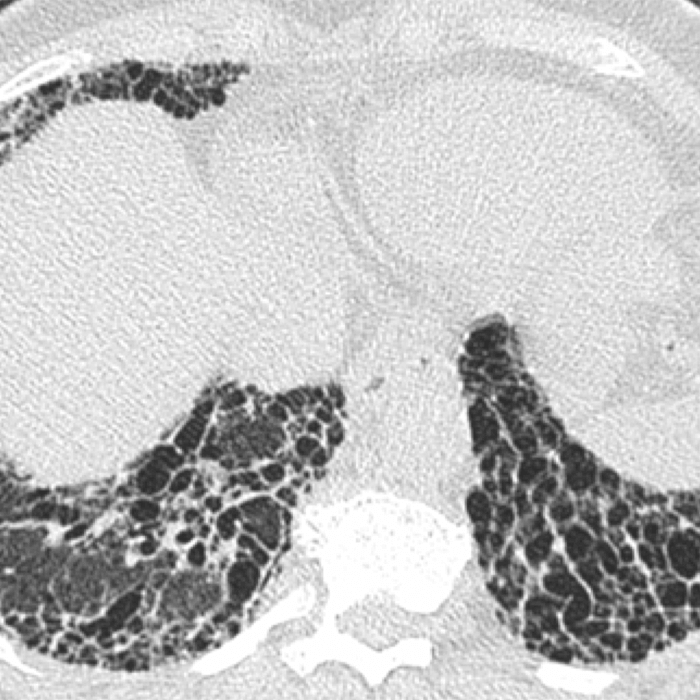

Current methods make fibrotic lung diseases difficult to treat, even with access to a chest CT scan. In addition, the wide range of varied prognoses create issues organizing clinical trials. Finally, patients suffer extreme anxiety—in addition to fibrosis-related symptoms—from the disease’s opaque path of progression.

[Open Source Imaging Consortium (OSIC)](https://www.osicild.org/) is a not-for-profit, co-operative effort between academia, industry and philanthropy. The group enables rapid advances in the fight against Idiopathic Pulmonary Fibrosis (IPF), fibrosing interstitial lung diseases (ILDs), and other respiratory diseases, including emphysematous conditions. Its mission is to bring together radiologists, clinicians and computational scientists from around the world to improve imaging-based treatments.

In this competition, you’ll predict a patient’s severity of decline in lung function based on a CT scan of their lungs. You’ll determine lung function based on output from a spirometer, which measures the volume of air inhaled and exhaled. The challenge is to use machine learning techniques to make a prediction with the image, metadata, and baseline FVC as input.

If successful, patients and their families would better understand their prognosis when they are first diagnosed with this incurable lung disease. Improved severity detection would also positively impact treatment trial design and accelerate the clinical development of novel treatments.

# ----------OSIC Pulmonary Fibrosis Progression Analysis------------

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

In [3]:
# Load Data
df_train = pd.read_csv('../input/osic-pulmonary-fibrosis-progression/train.csv')
df_test = pd.read_csv('../input/osic-pulmonary-fibrosis-progression/test.csv')

In [4]:
# Print Data Shape
print(f'Training Set Shape = {df_train.shape} - Patients = {df_train["Patient"].nunique()}')
print(f'Training Set Memory Usage = {df_train.memory_usage().sum() / 1024 ** 2:.2f} MB')
print(f'Test Set Shape = {df_test.shape} - Patients = {df_test["Patient"].nunique()}')
print(f'Test Set Memory Usage = {df_test.memory_usage().sum() / 1024 ** 2:.2f} MB')

Training Set Shape = (1549, 7) - Patients = 176
Training Set Memory Usage = 0.08 MB
Test Set Shape = (5, 7) - Patients = 5
Test Set Memory Usage = 0.00 MB


Training Set has 176 Patients

In [5]:
# Training Set FVC Measurements Per Patient
training_sample_counts = df_train.rename(columns={'Weeks': 'Samples'}).groupby('Patient').agg('count')['Samples'].value_counts()
print(f'Training Set FVC Measurements Per Patient \n{("-") * 41}\n{training_sample_counts}')

Training Set FVC Measurements Per Patient 
-----------------------------------------
9     132
8      25
10     10
7       7
6       2
Name: Samples, dtype: int64


In [6]:
df_test.head(2)

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus
0,ID00419637202311204720264,6,3020,70.186855,73,Male,Ex-smoker
1,ID00421637202311550012437,15,2739,82.045291,68,Male,Ex-smoker


#### Load Submission Data

In [7]:
df_submission = pd.read_csv( '../input/osic-pulmonary-fibrosis-progression/sample_submission.csv' )
df_submission.head()

,Patient_Week,FVC,Confidence
0,ID00419637202311204720264_-12,2000,100
1,ID00421637202311550012437_-12,2000,100
2,ID00422637202311677017371_-12,2000,100
3,ID00423637202312137826377_-12,2000,100
4,ID00426637202313170790466_-12,2000,100


## Laplace Log Likelihood


`Confidence` values smaller than 70 are clipped.

$\large \sigma_{clipped} = max(\sigma, 70),$

Errors greater than 1000 are also clipped in order to avoid large errors.

$\large \Delta = min ( |FVC_{true} - FVC_{predicted}|, 1000 ),$

The metric is defined as:

$\Large metric = -   \frac{\sqrt{2} \Delta}{\sigma_{clipped}} - \ln ( \sqrt{2} \sigma_{clipped} ).$

FVC Statistical Summary
-----------------------
Mean: 2690.48  -  Median: 2641.0  -  Std: 832.771
Min: 827  -  25%: 2109.0  -  50%: 2641.0  -  75%: 3171.0  -  Max: 6399
Skew: 0.584271  -  Kurtosis: 0.571985
Missing Values: 0/1549 (0.0%)


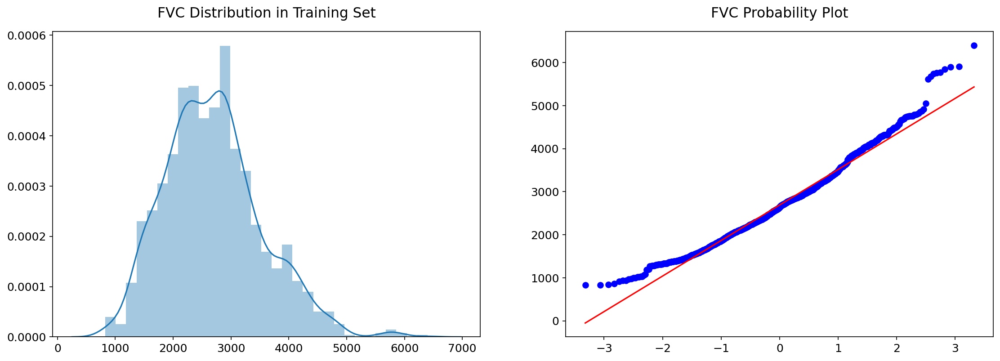

In [8]:
print(f'FVC Statistical Summary\n{"-" * 23}')

print(f'Mean: {df_train["FVC"].mean():.6}  -  Median: {df_train["FVC"].median():.6}  -  Std: {df_train["FVC"].std():.6}')
print(f'Min: {df_train["FVC"].min()}  -  25%: {df_train["FVC"].quantile(0.25)}  -  50%: {df_train["FVC"].quantile(0.5)}  -  75%: {df_train["FVC"].quantile(0.75)}  -  Max: {df_train["FVC"].max()}')
print(f'Skew: {df_train["FVC"].skew():.6}  -  Kurtosis: {df_train["FVC"].kurtosis():.6}')
missing_values_count = df_train[df_train["FVC"].isnull()].shape[0]
training_samples_count = df_train.shape[0]
print(f'Missing Values: {missing_values_count}/{training_samples_count} ({missing_values_count * 100 / training_samples_count:.4}%)')

fig, axes = plt.subplots(ncols=2, figsize=(18, 6), dpi=150)

sns.distplot(df_train['FVC'], label='FVC', ax=axes[0])
stats.probplot(df_train['FVC'], plot=axes[1])

for i in range(2):
    axes[i].tick_params(axis='x', labelsize=12)
    axes[i].tick_params(axis='y', labelsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    
axes[0].set_title(f'FVC Distribution in Training Set', size=15, pad=15)
axes[1].set_title(f'FVC Probability Plot', size=15, pad=15)

plt.show()

Patient: ID00007637202177411956430 FVC Statistical Summary
----------------------------------------------------------
Mean: 2113.89  -  Median: 2069.0  -  Std: 96.8561
Min: 2000 -  Max: 2315
Skew: 1.26267  -  Kurtosis: 1.31481
Change Mean: 77.0  - Change Median: 79.0  - Change Std: 44.8203
Change Min: 7.0 -  Change Max: 153.0
Change Skew: 0.0645445 -  Change Kurtosis: 0.38165


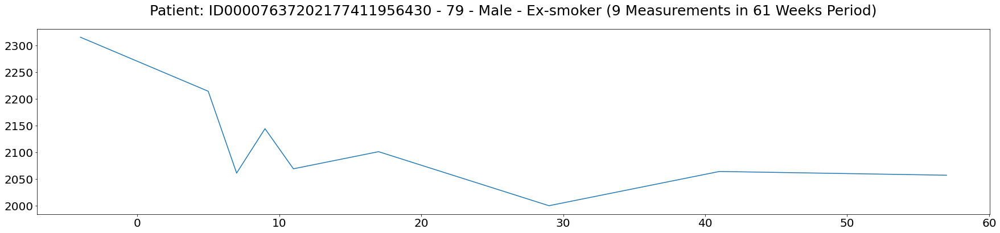

Patient: ID00009637202177434476278 FVC Statistical Summary
----------------------------------------------------------
Mean: 3596.67  -  Median: 3625.0  -  Std: 197.368
Min: 3214 -  Max: 3895
Skew: -0.704114  -  Kurtosis: 1.06018
Change Mean: 138.75  - Change Median: 128.0  - Change Std: 88.4304
Change Min: 47.0 -  Change Max: 285.0
Change Skew: 0.584905 -  Change Kurtosis: -0.892268


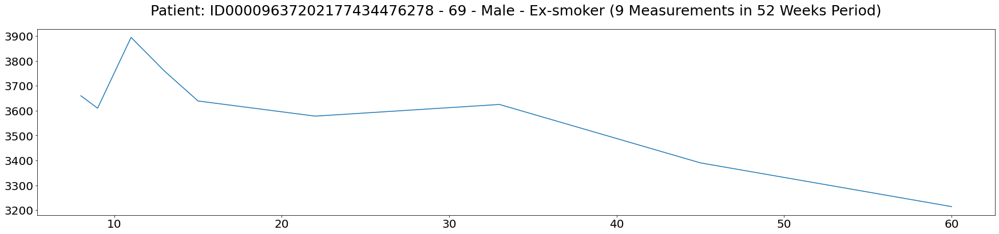

Patient: ID00010637202177584971671 FVC Statistical Summary
----------------------------------------------------------
Mean: 3037.11  -  Median: 3030.0  -  Std: 358.434
Min: 2474 -  Max: 3523
Skew: -0.493364  -  Kurtosis: -0.53517
Change Mean: 164.125  - Change Median: 91.5  - Change Std: 173.523
Change Min: 37.0 -  Change Max: 519.0
Change Skew: 1.57635 -  Change Kurtosis: 1.69317


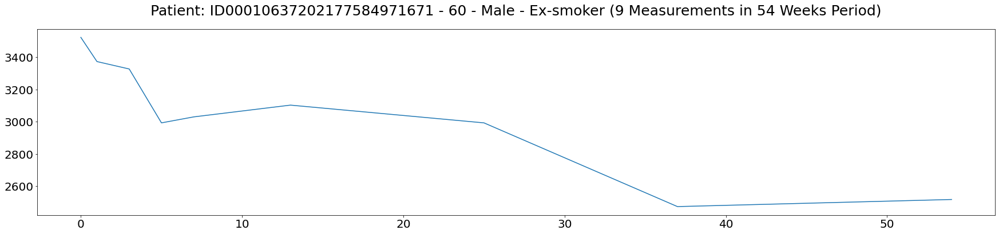

Patient: ID00011637202177653955184 FVC Statistical Summary
----------------------------------------------------------
Mean: 3387.0  -  Median: 3410.0  -  Std: 113.774
Min: 3193 -  Max: 3541
Skew: -0.359377  -  Kurtosis: -0.684807
Change Mean: 106.375  - Change Median: 92.5  - Change Std: 53.5642
Change Min: 39.0 -  Change Max: 208.0
Change Skew: 0.938386 -  Change Kurtosis: 0.734179


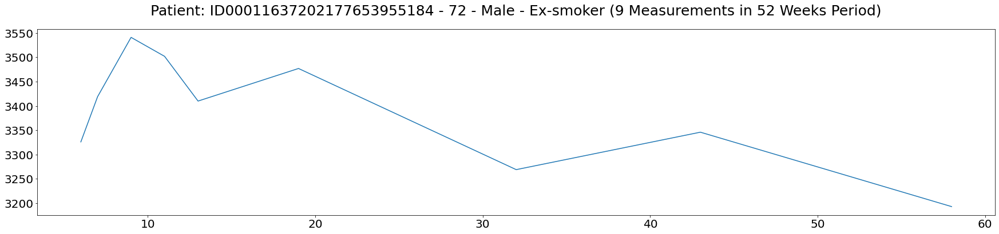

Patient: ID00012637202177665765362 FVC Statistical Summary
----------------------------------------------------------
Mean: 3348.78  -  Median: 3324.0  -  Std: 212.432
Min: 2971 -  Max: 3759
Skew: 0.246968  -  Kurtosis: 1.89361
Change Mean: 228.125  - Change Median: 178.0  - Change Std: 128.947
Change Min: 93.0 -  Change Max: 483.0
Change Skew: 1.24204 -  Change Kurtosis: 1.12295


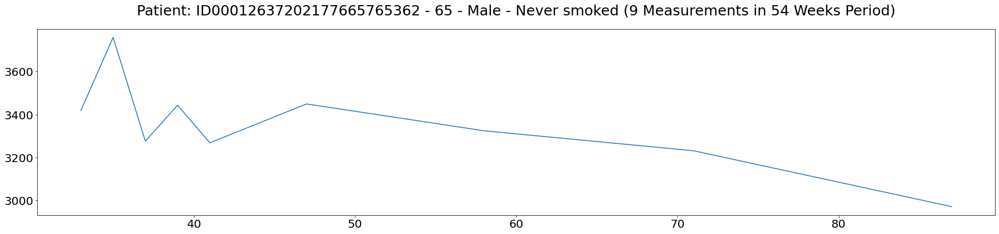

Patient: ID00014637202177757139317 FVC Statistical Summary
----------------------------------------------------------
Mean: 3531.78  -  Median: 3615.0  -  Std: 311.701
Min: 3027 -  Max: 3897
Skew: -0.4614  -  Kurtosis: -1.39173
Change Mean: 217.25  - Change Median: 194.5  - Change Std: 179.708
Change Min: 17.0 -  Change Max: 518.0
Change Skew: 0.594234 -  Change Kurtosis: -0.711456


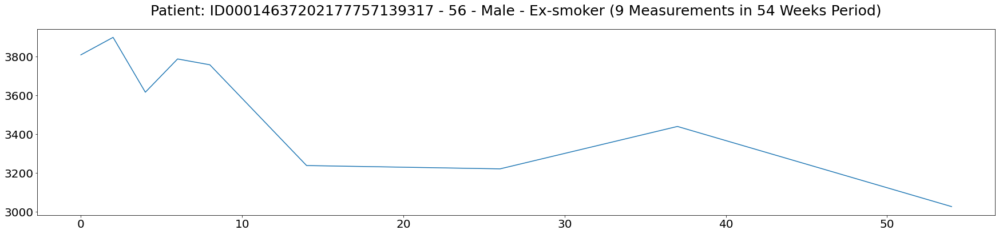

Patient: ID00015637202177877247924 FVC Statistical Summary
----------------------------------------------------------
Mean: 2831.38  -  Median: 2793.5  -  Std: 199.234
Min: 2585 -  Max: 3120
Skew: 0.264544  -  Kurtosis: -1.74341
Change Mean: 173.571  - Change Median: 223.0  - Change Std: 109.163
Change Min: 15.0 -  Change Max: 301.0
Change Skew: -0.361374 -  Change Kurtosis: -1.71954


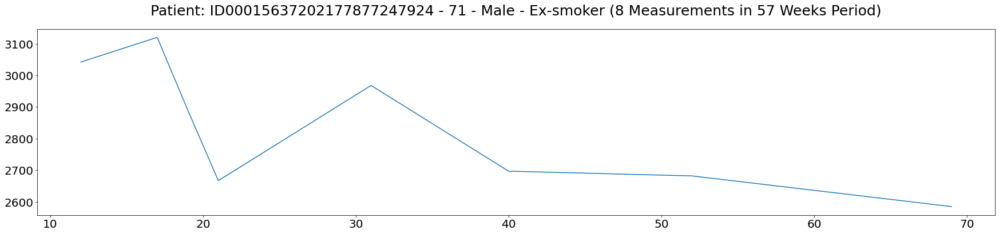

Patient: ID00019637202178323708467 FVC Statistical Summary
----------------------------------------------------------
Mean: 1983.56  -  Median: 2002.0  -  Std: 120.008
Min: 1778 -  Max: 2116
Skew: -0.895475  -  Kurtosis: -0.3489
Change Mean: 82.0  - Change Median: 53.0  - Change Std: 51.3893
Change Min: 30.0 -  Change Max: 170.0
Change Skew: 0.879756 -  Change Kurtosis: -0.86541


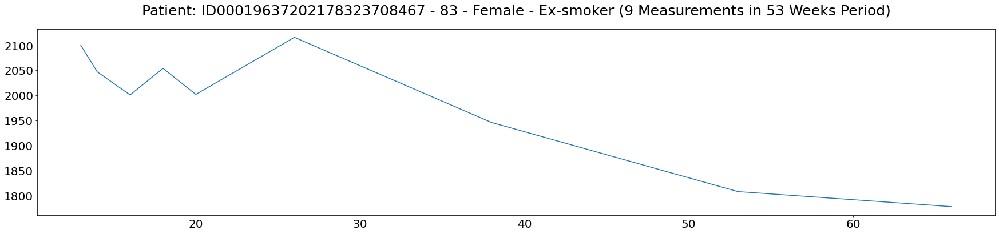

Patient: ID00020637202178344345685 FVC Statistical Summary
----------------------------------------------------------
Mean: 2111.89  -  Median: 2115.0  -  Std: 144.833
Min: 1861 -  Max: 2297
Skew: -0.510957  -  Kurtosis: -0.494864
Change Mean: 85.5  - Change Median: 89.5  - Change Std: 56.2367
Change Min: 5.0 -  Change Max: 154.0
Change Skew: -0.19951 -  Change Kurtosis: -1.30256


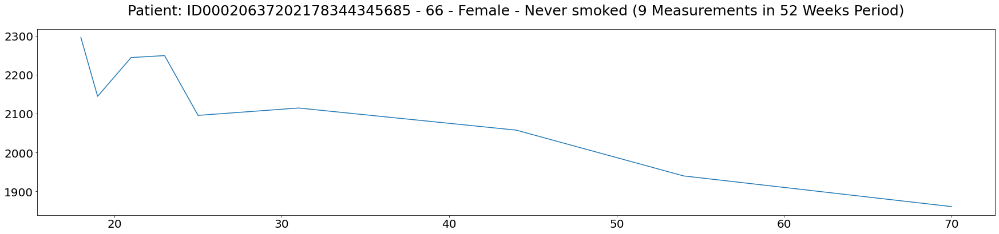

Patient: ID00023637202179104603099 FVC Statistical Summary
----------------------------------------------------------
Mean: 1435.44  -  Median: 1406.0  -  Std: 117.187
Min: 1304 -  Max: 1681
Skew: 1.18797  -  Kurtosis: 1.37093
Change Mean: 121.75  - Change Median: 114.0  - Change Std: 77.8547
Change Min: 7.0 -  Change Max: 220.0
Change Skew: -0.136724 -  Change Kurtosis: -1.05203


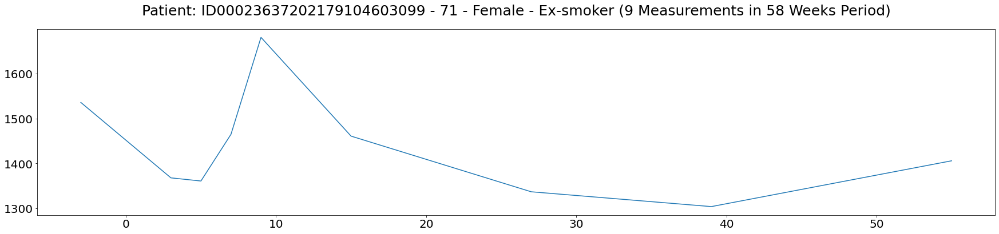

Patient: ID00025637202179541264076 FVC Statistical Summary
----------------------------------------------------------
Mean: 2996.44  -  Median: 3042.0  -  Std: 241.196
Min: 2533 -  Max: 3277
Skew: -0.67619  -  Kurtosis: 0.235146
Change Mean: 198.5  - Change Median: 220.5  - Change Std: 71.3683
Change Min: 69.0 -  Change Max: 278.0
Change Skew: -0.997464 -  Change Kurtosis: 0.0911752


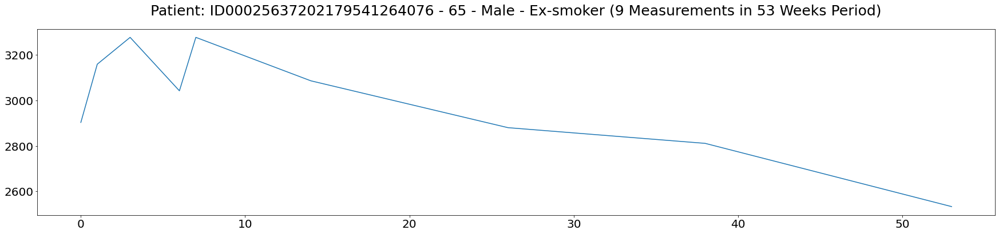

Patient: ID00026637202179561894768 FVC Statistical Summary
----------------------------------------------------------
Mean: 2879.78  -  Median: 2884.0  -  Std: 109.378
Min: 2700 -  Max: 3007
Skew: -0.364128  -  Kurtosis: -1.08872
Change Mean: 116.75  - Change Median: 103.0  - Change Std: 74.0285
Change Min: 26.0 -  Change Max: 241.0
Change Skew: 0.750945 -  Change Kurtosis: -0.322338


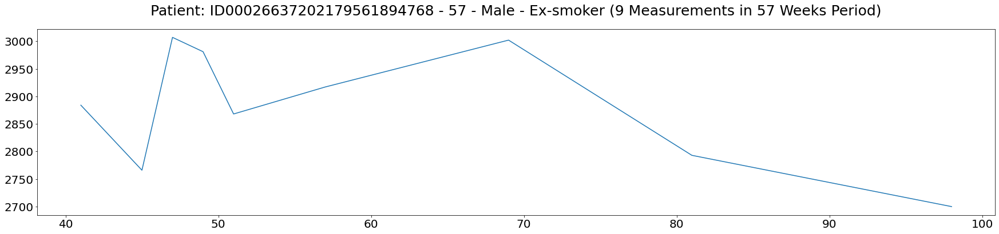

Patient: ID00027637202179689871102 FVC Statistical Summary
----------------------------------------------------------
Mean: 2625.44  -  Median: 2564.0  -  Std: 165.82
Min: 2378 -  Max: 2887
Skew: 0.174214  -  Kurtosis: -0.963079
Change Mean: 144.25  - Change Median: 107.0  - Change Std: 131.602
Change Min: 17.0 -  Change Max: 340.0
Change Skew: 0.653421 -  Change Kurtosis: -1.32864


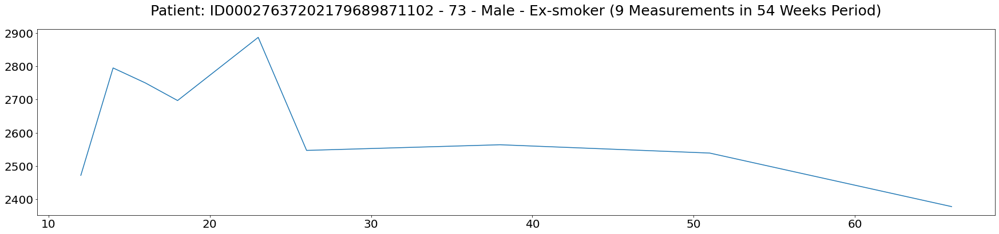

Patient: ID00030637202181211009029 FVC Statistical Summary
----------------------------------------------------------
Mean: 2500.25  -  Median: 2529.0  -  Std: 125.433
Min: 2328 -  Max: 2694
Skew: 0.0130048  -  Kurtosis: -1.05921
Change Mean: 135.714  - Change Median: 99.0  - Change Std: 101.643
Change Min: 43.0 -  Change Max: 306.0
Change Skew: 0.81676 -  Change Kurtosis: -0.697016


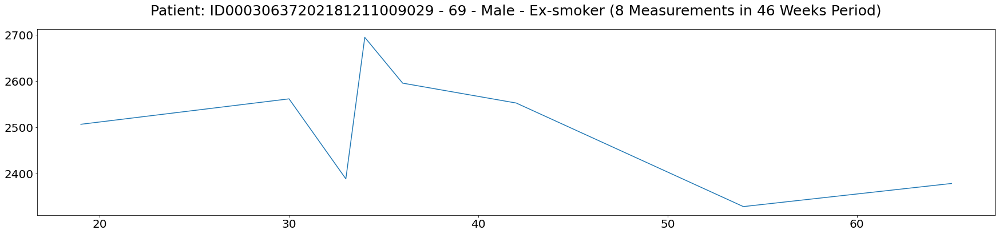

Patient: ID00032637202181710233084 FVC Statistical Summary
----------------------------------------------------------
Mean: 4657.67  -  Median: 4743.0  -  Std: 341.047
Min: 3846 -  Max: 5045
Skew: -1.88392  -  Kurtosis: 4.54743
Change Mean: 248.625  - Change Median: 201.5  - Change Std: 273.881
Change Min: 51.0 -  Change Max: 897.0
Change Skew: 2.35649 -  Change Kurtosis: 6.07397


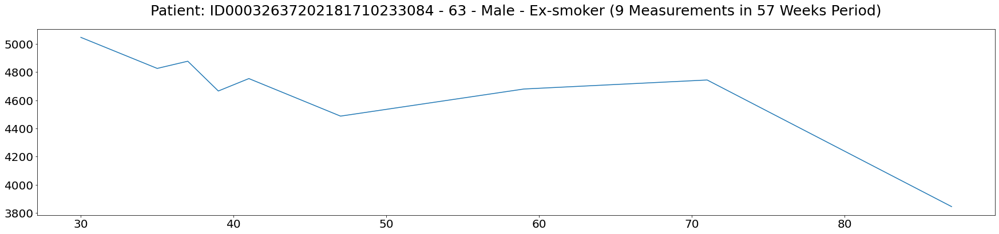

Patient: ID00035637202182204917484 FVC Statistical Summary
----------------------------------------------------------
Mean: 2551.33  -  Median: 2634.0  -  Std: 211.593
Min: 2195 -  Max: 2787
Skew: -0.813192  -  Kurtosis: -0.89946
Change Mean: 122.25  - Change Median: 90.0  - Change Std: 125.475
Change Min: 16.0 -  Change Max: 396.0
Change Skew: 1.75191 -  Change Kurtosis: 3.27088


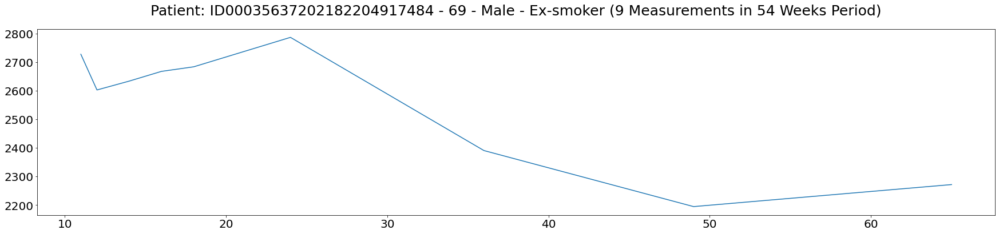

Patient: ID00038637202182690843176 FVC Statistical Summary
----------------------------------------------------------
Mean: 3897.44  -  Median: 3896.0  -  Std: 71.39
Min: 3787 -  Max: 4000
Skew: 0.0671798  -  Kurtosis: -0.870804
Change Mean: 75.75  - Change Median: 36.5  - Change Std: 75.9506
Change Min: 12.0 -  Change Max: 201.0
Change Skew: 0.89106 -  Change Kurtosis: -1.07449


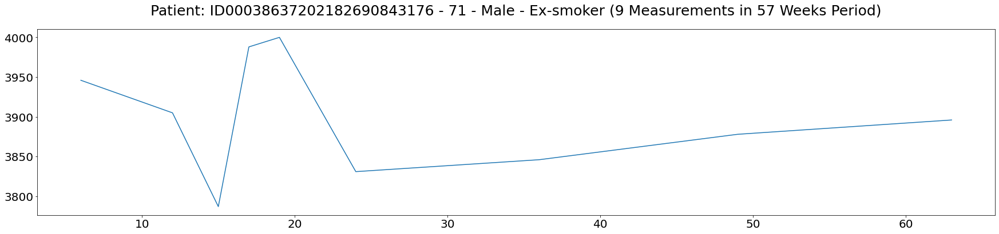

Patient: ID00042637202184406822975 FVC Statistical Summary
----------------------------------------------------------
Mean: 3613.67  -  Median: 3555.0  -  Std: 173.005
Min: 3431 -  Max: 3961
Skew: 1.09275  -  Kurtosis: 0.68498
Change Mean: 200.25  - Change Median: 169.5  - Change Std: 156.21
Change Min: 41.0 -  Change Max: 530.0
Change Skew: 1.45157 -  Change Kurtosis: 2.547


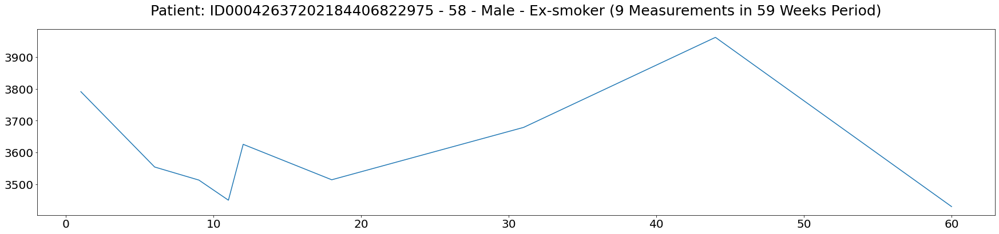

Patient: ID00047637202184938901501 FVC Statistical Summary
----------------------------------------------------------
Mean: 3215.83  -  Median: 3235.5  -  Std: 128.896
Min: 3012 -  Max: 3370
Skew: -0.634159  -  Kurtosis: -0.0688272
Change Mean: 157.0  - Change Median: 135.0  - Change Std: 72.059
Change Min: 78.0 -  Change Max: 241.0
Change Skew: 0.294855 -  Change Kurtosis: -2.65116


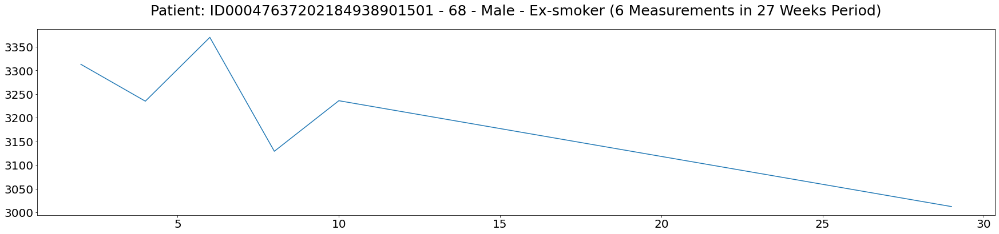

Patient: ID00048637202185016727717 FVC Statistical Summary
----------------------------------------------------------
Mean: 1419.56  -  Median: 1414.0  -  Std: 39.7244
Min: 1370 -  Max: 1477
Skew: 0.171177  -  Kurtosis: -1.60311
Change Mean: 42.875  - Change Median: 27.0  - Change Std: 31.211
Change Min: 17.0 -  Change Max: 102.0
Change Skew: 1.28753 -  Change Kurtosis: 0.427754


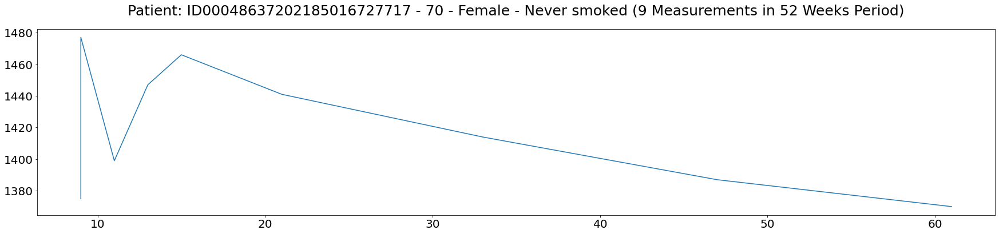

Patient: ID00051637202185848464638 FVC Statistical Summary
----------------------------------------------------------
Mean: 1637.11  -  Median: 1624.0  -  Std: 87.6462
Min: 1520 -  Max: 1776
Skew: 0.0999137  -  Kurtosis: -1.10463
Change Mean: 75.375  - Change Median: 58.0  - Change Std: 66.7938
Change Min: 8.0 -  Change Max: 207.0
Change Skew: 1.15248 -  Change Kurtosis: 1.08297


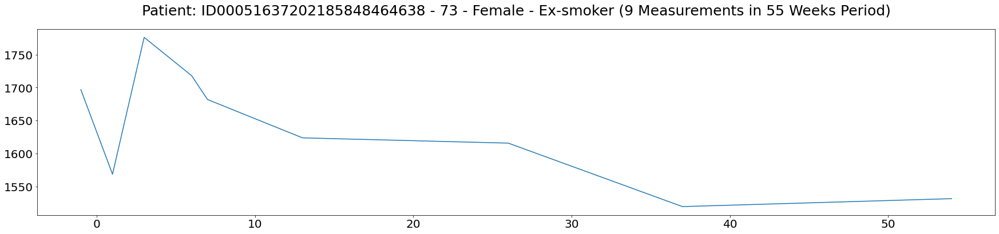

Patient: ID00052637202186188008618 FVC Statistical Summary
----------------------------------------------------------
Mean: 2336.43  -  Median: 2436.0  -  Std: 240.856
Min: 1848 -  Max: 2522
Skew: -1.67688  -  Kurtosis: 2.90046
Change Mean: 179.5  - Change Median: 113.0  - Change Std: 219.12
Change Min: 5.0 -  Change Max: 588.0
Change Skew: 1.62956 -  Change Kurtosis: 2.73995


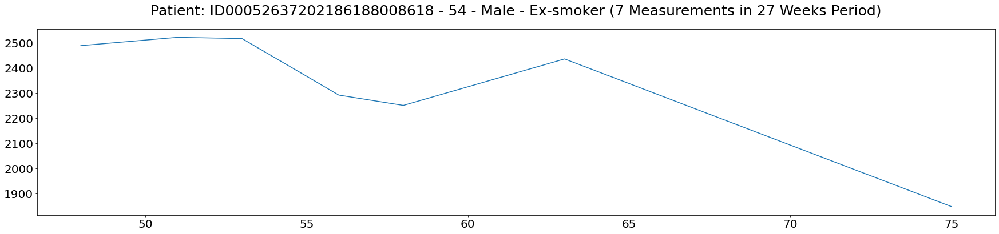

Patient: ID00060637202187965290703 FVC Statistical Summary
----------------------------------------------------------
Mean: 3195.33  -  Median: 3255.0  -  Std: 171.79
Min: 2890 -  Max: 3418
Skew: -0.502095  -  Kurtosis: -0.573541
Change Mean: 146.875  - Change Median: 145.5  - Change Std: 65.2434
Change Min: 48.0 -  Change Max: 234.0
Change Skew: -0.0149456 -  Change Kurtosis: -0.87382


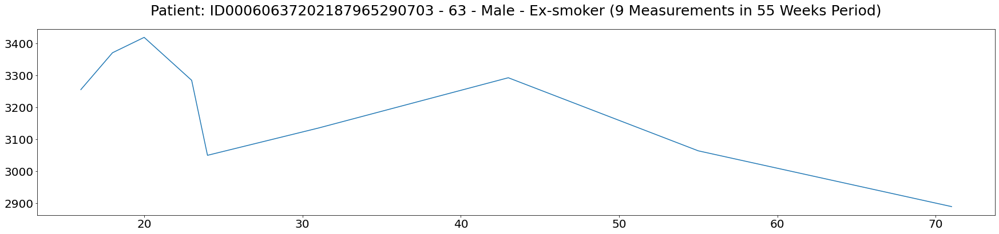

Patient: ID00061637202188184085559 FVC Statistical Summary
----------------------------------------------------------
Mean: 3872.0  -  Median: 4043.0  -  Std: 515.657
Min: 2511 -  Max: 4134
Skew: -2.88473  -  Kurtosis: 8.47876
Change Mean: 463.5  - Change Median: 148.5  - Change Std: 670.412
Change Min: 5.0 -  Change Max: 1623.0
Change Skew: 1.40535 -  Change Kurtosis: 0.0478326


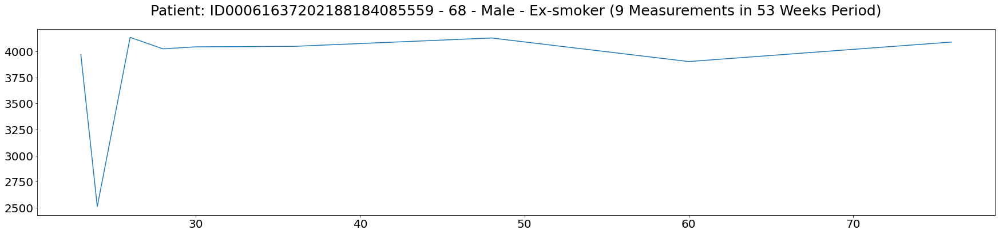

Patient: ID00062637202188654068490 FVC Statistical Summary
----------------------------------------------------------
Mean: 2232.22  -  Median: 2239.0  -  Std: 89.2241
Min: 2071 -  Max: 2341
Skew: -0.469323  -  Kurtosis: -0.352358
Change Mean: 71.0  - Change Median: 57.5  - Change Std: 56.7425
Change Min: 5.0 -  Change Max: 183.0
Change Skew: 1.07403 -  Change Kurtosis: 1.17783


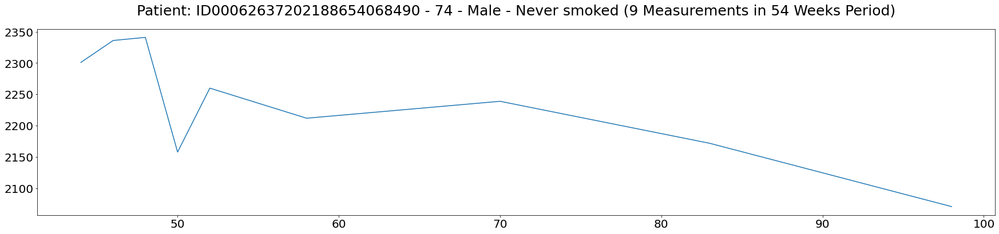

Patient: ID00067637202189903532242 FVC Statistical Summary
----------------------------------------------------------
Mean: 3379.75  -  Median: 3386.5  -  Std: 122.853
Min: 3230 -  Max: 3608
Skew: 0.673985  -  Kurtosis: 0.428985
Change Mean: 135.143  - Change Median: 154.0  - Change Std: 77.1048
Change Min: 26.0 -  Change Max: 245.0
Change Skew: -0.248643 -  Change Kurtosis: -0.695664


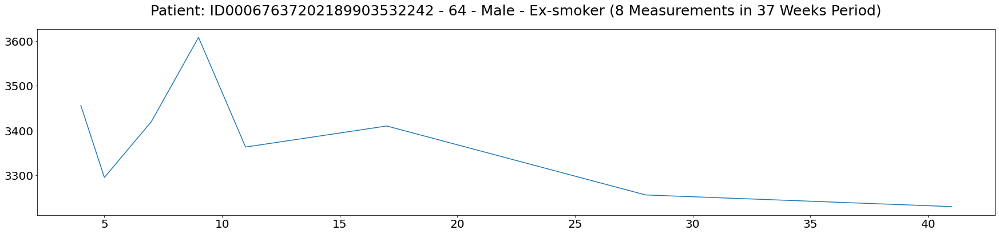

Patient: ID00068637202190879923934 FVC Statistical Summary
----------------------------------------------------------
Mean: 2679.67  -  Median: 2740.0  -  Std: 145.541
Min: 2459 -  Max: 2827
Skew: -0.587436  -  Kurtosis: -1.40161
Change Mean: 109.5  - Change Median: 106.0  - Change Std: 70.5084
Change Min: 33.0 -  Change Max: 227.0
Change Skew: 0.456776 -  Change Kurtosis: -1.04881


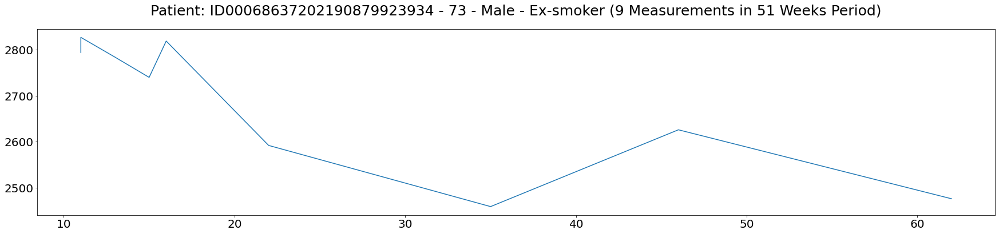

Patient: ID00072637202198161894406 FVC Statistical Summary
----------------------------------------------------------
Mean: 2333.56  -  Median: 2356.0  -  Std: 59.7602
Min: 2233 -  Max: 2414
Skew: -0.781601  -  Kurtosis: -0.265866
Change Mean: 65.0  - Change Median: 68.5  - Change Std: 46.0683
Change Min: 2.0 -  Change Max: 123.0
Change Skew: -0.128804 -  Change Kurtosis: -1.78233


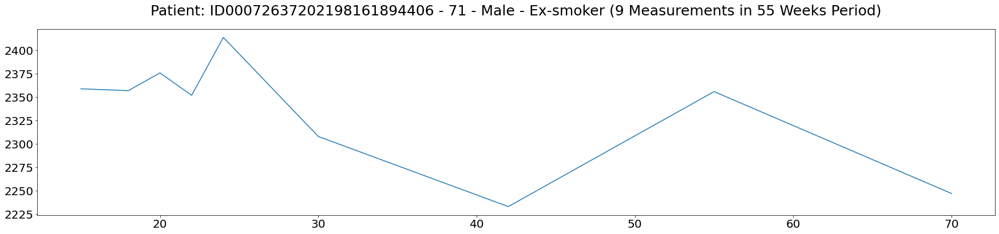

Patient: ID00073637202198167792918 FVC Statistical Summary
----------------------------------------------------------
Mean: 2284.12  -  Median: 2357.5  -  Std: 259.285
Min: 1709 -  Max: 2547
Skew: -1.86489  -  Kurtosis: 3.84822
Change Mean: 135.714  - Change Median: 57.0  - Change Std: 144.812
Change Min: 7.0 -  Change Max: 421.0
Change Skew: 1.54303 -  Change Kurtosis: 2.12847


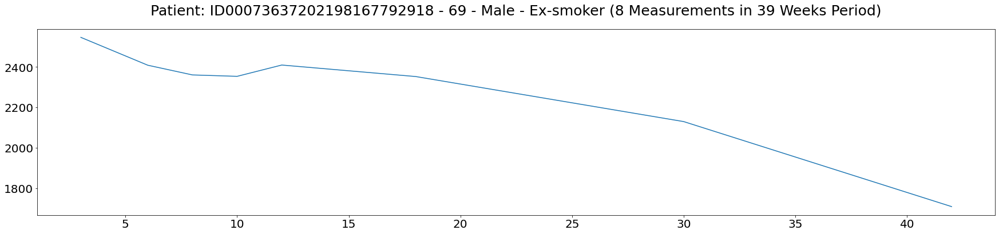

Patient: ID00075637202198610425520 FVC Statistical Summary
----------------------------------------------------------
Mean: 1501.33  -  Median: 1541.0  -  Std: 160.2
Min: 1185 -  Max: 1641
Skew: -1.28511  -  Kurtosis: 0.600416
Change Mean: 80.5  - Change Median: 92.0  - Change Std: 66.9669
Change Min: 2.0 -  Change Max: 173.0
Change Skew: 0.0241744 -  Change Kurtosis: -1.64346


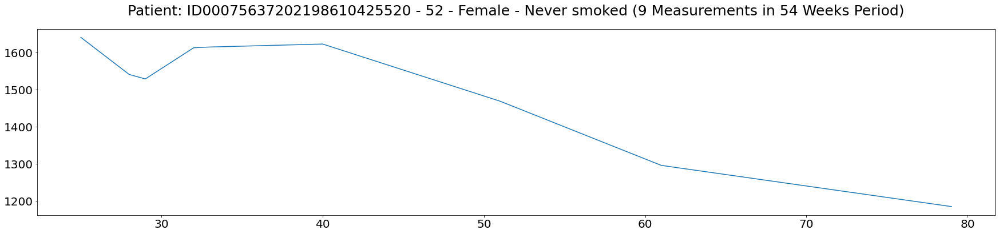

Patient: ID00076637202199015035026 FVC Statistical Summary
----------------------------------------------------------
Mean: 2525.56  -  Median: 2480.0  -  Std: 251.122
Min: 2182 -  Max: 2914
Skew: 0.386445  -  Kurtosis: -1.0276
Change Mean: 184.125  - Change Median: 197.5  - Change Std: 124.542
Change Min: 4.0 -  Change Max: 394.0
Change Skew: 0.203515 -  Change Kurtosis: -0.146536


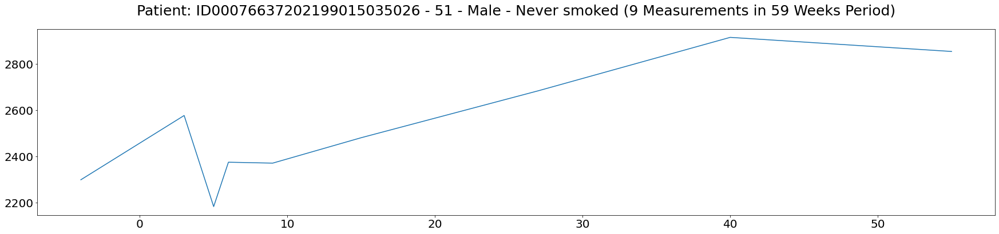

Patient: ID00077637202199102000916 FVC Statistical Summary
----------------------------------------------------------
Mean: 3312.56  -  Median: 3378.0  -  Std: 125.568
Min: 3121 -  Max: 3504
Skew: -0.183914  -  Kurtosis: -1.0237
Change Mean: 102.625  - Change Median: 119.0  - Change Std: 48.0087
Change Min: 13.0 -  Change Max: 157.0
Change Skew: -1.12079 -  Change Kurtosis: 0.478534


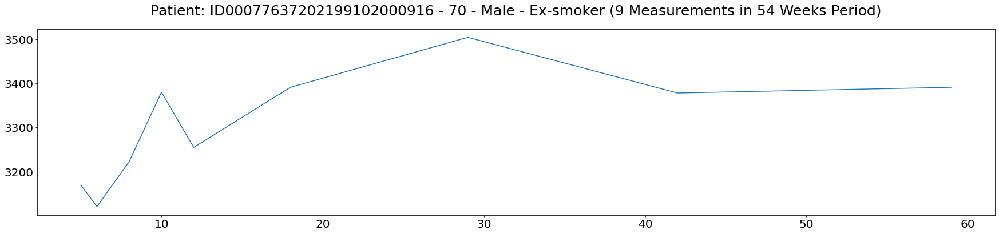

Patient: ID00078637202199415319443 FVC Statistical Summary
----------------------------------------------------------
Mean: 1753.56  -  Median: 1780.0  -  Std: 149.099
Min: 1385 -  Max: 1901
Skew: -2.19394  -  Kurtosis: 5.77073
Change Mean: 76.375  - Change Median: 43.0  - Change Std: 105.373
Change Min: 17.0 -  Change Max: 333.0
Change Skew: 2.65753 -  Change Kurtosis: 7.24279


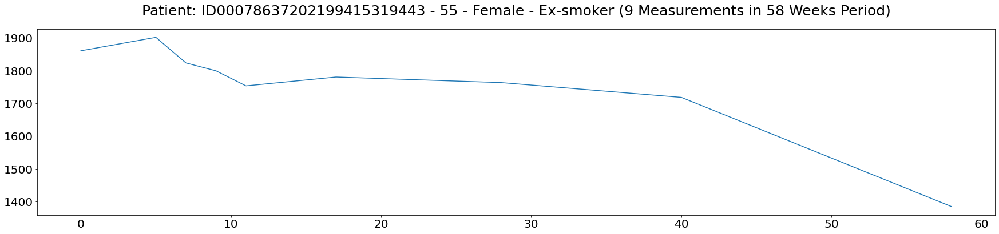

Patient: ID00082637202201836229724 FVC Statistical Summary
----------------------------------------------------------
Mean: 2915.33  -  Median: 2918.0  -  Std: 49.5278
Min: 2837 -  Max: 2975
Skew: -0.257369  -  Kurtosis: -1.5585
Change Mean: 71.625  - Change Median: 80.0  - Change Std: 37.0942
Change Min: 18.0 -  Change Max: 138.0
Change Skew: 0.344139 -  Change Kurtosis: 0.454143


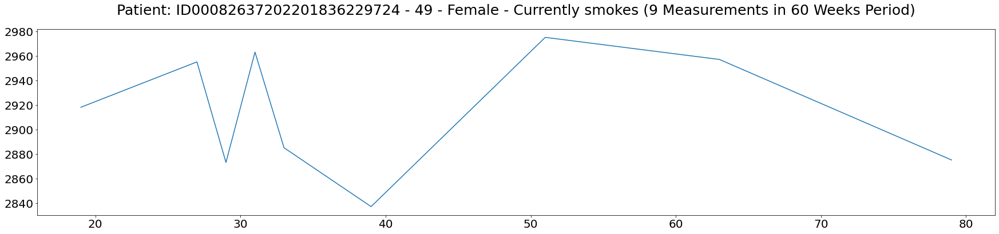

Patient: ID00086637202203494931510 FVC Statistical Summary
----------------------------------------------------------
Mean: 3359.67  -  Median: 3367.0  -  Std: 123.501
Min: 3076 -  Max: 3486
Skew: -1.63484  -  Kurtosis: 3.3842
Change Mean: 147.0  - Change Median: 115.5  - Change Std: 131.966
Change Min: 18.0 -  Change Max: 410.0
Change Skew: 1.35981 -  Change Kurtosis: 1.30863


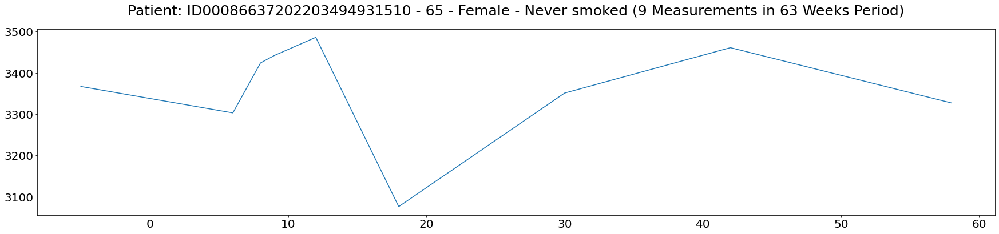

Patient: ID00089637202204675567570 FVC Statistical Summary
----------------------------------------------------------
Mean: 2295.78  -  Median: 2297.0  -  Std: 244.581
Min: 1918 -  Max: 2571
Skew: -0.351537  -  Kurtosis: -1.56901
Change Mean: 93.25  - Change Median: 60.5  - Change Std: 65.1718
Change Min: 32.0 -  Change Max: 214.0
Change Skew: 1.15162 -  Change Kurtosis: 0.0978518


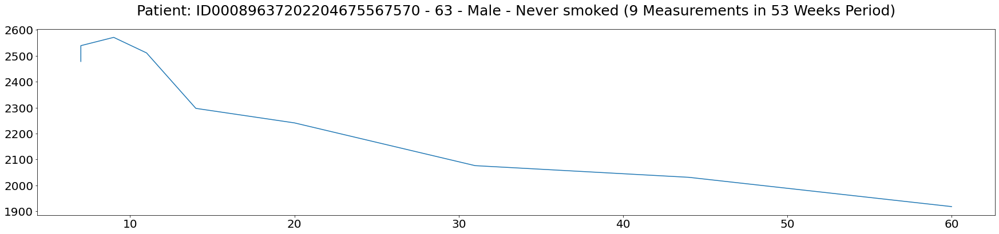

Patient: ID00090637202204766623410 FVC Statistical Summary
----------------------------------------------------------
Mean: 3028.38  -  Median: 2963.5  -  Std: 220.23
Min: 2877 -  Max: 3562
Skew: 2.59495  -  Kurtosis: 7.03844
Change Mean: 120.714  - Change Median: 66.0  - Change Std: 187.009
Change Min: 11.0 -  Change Max: 538.0
Change Skew: 2.4722 -  Change Kurtosis: 6.29678


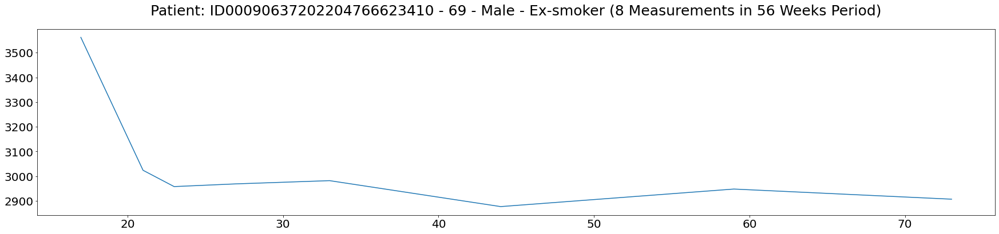

Patient: ID00093637202205278167493 FVC Statistical Summary
----------------------------------------------------------
Mean: 3577.44  -  Median: 3668.0  -  Std: 342.147
Min: 2728 -  Max: 3841
Skew: -2.2722  -  Kurtosis: 5.83411
Change Mean: 347.625  - Change Median: 233.0  - Change Std: 299.85
Change Min: 40.0 -  Change Max: 864.0
Change Skew: 1.0757 -  Change Kurtosis: -0.26091


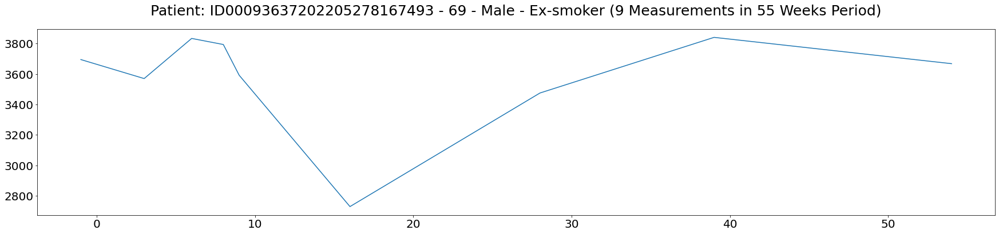

Patient: ID00094637202205333947361 FVC Statistical Summary
----------------------------------------------------------
Mean: 4759.56  -  Median: 4753.0  -  Std: 96.7627
Min: 4574 -  Max: 4916
Skew: -0.34068  -  Kurtosis: 1.21703
Change Mean: 110.5  - Change Median: 117.5  - Change Std: 63.671
Change Min: 3.0 -  Change Max: 179.0
Change Skew: -0.502778 -  Change Kurtosis: -0.827833


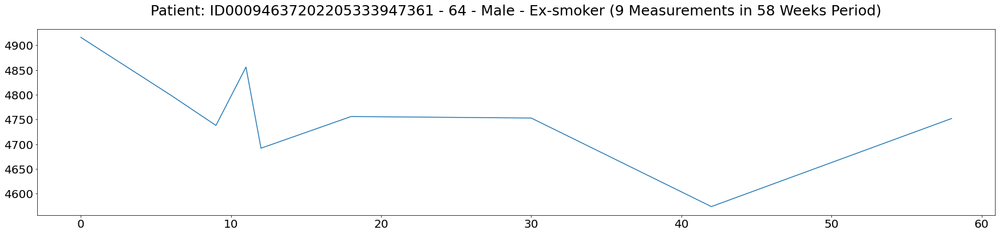

Patient: ID00099637202206203080121 FVC Statistical Summary
----------------------------------------------------------
Mean: 2913.2  -  Median: 2900.0  -  Std: 126.798
Min: 2708 -  Max: 3089
Skew: -0.136489  -  Kurtosis: -1.0672
Change Mean: 95.0  - Change Median: 68.0  - Change Std: 81.2019
Change Min: 4.0 -  Change Max: 232.0
Change Skew: 0.733086 -  Change Kurtosis: -0.898212


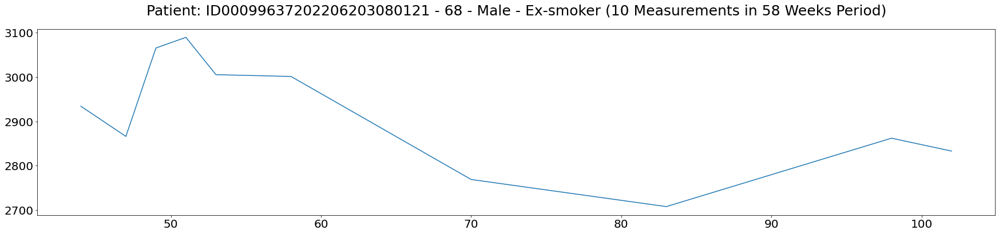

Patient: ID00102637202206574119190 FVC Statistical Summary
----------------------------------------------------------
Mean: 2275.22  -  Median: 2336.0  -  Std: 270.333
Min: 1651 -  Max: 2553
Skew: -1.69144  -  Kurtosis: 3.54364
Change Mean: 233.375  - Change Median: 178.0  - Change Std: 188.563
Change Min: 43.0 -  Change Max: 545.0
Change Skew: 0.890941 -  Change Kurtosis: -0.654787


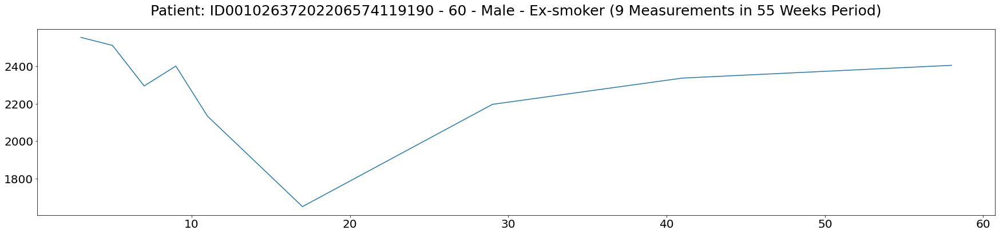

Patient: ID00104637202208063407045 FVC Statistical Summary
----------------------------------------------------------
Mean: 2188.0  -  Median: 2271.0  -  Std: 227.059
Min: 1733 -  Max: 2381
Skew: -1.25855  -  Kurtosis: 1.20074
Change Mean: 104.0  - Change Median: 53.0  - Change Std: 105.122
Change Min: 7.0 -  Change Max: 303.0
Change Skew: 1.3308 -  Change Kurtosis: 1.2309


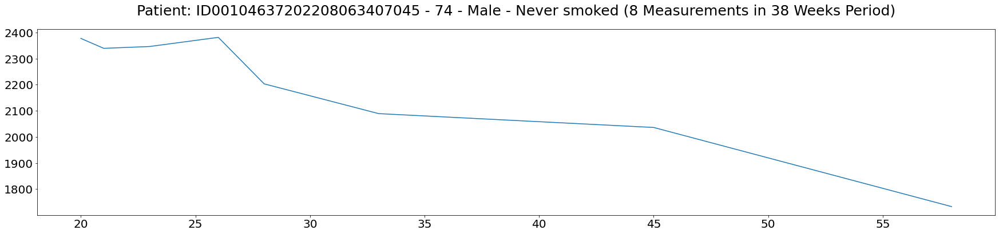

Patient: ID00105637202208831864134 FVC Statistical Summary
----------------------------------------------------------
Mean: 2389.1  -  Median: 2413.0  -  Std: 144.162
Min: 2076 -  Max: 2547
Skew: -1.23155  -  Kurtosis: 1.34751
Change Mean: 77.8889  - Change Median: 81.0  - Change Std: 44.0297
Change Min: 24.0 -  Change Max: 161.0
Change Skew: 0.605612 -  Change Kurtosis: 0.208716


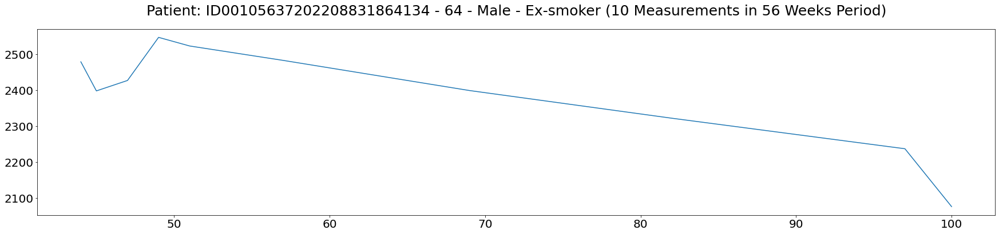

Patient: ID00108637202209619669361 FVC Statistical Summary
----------------------------------------------------------
Mean: 2742.11  -  Median: 2707.0  -  Std: 103.538
Min: 2611 -  Max: 2914
Skew: 0.410813  -  Kurtosis: -1.12559
Change Mean: 82.125  - Change Median: 65.5  - Change Std: 68.6366
Change Min: 13.0 -  Change Max: 183.0
Change Skew: 0.444814 -  Change Kurtosis: -1.7399


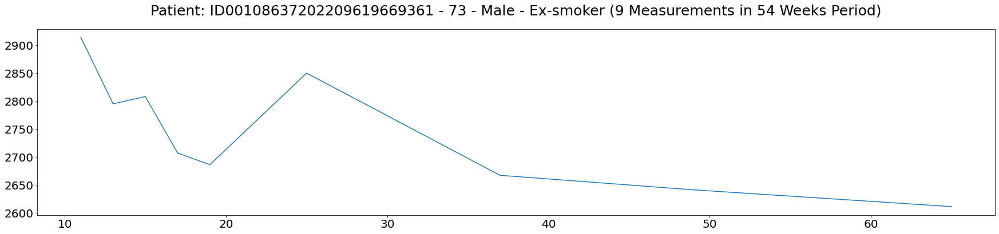

Patient: ID00109637202210454292264 FVC Statistical Summary
----------------------------------------------------------
Mean: 2148.44  -  Median: 2186.0  -  Std: 178.985
Min: 1725 -  Max: 2327
Skew: -1.86175  -  Kurtosis: 4.22484
Change Mean: 139.25  - Change Median: 93.5  - Change Std: 112.865
Change Min: 41.0 -  Change Max: 387.0
Change Skew: 1.85057 -  Change Kurtosis: 3.41952


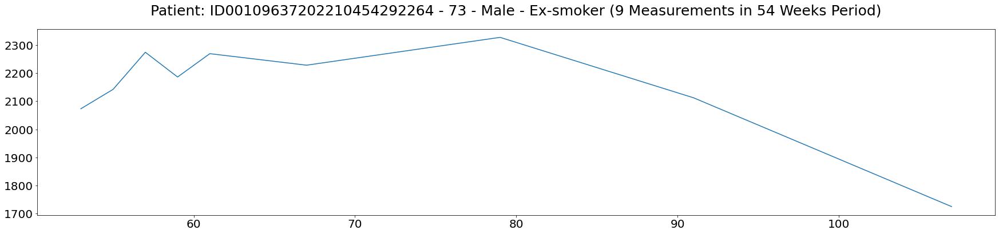

Patient: ID00110637202210673668310 FVC Statistical Summary
----------------------------------------------------------
Mean: 1451.12  -  Median: 1491.0  -  Std: 439.813
Min: 919 -  Max: 1995
Skew: -0.0911713  -  Kurtosis: -2.07405
Change Mean: 153.714  - Change Median: 140.0  - Change Std: 108.351
Change Min: 19.0 -  Change Max: 350.0
Change Skew: 0.929002 -  Change Kurtosis: 0.984735


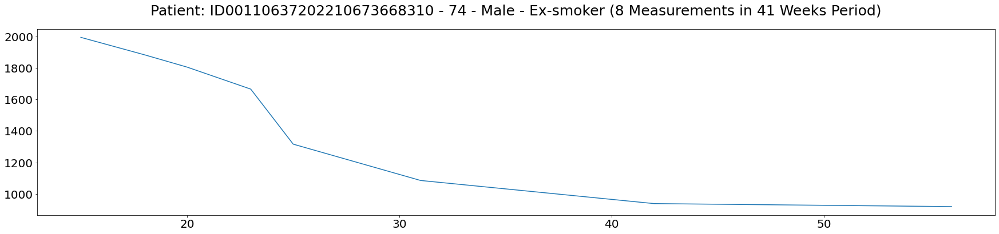

Patient: ID00111637202210956877205 FVC Statistical Summary
----------------------------------------------------------
Mean: 2283.14  -  Median: 2275.0  -  Std: 126.618
Min: 2083 -  Max: 2419
Skew: -0.448912  -  Kurtosis: -1.09424
Change Mean: 92.3333  - Change Median: 67.0  - Change Std: 79.5102
Change Min: 19.0 -  Change Max: 219.0
Change Skew: 0.874259 -  Change Kurtosis: -0.61692


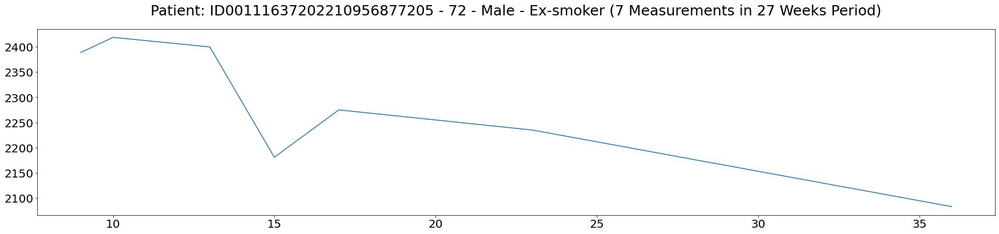

Patient: ID00115637202211874187958 FVC Statistical Summary
----------------------------------------------------------
Mean: 2405.25  -  Median: 2476.5  -  Std: 168.129
Min: 2134 -  Max: 2548
Skew: -1.10946  -  Kurtosis: -0.491499
Change Mean: 144.286  - Change Median: 108.0  - Change Std: 135.633
Change Min: 22.0 -  Change Max: 351.0
Change Skew: 0.857128 -  Change Kurtosis: -1.10695


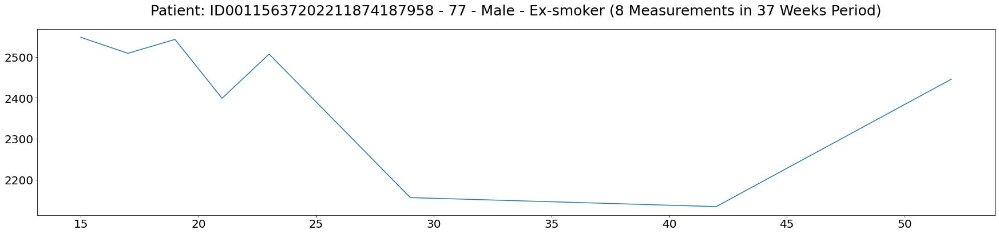

Patient: ID00117637202212360228007 FVC Statistical Summary
----------------------------------------------------------
Mean: 2921.67  -  Median: 2912.0  -  Std: 86.0247
Min: 2788 -  Max: 3037
Skew: -0.0613731  -  Kurtosis: -1.09148
Change Mean: 102.25  - Change Median: 87.5  - Change Std: 60.116
Change Min: 34.0 -  Change Max: 234.0
Change Skew: 1.66492 -  Change Kurtosis: 3.65356


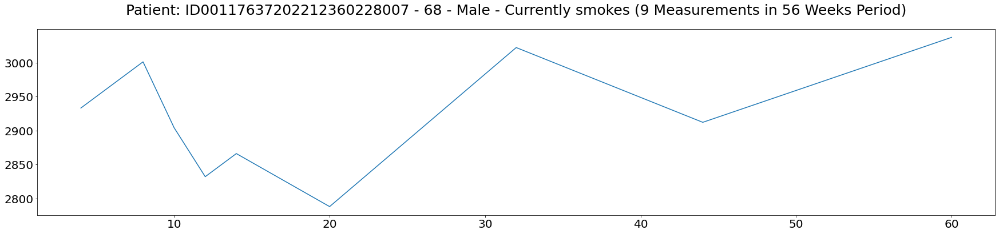

Patient: ID00119637202215426335765 FVC Statistical Summary
----------------------------------------------------------
Mean: 2916.4  -  Median: 2906.5  -  Std: 42.122
Min: 2851 -  Max: 2994
Skew: 0.528305  -  Kurtosis: 0.0243999
Change Mean: 53.8889  - Change Median: 64.0  - Change Std: 31.7783
Change Min: 13.0 -  Change Max: 95.0
Change Skew: -0.327291 -  Change Kurtosis: -1.59453


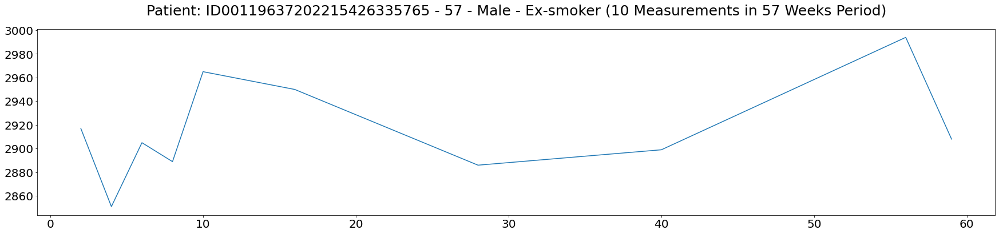

Patient: ID00122637202216437668965 FVC Statistical Summary
----------------------------------------------------------
Mean: 2296.89  -  Median: 2279.0  -  Std: 157.33
Min: 2091 -  Max: 2581
Skew: 0.466985  -  Kurtosis: -0.348351
Change Mean: 63.5  - Change Median: 60.0  - Change Std: 48.3292
Change Min: 9.0 -  Change Max: 154.0
Change Skew: 0.917438 -  Change Kurtosis: 0.423985


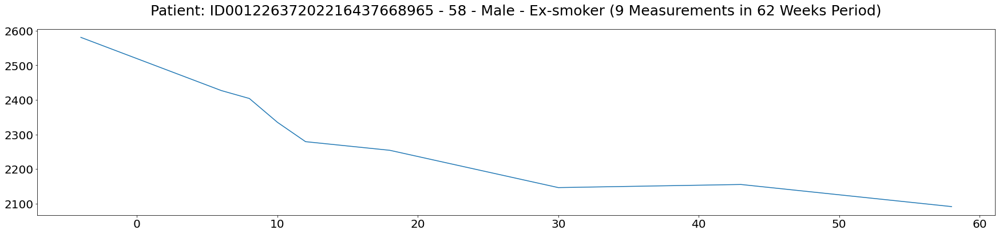

Patient: ID00123637202217151272140 FVC Statistical Summary
----------------------------------------------------------
Mean: 1588.56  -  Median: 1586.0  -  Std: 121.788
Min: 1406 -  Max: 1766
Skew: -0.167779  -  Kurtosis: -1.22298
Change Mean: 76.5  - Change Median: 80.5  - Change Std: 38.9579
Change Min: 0.0 -  Change Max: 132.0
Change Skew: -0.906129 -  Change Kurtosis: 1.77055


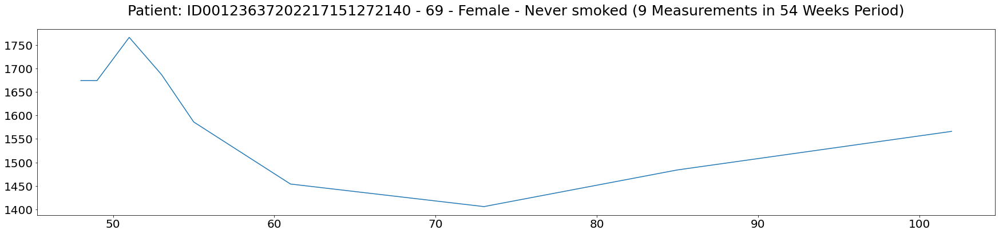

Patient: ID00124637202217596410344 FVC Statistical Summary
----------------------------------------------------------
Mean: 3493.22  -  Median: 3559.0  -  Std: 163.306
Min: 3146 -  Max: 3661
Skew: -1.31806  -  Kurtosis: 1.54761
Change Mean: 109.375  - Change Median: 116.5  - Change Std: 62.833
Change Min: 28.0 -  Change Max: 204.0
Change Skew: 0.0590665 -  Change Kurtosis: -1.37231


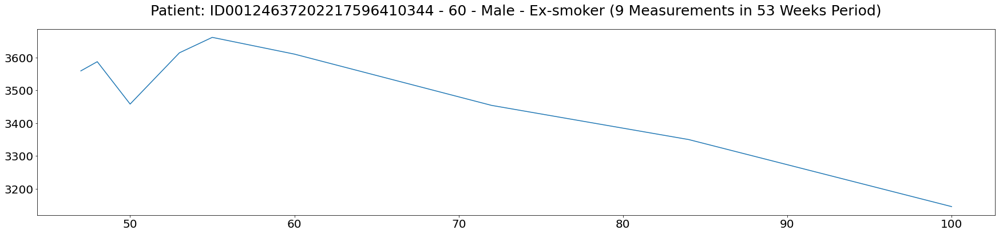

Patient: ID00125637202218590429387 FVC Statistical Summary
----------------------------------------------------------
Mean: 2239.0  -  Median: 2325.0  -  Std: 225.68
Min: 1872 -  Max: 2584
Skew: -0.289178  -  Kurtosis: -0.256422
Change Mean: 135.286  - Change Median: 155.0  - Change Std: 106.597
Change Min: 7.0 -  Change Max: 247.0
Change Skew: -0.239952 -  Change Kurtosis: -2.27077


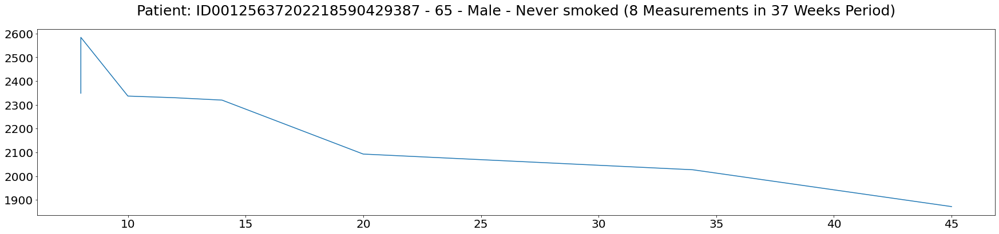

Patient: ID00126637202218610655908 FVC Statistical Summary
----------------------------------------------------------
Mean: 2308.56  -  Median: 2295.0  -  Std: 69.4732
Min: 2227 -  Max: 2455
Skew: 1.23529  -  Kurtosis: 1.65736
Change Mean: 54.0  - Change Median: 34.5  - Change Std: 51.5807
Change Min: 5.0 -  Change Max: 148.0
Change Skew: 0.887034 -  Change Kurtosis: -0.289844


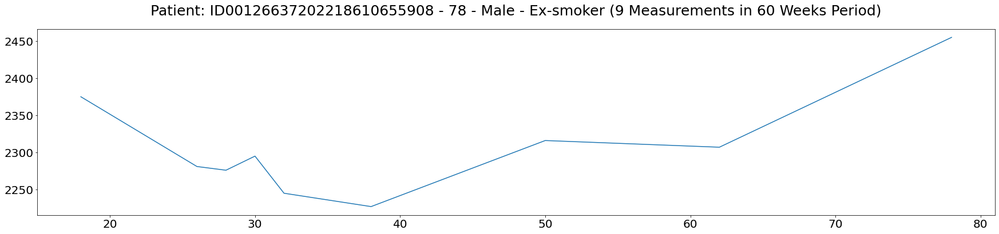

Patient: ID00127637202219096738943 FVC Statistical Summary
----------------------------------------------------------
Mean: 1664.44  -  Median: 1667.0  -  Std: 96.155
Min: 1533 -  Max: 1781
Skew: -0.0337982  -  Kurtosis: -1.56774
Change Mean: 46.25  - Change Median: 37.5  - Change Std: 40.6545
Change Min: 2.0 -  Change Max: 104.0
Change Skew: 0.598737 -  Change Kurtosis: -1.24403


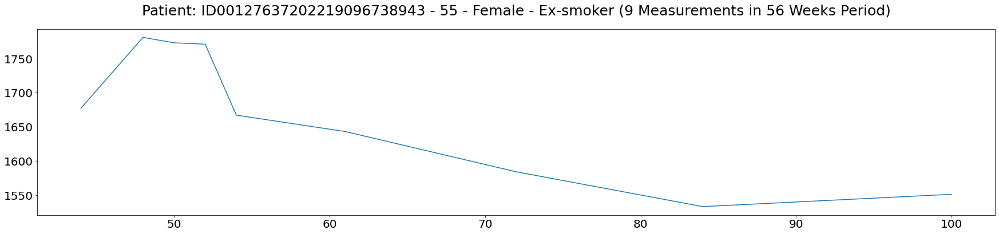

Patient: ID00128637202219474716089 FVC Statistical Summary
----------------------------------------------------------
Mean: 2175.43  -  Median: 2193.0  -  Std: 86.2513
Min: 2024 -  Max: 2274
Skew: -0.921702  -  Kurtosis: 0.264962
Change Mean: 73.0  - Change Median: 66.0  - Change Std: 42.4547
Change Min: 19.0 -  Change Max: 139.0
Change Skew: 0.499303 -  Change Kurtosis: -0.102342


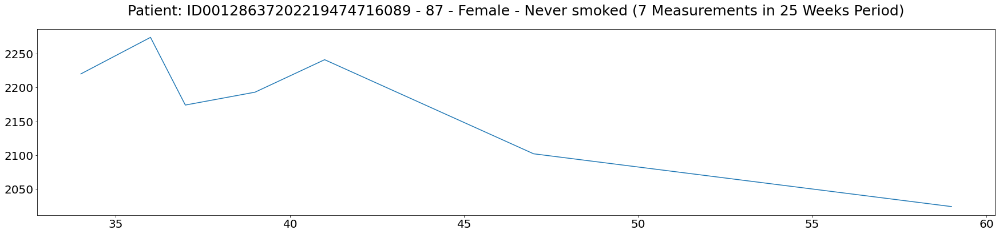

Patient: ID00129637202219868188000 FVC Statistical Summary
----------------------------------------------------------
Mean: 2234.22  -  Median: 2235.0  -  Std: 68.3077
Min: 2134 -  Max: 2333
Skew: -0.0191096  -  Kurtosis: -0.921363
Change Mean: 65.375  - Change Median: 68.0  - Change Std: 24.4069
Change Min: 20.0 -  Change Max: 98.0
Change Skew: -0.643579 -  Change Kurtosis: 0.667732


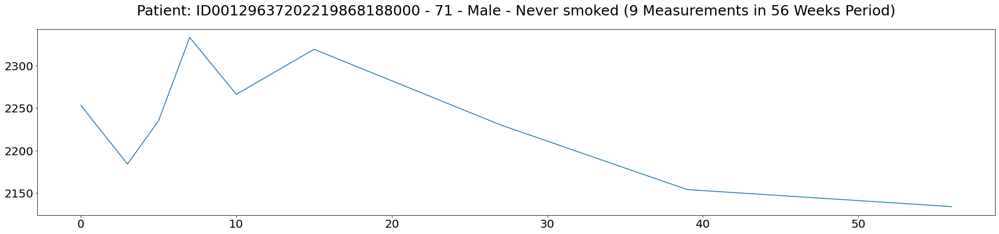

Patient: ID00130637202220059448013 FVC Statistical Summary
----------------------------------------------------------
Mean: 1482.33  -  Median: 1503.0  -  Std: 155.689
Min: 1197 -  Max: 1690
Skew: -0.490225  -  Kurtosis: -0.131234
Change Mean: 70.125  - Change Median: 52.5  - Change Std: 41.2152
Change Min: 34.0 -  Change Max: 154.0
Change Skew: 1.38609 -  Change Kurtosis: 1.51121


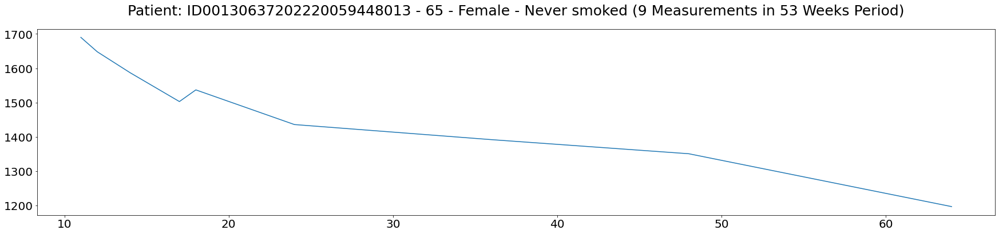

Patient: ID00131637202220424084844 FVC Statistical Summary
----------------------------------------------------------
Mean: 3272.89  -  Median: 3292.0  -  Std: 125.031
Min: 2990 -  Max: 3407
Skew: -1.5475  -  Kurtosis: 3.00186
Change Mean: 93.125  - Change Median: 78.0  - Change Std: 64.6605
Change Min: 4.0 -  Change Max: 218.0
Change Skew: 0.860303 -  Change Kurtosis: 1.28511


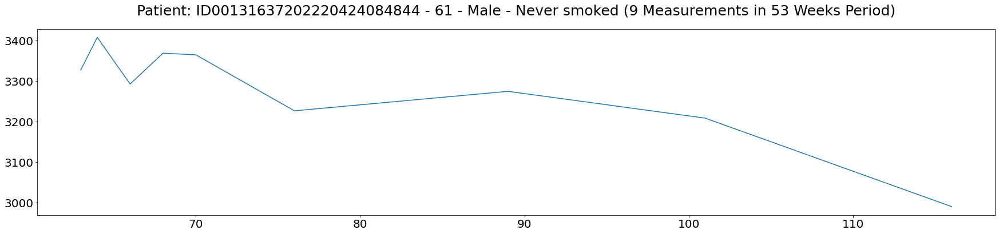

Patient: ID00132637202222178761324 FVC Statistical Summary
----------------------------------------------------------
Mean: 2623.56  -  Median: 2608.0  -  Std: 53.6612
Min: 2579 -  Max: 2743
Skew: 1.66116  -  Kurtosis: 2.51532
Change Mean: 56.5  - Change Median: 39.0  - Change Std: 38.1987
Change Min: 20.0 -  Change Max: 129.0
Change Skew: 1.17662 -  Change Kurtosis: 0.378302


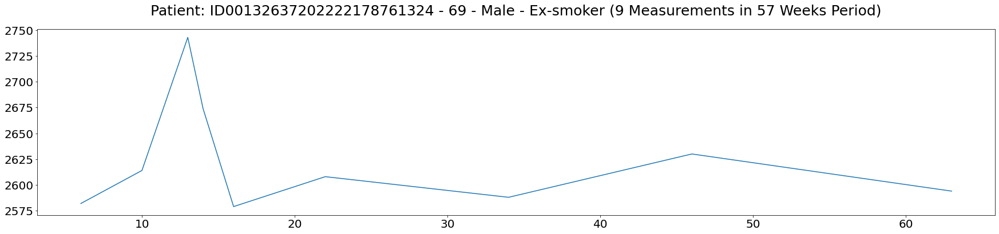

Patient: ID00133637202223847701934 FVC Statistical Summary
----------------------------------------------------------
Mean: 3111.67  -  Median: 3105.0  -  Std: 65.9773
Min: 3033 -  Max: 3203
Skew: 0.21562  -  Kurtosis: -1.50896
Change Mean: 44.75  - Change Median: 37.0  - Change Std: 36.7841
Change Min: 8.0 -  Change Max: 106.0
Change Skew: 0.527476 -  Change Kurtosis: -1.20959


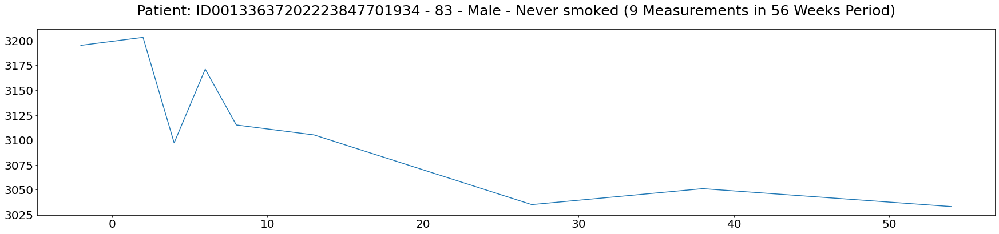

Patient: ID00134637202223873059688 FVC Statistical Summary
----------------------------------------------------------
Mean: 2502.89  -  Median: 2568.0  -  Std: 208.772
Min: 2112 -  Max: 2729
Skew: -1.06077  -  Kurtosis: 0.0359219
Change Mean: 133.375  - Change Median: 117.5  - Change Std: 100.967
Change Min: 8.0 -  Change Max: 303.0
Change Skew: 0.744974 -  Change Kurtosis: -0.227831


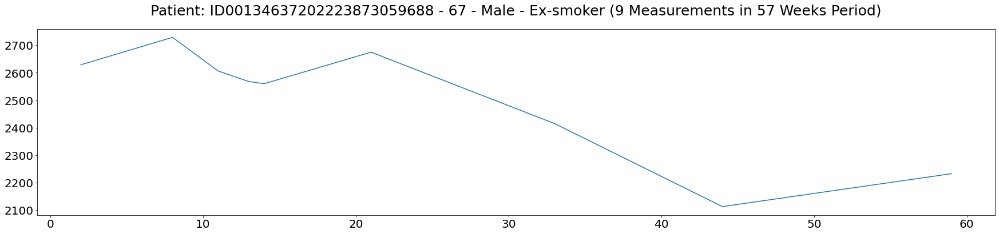

Patient: ID00135637202224630271439 FVC Statistical Summary
----------------------------------------------------------
Mean: 3913.22  -  Median: 3906.0  -  Std: 97.7417
Min: 3780 -  Max: 4087
Skew: 0.599287  -  Kurtosis: 0.0675131
Change Mean: 103.625  - Change Median: 88.5  - Change Std: 88.5066
Change Min: 6.0 -  Change Max: 228.0
Change Skew: 0.4128 -  Change Kurtosis: -1.62821


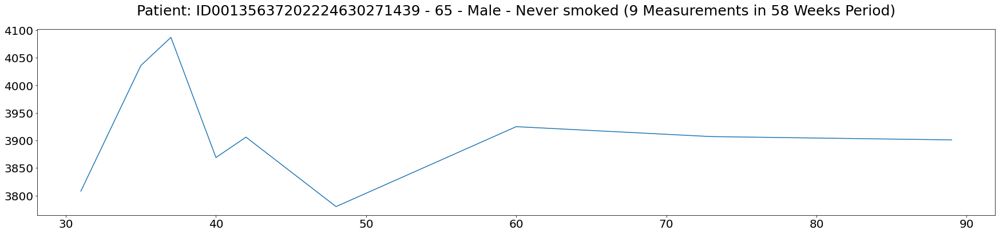

Patient: ID00136637202224951350618 FVC Statistical Summary
----------------------------------------------------------
Mean: 3305.22  -  Median: 3305.0  -  Std: 64.6776
Min: 3197 -  Max: 3390
Skew: -0.267008  -  Kurtosis: -0.821995
Change Mean: 89.0  - Change Median: 91.0  - Change Std: 51.9285
Change Min: 19.0 -  Change Max: 165.0
Change Skew: 0.147006 -  Change Kurtosis: -0.872839


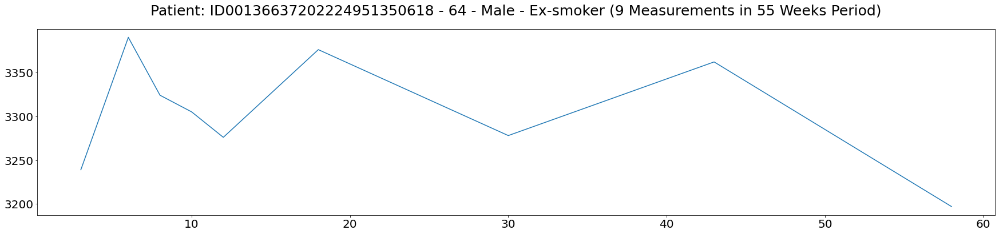

Patient: ID00138637202231603868088 FVC Statistical Summary
----------------------------------------------------------
Mean: 4310.78  -  Median: 4320.0  -  Std: 113.422
Min: 4151 -  Max: 4510
Skew: 0.474712  -  Kurtosis: -0.157578
Change Mean: 75.875  - Change Median: 72.0  - Change Std: 37.1193
Change Min: 15.0 -  Change Max: 124.0
Change Skew: -0.206102 -  Change Kurtosis: -0.750304


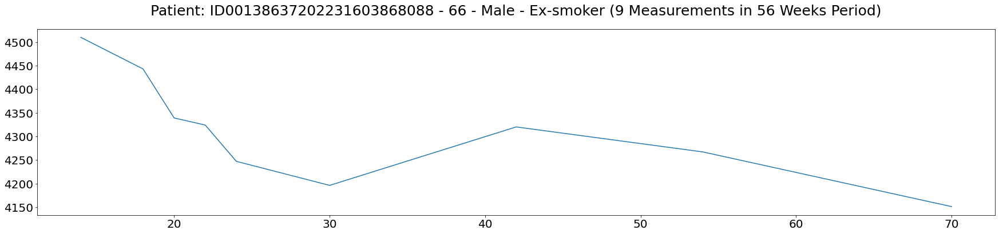

Patient: ID00139637202231703564336 FVC Statistical Summary
----------------------------------------------------------
Mean: 3893.78  -  Median: 3916.0  -  Std: 178.358
Min: 3568 -  Max: 4130
Skew: -0.494244  -  Kurtosis: -0.227759
Change Mean: 153.125  - Change Median: 143.0  - Change Std: 78.0155
Change Min: 51.0 -  Change Max: 267.0
Change Skew: 0.172921 -  Change Kurtosis: -1.58758


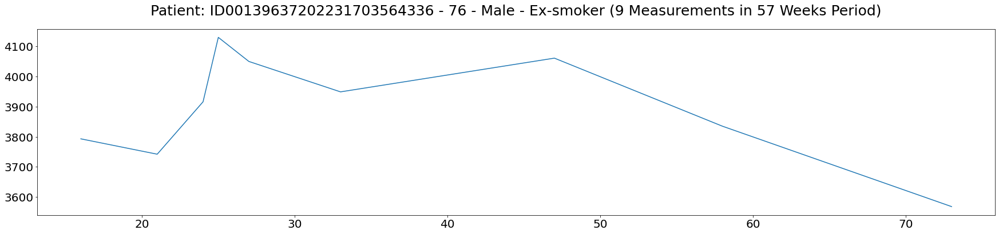

Patient: ID00140637202231728595149 FVC Statistical Summary
----------------------------------------------------------
Mean: 4035.9  -  Median: 4070.5  -  Std: 115.517
Min: 3852 -  Max: 4201
Skew: -0.475498  -  Kurtosis: -0.758916
Change Mean: 105.444  - Change Median: 109.0  - Change Std: 58.6048
Change Min: 13.0 -  Change Max: 200.0
Change Skew: -0.0925399 -  Change Kurtosis: -0.361925


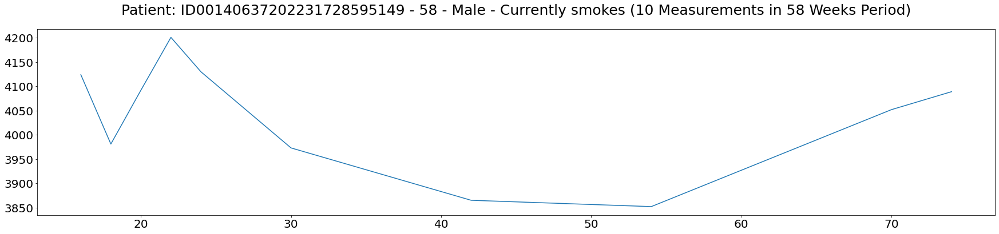

Patient: ID00149637202232704462834 FVC Statistical Summary
----------------------------------------------------------
Mean: 3082.0  -  Median: 3156.0  -  Std: 184.64
Min: 2686 -  Max: 3247
Skew: -1.36614  -  Kurtosis: 1.63763
Change Mean: 106.125  - Change Median: 105.0  - Change Std: 97.7364
Change Min: 4.0 -  Change Max: 266.0
Change Skew: 0.419787 -  Change Kurtosis: -1.13591


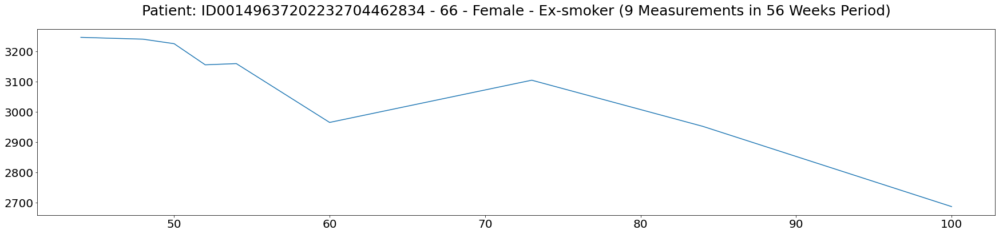

Patient: ID00161637202235731948764 FVC Statistical Summary
----------------------------------------------------------
Mean: 2868.78  -  Median: 2841.0  -  Std: 76.7948
Min: 2786 -  Max: 3017
Skew: 0.907524  -  Kurtosis: 0.0409979
Change Mean: 82.625  - Change Median: 83.5  - Change Std: 43.4378
Change Min: 20.0 -  Change Max: 158.0
Change Skew: 0.259876 -  Change Kurtosis: 0.306371


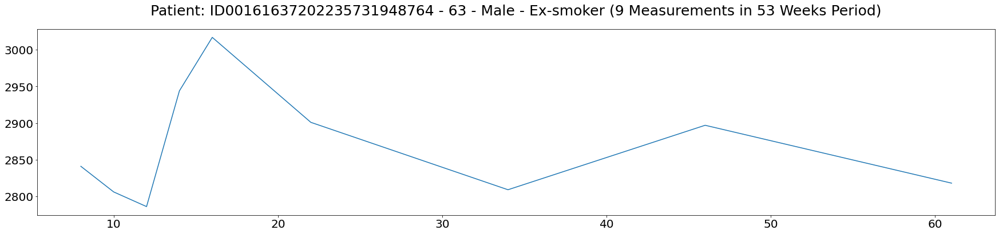

Patient: ID00165637202237320314458 FVC Statistical Summary
----------------------------------------------------------
Mean: 2149.89  -  Median: 2136.0  -  Std: 66.3428
Min: 2067 -  Max: 2296
Skew: 1.30453  -  Kurtosis: 2.55387
Change Mean: 78.25  - Change Median: 69.5  - Change Std: 53.382
Change Min: 0.0 -  Change Max: 167.0
Change Skew: 0.397242 -  Change Kurtosis: -0.10972


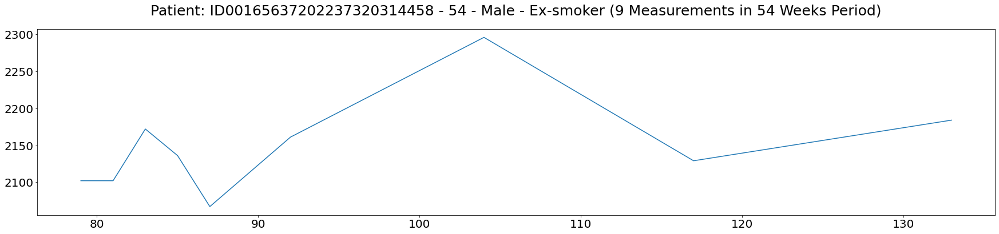

Patient: ID00167637202237397919352 FVC Statistical Summary
----------------------------------------------------------
Mean: 4481.9  -  Median: 4549.5  -  Std: 295.477
Min: 3744 -  Max: 4791
Skew: -1.94815  -  Kurtosis: 4.54332
Change Mean: 156.889  - Change Median: 113.0  - Change Std: 159.07
Change Min: 27.0 -  Change Max: 544.0
Change Skew: 2.11813 -  Change Kurtosis: 5.09832


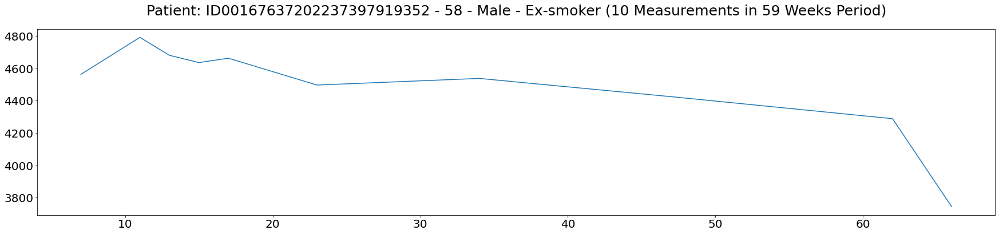

Patient: ID00168637202237852027833 FVC Statistical Summary
----------------------------------------------------------
Mean: 2973.89  -  Median: 2993.0  -  Std: 165.957
Min: 2711 -  Max: 3186
Skew: -0.447704  -  Kurtosis: -1.02478
Change Mean: 83.375  - Change Median: 78.5  - Change Std: 37.0326
Change Min: 48.0 -  Change Max: 150.0
Change Skew: 0.771571 -  Change Kurtosis: -0.306821


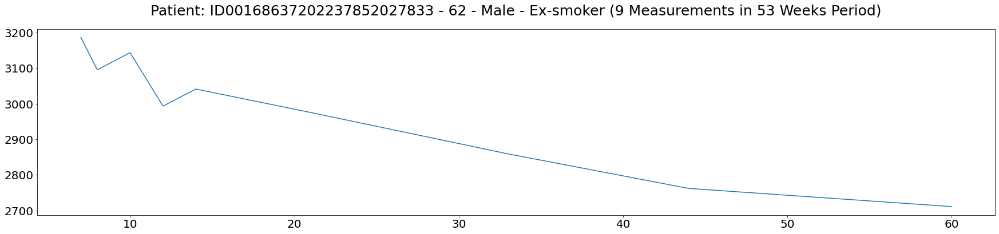

Patient: ID00169637202238024117706 FVC Statistical Summary
----------------------------------------------------------
Mean: 2463.22  -  Median: 2480.0  -  Std: 78.1645
Min: 2263 -  Max: 2527
Skew: -2.54221  -  Kurtosis: 7.15866
Change Mean: 49.875  - Change Median: 32.5  - Change Std: 65.8471
Change Min: 6.0 -  Change Max: 208.0
Change Skew: 2.50477 -  Change Kurtosis: 6.64207


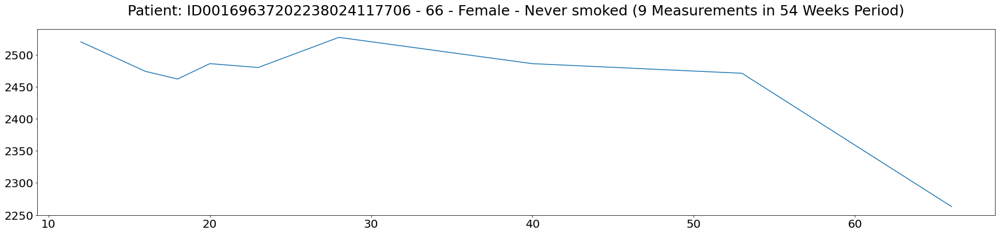

Patient: ID00170637202238079193844 FVC Statistical Summary
----------------------------------------------------------
Mean: 2209.44  -  Median: 2205.0  -  Std: 173.192
Min: 1970 -  Max: 2474
Skew: 0.0850409  -  Kurtosis: -1.223
Change Mean: 188.75  - Change Median: 138.5  - Change Std: 150.512
Change Min: 50.0 -  Change Max: 504.0
Change Skew: 1.4757 -  Change Kurtosis: 2.2035


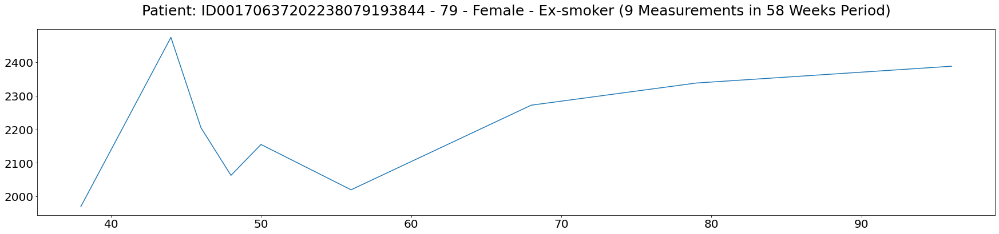

Patient: ID00172637202238316925179 FVC Statistical Summary
----------------------------------------------------------
Mean: 2740.67  -  Median: 2749.0  -  Std: 82.6544
Min: 2603 -  Max: 2833
Skew: -0.712693  -  Kurtosis: -0.543181
Change Mean: 62.25  - Change Median: 43.5  - Change Std: 60.0042
Change Min: 3.0 -  Change Max: 178.0
Change Skew: 1.09036 -  Change Kurtosis: 0.637356


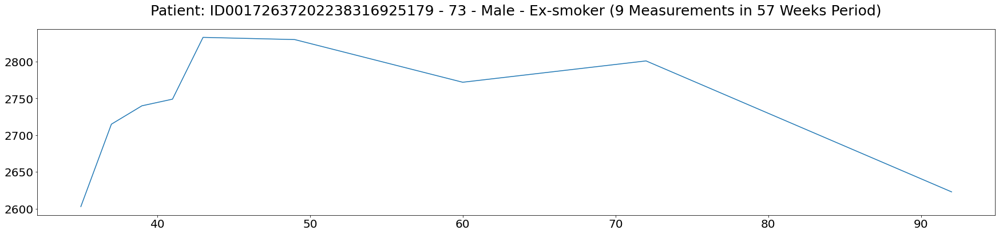

Patient: ID00173637202238329754031 FVC Statistical Summary
----------------------------------------------------------
Mean: 2719.67  -  Median: 2697.0  -  Std: 120.43
Min: 2563 -  Max: 2889
Skew: 0.197104  -  Kurtosis: -1.4008
Change Mean: 70.875  - Change Median: 64.5  - Change Std: 50.6964
Change Min: 13.0 -  Change Max: 143.0
Change Skew: 0.348054 -  Change Kurtosis: -1.62363


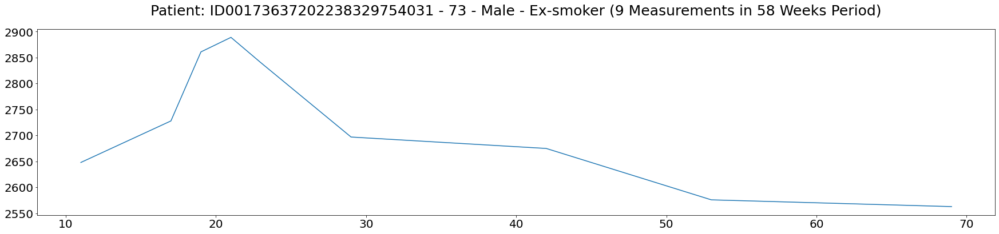

Patient: ID00180637202240177410333 FVC Statistical Summary
----------------------------------------------------------
Mean: 2957.44  -  Median: 2962.0  -  Std: 110.533
Min: 2761 -  Max: 3102
Skew: -0.529043  -  Kurtosis: -0.533487
Change Mean: 103.375  - Change Median: 102.0  - Change Std: 55.8594
Change Min: 5.0 -  Change Max: 183.0
Change Skew: -0.463323 -  Change Kurtosis: 0.210156


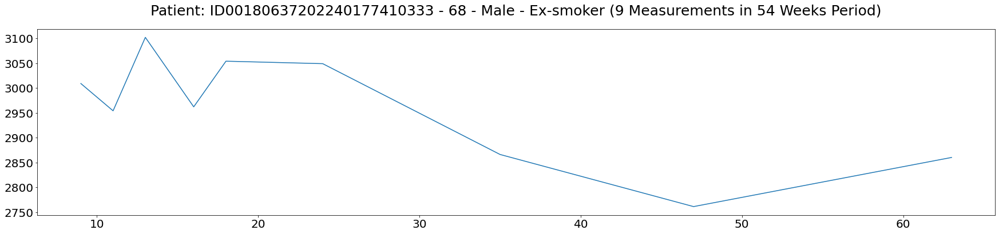

Patient: ID00183637202241995351650 FVC Statistical Summary
----------------------------------------------------------
Mean: 2429.11  -  Median: 2427.0  -  Std: 75.0857
Min: 2346 -  Max: 2541
Skew: 0.463542  -  Kurtosis: -1.13688
Change Mean: 66.25  - Change Median: 72.0  - Change Std: 58.1199
Change Min: 4.0 -  Change Max: 183.0
Change Skew: 1.0481 -  Change Kurtosis: 1.6034


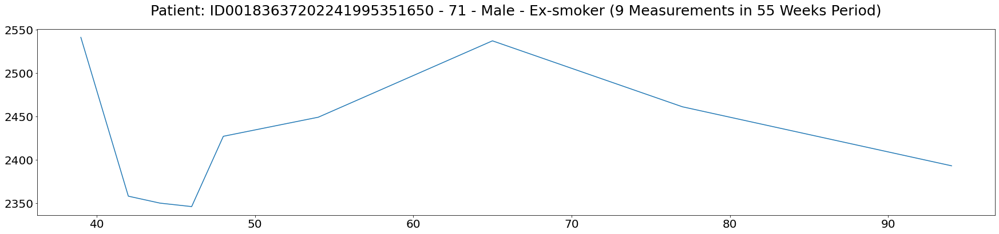

Patient: ID00184637202242062969203 FVC Statistical Summary
----------------------------------------------------------
Mean: 2999.11  -  Median: 3009.0  -  Std: 162.529
Min: 2743 -  Max: 3197
Skew: -0.55757  -  Kurtosis: -0.616565
Change Mean: 209.875  - Change Median: 199.0  - Change Std: 115.848
Change Min: 30.0 -  Change Max: 436.0
Change Skew: 0.675637 -  Change Kurtosis: 2.11143


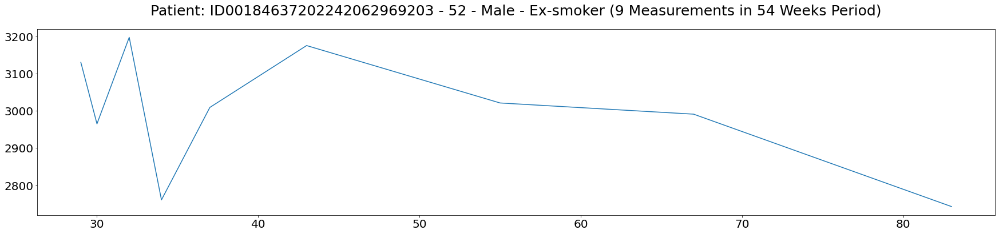

Patient: ID00186637202242472088675 FVC Statistical Summary
----------------------------------------------------------
Mean: 2657.14  -  Median: 2759.0  -  Std: 314.458
Min: 2119 -  Max: 3096
Skew: -0.569342  -  Kurtosis: 0.560611
Change Mean: 177.833  - Change Median: 165.5  - Change Std: 115.122
Change Min: 45.0 -  Change Max: 315.0
Change Skew: 0.221786 -  Change Kurtosis: -1.8171


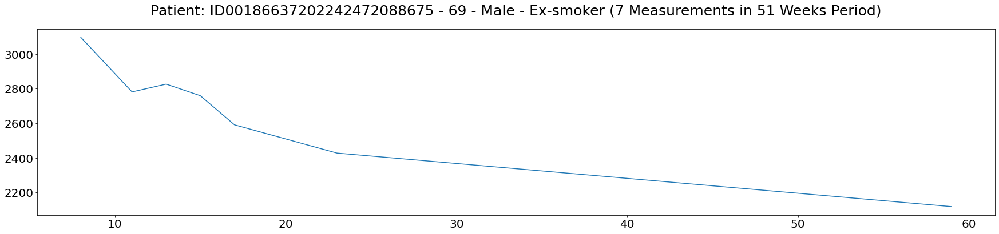

Patient: ID00190637202244450116191 FVC Statistical Summary
----------------------------------------------------------
Mean: 4350.33  -  Median: 4330.0  -  Std: 122.26
Min: 4169 -  Max: 4490
Skew: -0.269737  -  Kurtosis: -1.41942
Change Mean: 107.25  - Change Median: 91.5  - Change Std: 95.3846
Change Min: 2.0 -  Change Max: 268.0
Change Skew: 0.575479 -  Change Kurtosis: -0.903066


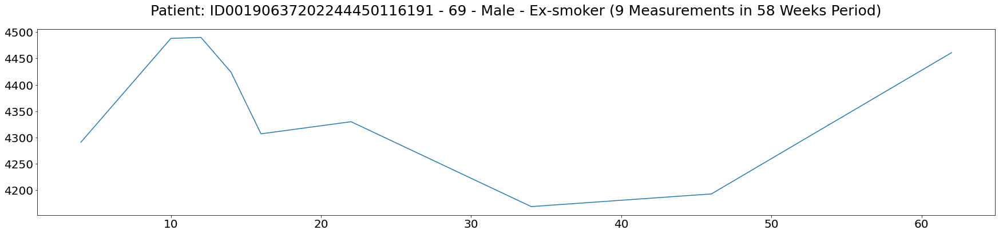

Patient: ID00192637202245493238298 FVC Statistical Summary
----------------------------------------------------------
Mean: 1782.78  -  Median: 1829.0  -  Std: 114.376
Min: 1568 -  Max: 1929
Skew: -0.843985  -  Kurtosis: 0.0886456
Change Mean: 87.0  - Change Median: 51.5  - Change Std: 71.3322
Change Min: 21.0 -  Change Max: 201.0
Change Skew: 1.19591 -  Change Kurtosis: -0.341709


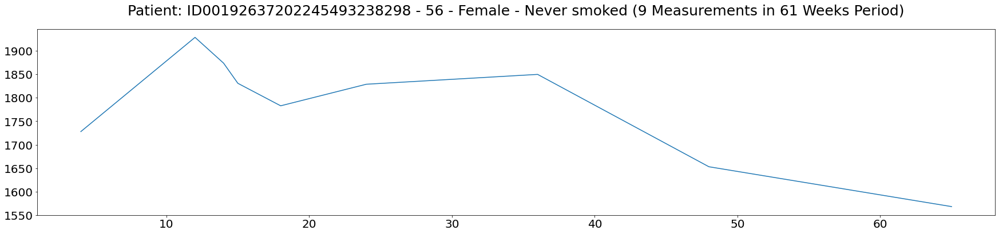

Patient: ID00196637202246668775836 FVC Statistical Summary
----------------------------------------------------------
Mean: 3907.89  -  Median: 3856.0  -  Std: 175.753
Min: 3792 -  Max: 4360
Skew: 2.61321  -  Kurtosis: 7.27874
Change Mean: 155.375  - Change Median: 57.0  - Change Std: 209.443
Change Min: 19.0 -  Change Max: 549.0
Change Skew: 1.50636 -  Change Kurtosis: 0.585202


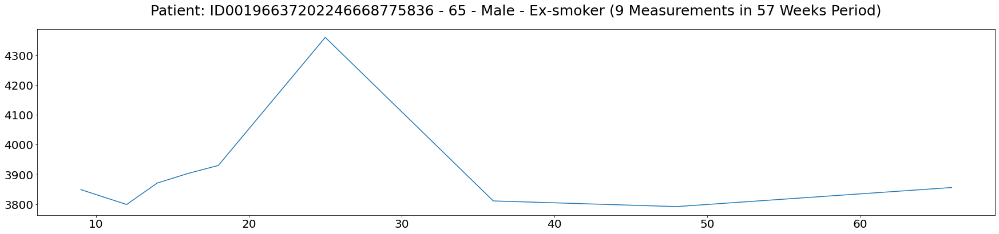

Patient: ID00197637202246865691526 FVC Statistical Summary
----------------------------------------------------------
Mean: 2512.56  -  Median: 2360.0  -  Std: 532.78
Min: 1941 -  Max: 3399
Skew: 0.809177  -  Kurtosis: -0.600901
Change Mean: 646.375  - Change Median: 434.5  - Change Std: 465.064
Change Min: 168.0 -  Change Max: 1458.0
Change Skew: 0.832668 -  Change Kurtosis: -0.71247


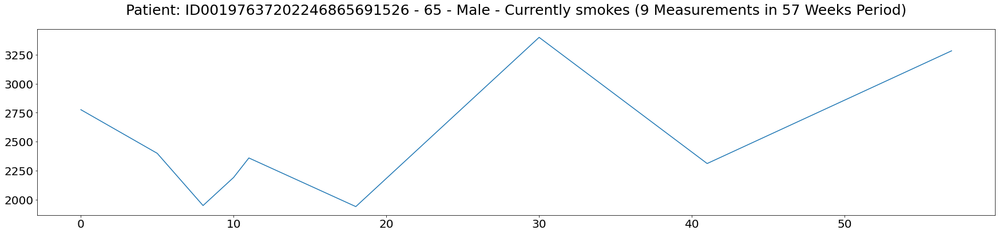

Patient: ID00199637202248141386743 FVC Statistical Summary
----------------------------------------------------------
Mean: 2814.44  -  Median: 2844.0  -  Std: 106.27
Min: 2672 -  Max: 2949
Skew: -0.462282  -  Kurtosis: -1.58164
Change Mean: 92.875  - Change Median: 63.0  - Change Std: 81.0563
Change Min: 11.0 -  Change Max: 221.0
Change Skew: 0.613109 -  Change Kurtosis: -1.33239


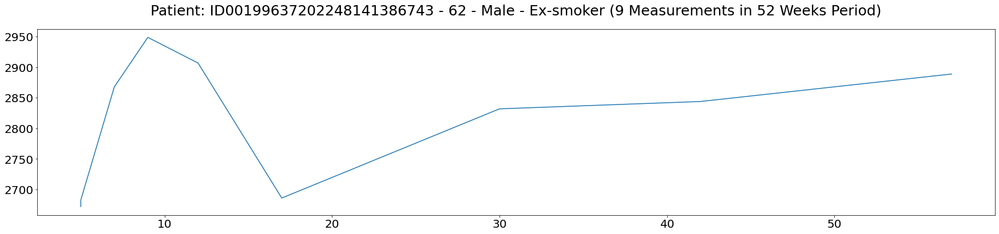

Patient: ID00202637202249376026949 FVC Statistical Summary
----------------------------------------------------------
Mean: 4059.89  -  Median: 4092.0  -  Std: 260.16
Min: 3641 -  Max: 4316
Skew: -0.906282  -  Kurtosis: -0.422031
Change Mean: 109.375  - Change Median: 57.5  - Change Std: 127.664
Change Min: 5.0 -  Change Max: 399.0
Change Skew: 2.02664 -  Change Kurtosis: 4.44338


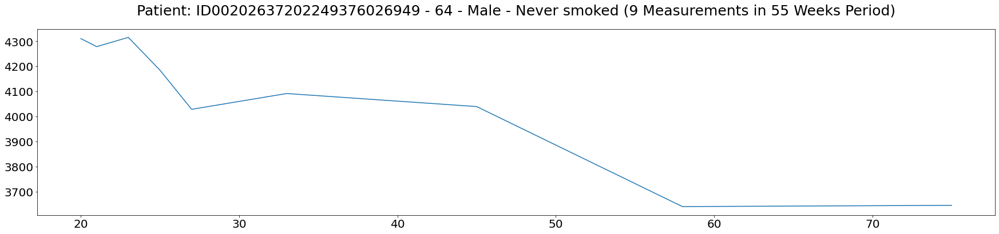

Patient: ID00207637202252526380974 FVC Statistical Summary
----------------------------------------------------------
Mean: 2682.11  -  Median: 2722.0  -  Std: 173.889
Min: 2379 -  Max: 2924
Skew: -0.498835  -  Kurtosis: -0.520507
Change Mean: 118.875  - Change Median: 102.5  - Change Std: 114.913
Change Min: 4.0 -  Change Max: 343.0
Change Skew: 1.02583 -  Change Kurtosis: 0.883297


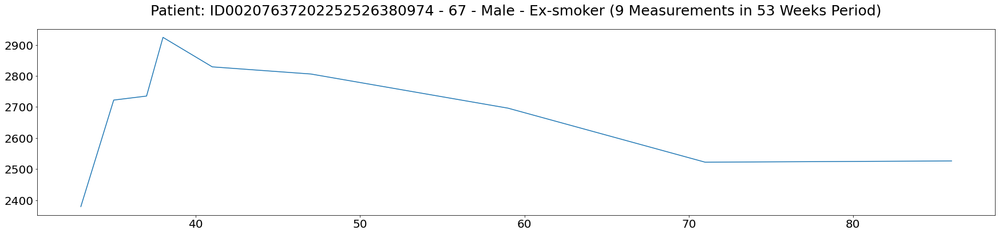

Patient: ID00210637202257228694086 FVC Statistical Summary
----------------------------------------------------------
Mean: 2827.33  -  Median: 2844.0  -  Std: 32.0858
Min: 2773 -  Max: 2860
Skew: -0.99832  -  Kurtosis: -0.613438
Change Mean: 22.5  - Change Median: 10.5  - Change Std: 28.0
Change Min: 1.0 -  Change Max: 87.0
Change Skew: 2.14366 -  Change Kurtosis: 4.97448


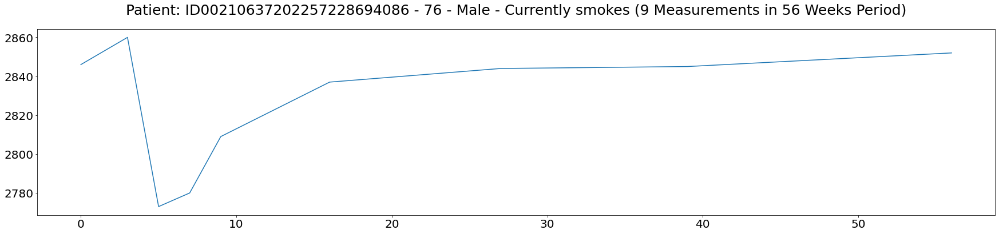

Patient: ID00213637202257692916109 FVC Statistical Summary
----------------------------------------------------------
Mean: 3131.33  -  Median: 3090.0  -  Std: 135.823
Min: 2972 -  Max: 3376
Skew: 0.791977  -  Kurtosis: -0.480199
Change Mean: 207.5  - Change Median: 201.0  - Change Std: 114.945
Change Min: 69.0 -  Change Max: 341.0
Change Skew: 0.00570118 -  Change Kurtosis: -2.4107


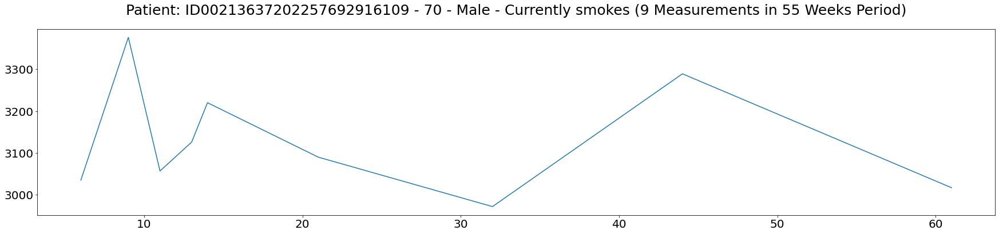

Patient: ID00214637202257820847190 FVC Statistical Summary
----------------------------------------------------------
Mean: 2867.78  -  Median: 2869.0  -  Std: 41.3726
Min: 2791 -  Max: 2929
Skew: -0.435468  -  Kurtosis: 0.460685
Change Mean: 40.0  - Change Median: 40.5  - Change Std: 23.2809
Change Min: 16.0 -  Change Max: 83.0
Change Skew: 0.773755 -  Change Kurtosis: 0.183897


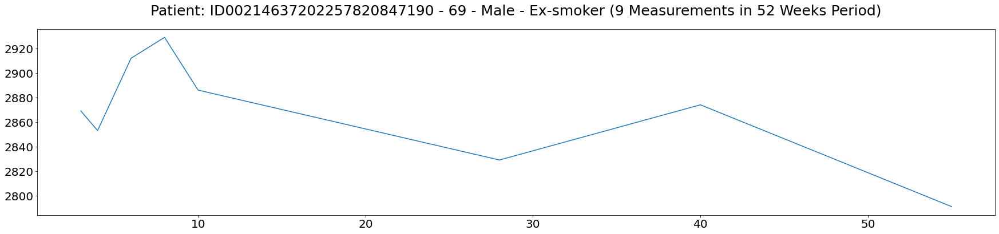

Patient: ID00216637202257988213445 FVC Statistical Summary
----------------------------------------------------------
Mean: 2224.0  -  Median: 2157.0  -  Std: 205.258
Min: 1997 -  Max: 2658
Skew: 1.33639  -  Kurtosis: 1.54922
Change Mean: 181.875  - Change Median: 146.0  - Change Std: 122.601
Change Min: 24.0 -  Change Max: 369.0
Change Skew: 0.572068 -  Change Kurtosis: -0.88878


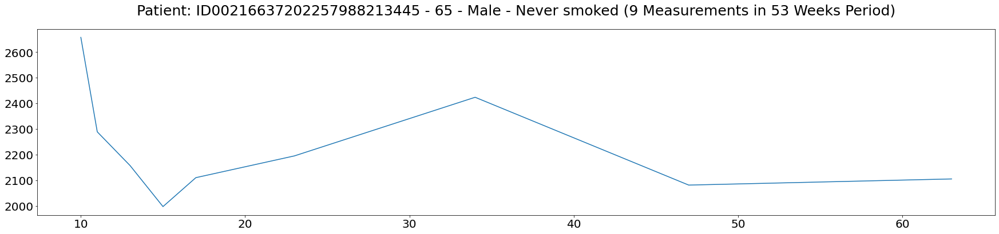

Patient: ID00218637202258156844710 FVC Statistical Summary
----------------------------------------------------------
Mean: 2615.78  -  Median: 2582.0  -  Std: 140.079
Min: 2439 -  Max: 2888
Skew: 1.16495  -  Kurtosis: 0.827429
Change Mean: 112.375  - Change Median: 70.5  - Change Std: 116.767
Change Min: 18.0 -  Change Max: 361.0
Change Skew: 1.67703 -  Change Kurtosis: 2.58655


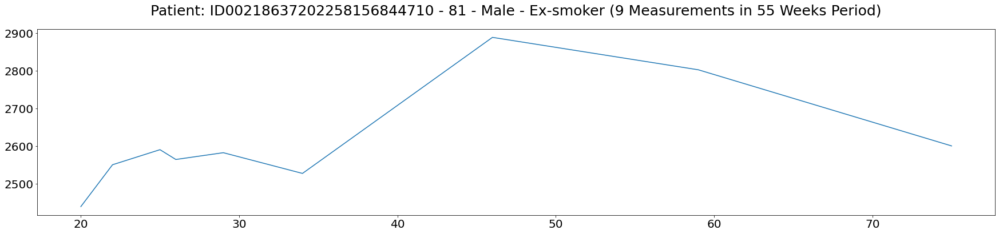

Patient: ID00219637202258203123958 FVC Statistical Summary
----------------------------------------------------------
Mean: 5845.44  -  Median: 5768.0  -  Std: 228.922
Min: 5613 -  Max: 6399
Skew: 2.01656  -  Kurtosis: 4.97073
Change Mean: 233.625  - Change Median: 201.0  - Change Std: 214.613
Change Min: 24.0 -  Change Max: 721.0
Change Skew: 1.95888 -  Change Kurtosis: 4.64289


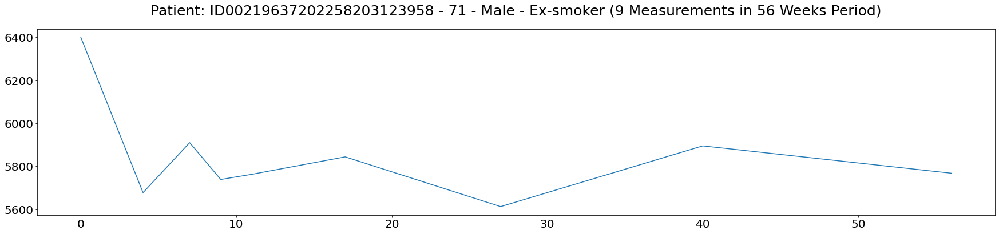

Patient: ID00221637202258717315571 FVC Statistical Summary
----------------------------------------------------------
Mean: 1414.33  -  Median: 1416.0  -  Std: 66.2344
Min: 1285 -  Max: 1529
Skew: -0.334169  -  Kurtosis: 1.82501
Change Mean: 58.25  - Change Median: 69.0  - Change Std: 33.1953
Change Min: 8.0 -  Change Max: 106.0
Change Skew: -0.440938 -  Change Kurtosis: -0.559594


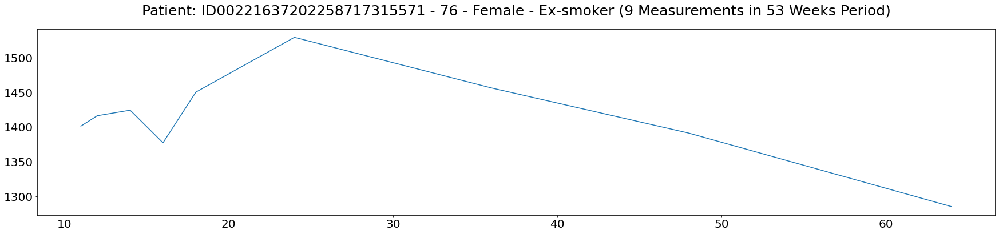

Patient: ID00222637202259066229764 FVC Statistical Summary
----------------------------------------------------------
Mean: 2468.89  -  Median: 2492.0  -  Std: 117.425
Min: 2316 -  Max: 2644
Skew: 0.0561518  -  Kurtosis: -1.64099
Change Mean: 102.75  - Change Median: 58.0  - Change Std: 105.486
Change Min: 9.0 -  Change Max: 299.0
Change Skew: 1.08285 -  Change Kurtosis: 0.0578707


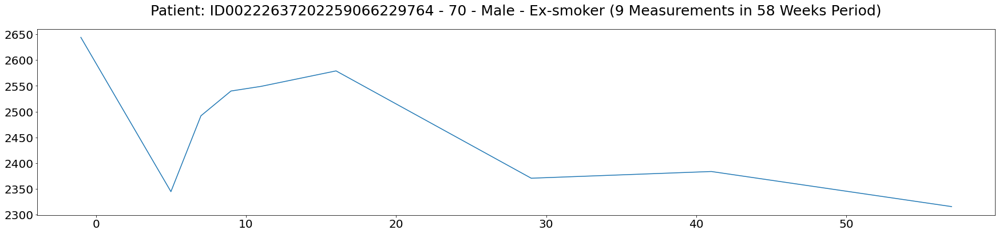

Patient: ID00224637202259281193413 FVC Statistical Summary
----------------------------------------------------------
Mean: 2692.67  -  Median: 2679.0  -  Std: 159.989
Min: 2388 -  Max: 2992
Skew: -0.00312745  -  Kurtosis: 2.32356
Change Mean: 162.0  - Change Median: 111.0  - Change Std: 144.201
Change Min: 6.0 -  Change Max: 355.0
Change Skew: 0.395584 -  Change Kurtosis: -1.99873


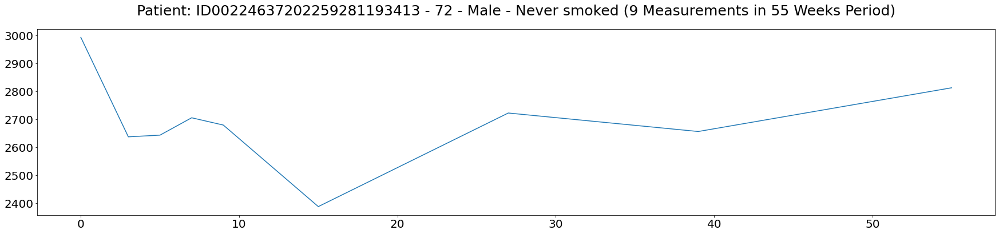

Patient: ID00225637202259339837603 FVC Statistical Summary
----------------------------------------------------------
Mean: 1026.25  -  Median: 985.5  -  Std: 237.997
Min: 827 -  Max: 1583
Skew: 2.21131  -  Kurtosis: 5.70318
Change Mean: 119.286  - Change Median: 34.0  - Change Std: 210.464
Change Min: 1.0 -  Change Max: 582.0
Change Skew: 2.34276 -  Change Kurtosis: 5.64739


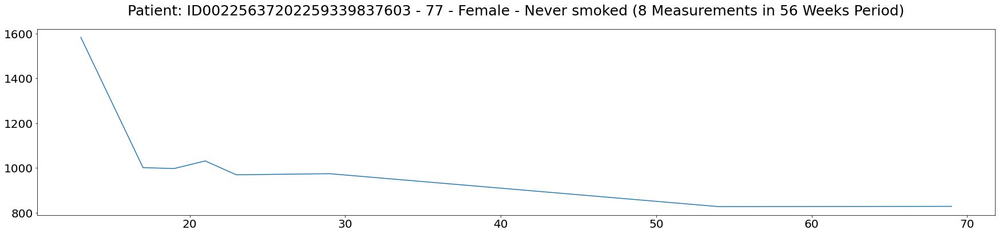

Patient: ID00228637202259965313869 FVC Statistical Summary
----------------------------------------------------------
Mean: 1818.11  -  Median: 1851.0  -  Std: 117.547
Min: 1657 -  Max: 1972
Skew: -0.460151  -  Kurtosis: -1.47258
Change Mean: 85.875  - Change Median: 94.0  - Change Std: 71.8121
Change Min: 0.0 -  Change Max: 176.0
Change Skew: -0.0749532 -  Change Kurtosis: -2.07324


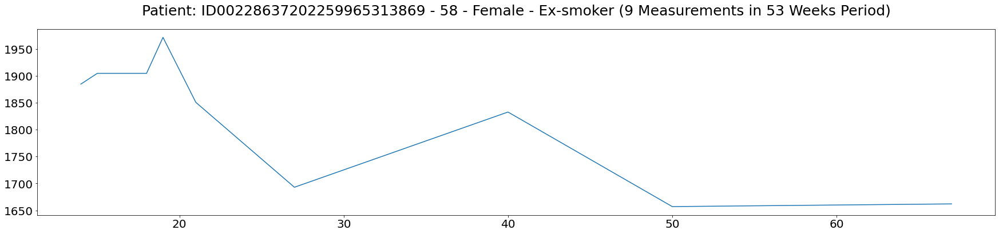

Patient: ID00229637202260254240583 FVC Statistical Summary
----------------------------------------------------------
Mean: 3483.8  -  Median: 3503.5  -  Std: 103.712
Min: 3342 -  Max: 3649
Skew: 0.0720158  -  Kurtosis: -1.10166
Change Mean: 77.3333  - Change Median: 79.0  - Change Std: 47.9609
Change Min: 13.0 -  Change Max: 137.0
Change Skew: -0.203837 -  Change Kurtosis: -1.62421


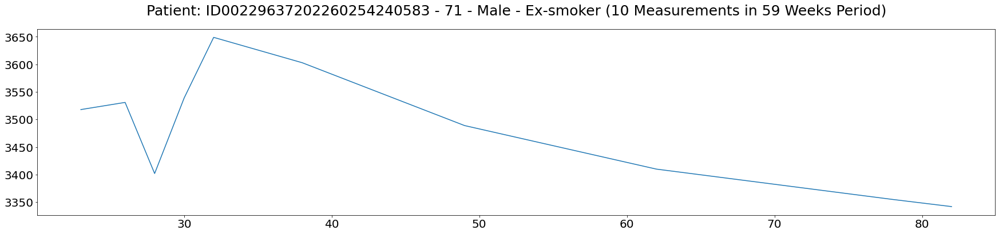

Patient: ID00232637202260377586117 FVC Statistical Summary
----------------------------------------------------------
Mean: 1901.11  -  Median: 1845.0  -  Std: 129.304
Min: 1732 -  Max: 2095
Skew: 0.60635  -  Kurtosis: -0.879146
Change Mean: 153.25  - Change Median: 94.5  - Change Std: 127.605
Change Min: 32.0 -  Change Max: 363.0
Change Skew: 0.71978 -  Change Kurtosis: -1.2714


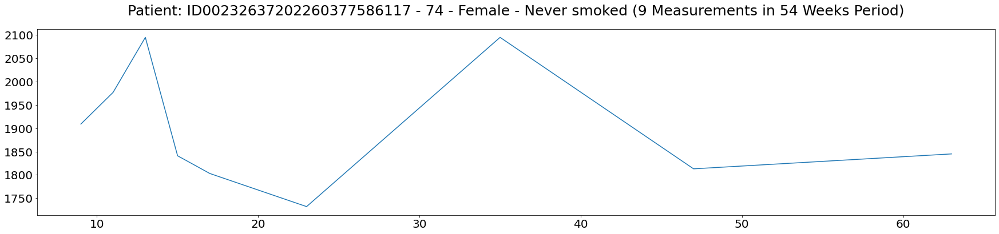

Patient: ID00233637202260580149633 FVC Statistical Summary
----------------------------------------------------------
Mean: 3554.33  -  Median: 3574.0  -  Std: 162.552
Min: 3252 -  Max: 3829
Skew: -0.266742  -  Kurtosis: 1.05001
Change Mean: 167.625  - Change Median: 137.0  - Change Std: 134.811
Change Min: 10.0 -  Change Max: 362.0
Change Skew: 0.372327 -  Change Kurtosis: -1.60731


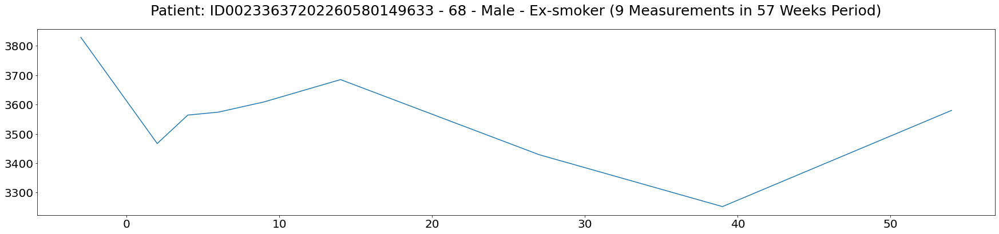

Patient: ID00234637202261078001846 FVC Statistical Summary
----------------------------------------------------------
Mean: 1922.75  -  Median: 1949.5  -  Std: 122.953
Min: 1756 -  Max: 2080
Skew: -0.278989  -  Kurtosis: -1.65293
Change Mean: 178.714  - Change Median: 233.0  - Change Std: 91.3888
Change Min: 49.0 -  Change Max: 253.0
Change Skew: -0.819281 -  Change Kurtosis: -1.49261


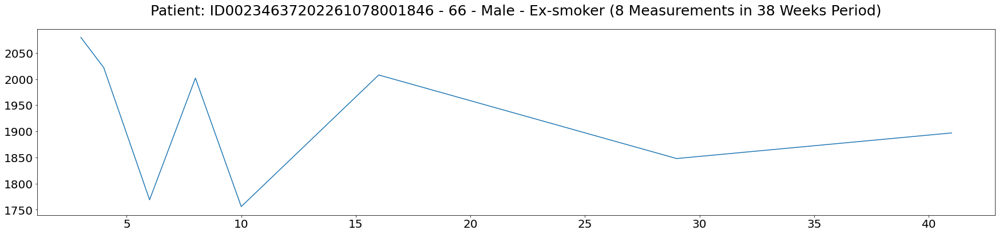

Patient: ID00235637202261451839085 FVC Statistical Summary
----------------------------------------------------------
Mean: 2143.56  -  Median: 2129.0  -  Std: 57.1929
Min: 2061 -  Max: 2257
Skew: 0.751635  -  Kurtosis: 1.00279
Change Mean: 53.75  - Change Median: 58.0  - Change Std: 18.5761
Change Min: 22.0 -  Change Max: 78.0
Change Skew: -0.625689 -  Change Kurtosis: -0.361417


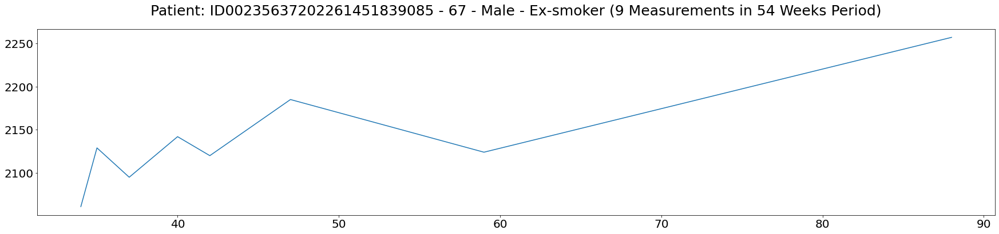

Patient: ID00240637202264138860065 FVC Statistical Summary
----------------------------------------------------------
Mean: 2815.67  -  Median: 2782.0  -  Std: 175.967
Min: 2503 -  Max: 3132
Skew: 0.157272  -  Kurtosis: 1.19697
Change Mean: 131.125  - Change Median: 103.5  - Change Std: 100.624
Change Min: 20.0 -  Change Max: 260.0
Change Skew: 0.315729 -  Change Kurtosis: -1.9415


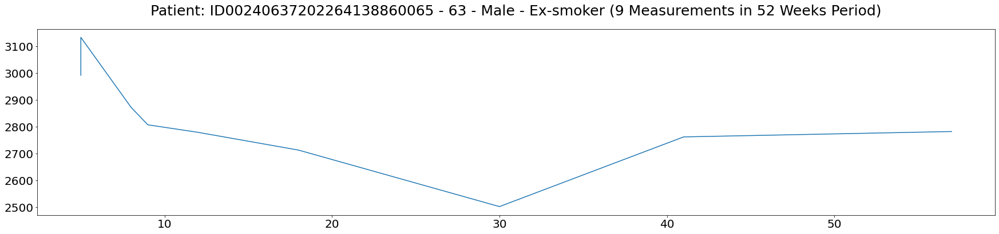

Patient: ID00241637202264294508775 FVC Statistical Summary
----------------------------------------------------------
Mean: 1328.0  -  Median: 1344.0  -  Std: 61.6543
Min: 1188 -  Max: 1399
Skew: -1.5698  -  Kurtosis: 3.17616
Change Mean: 35.625  - Change Median: 27.5  - Change Std: 28.4401
Change Min: 13.0 -  Change Max: 102.0
Change Skew: 2.2345 -  Change Kurtosis: 5.51107


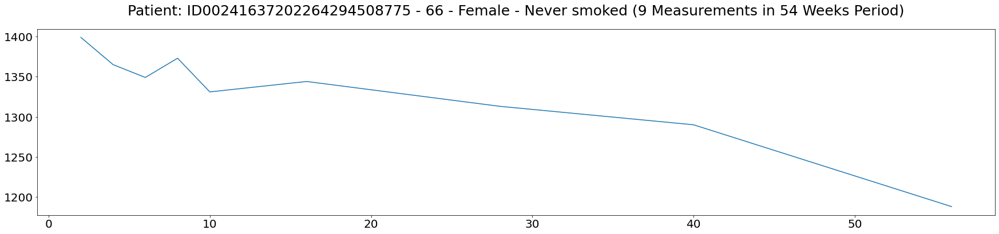

Patient: ID00242637202264759739921 FVC Statistical Summary
----------------------------------------------------------
Mean: 1775.0  -  Median: 1785.0  -  Std: 97.1146
Min: 1631 -  Max: 1918
Skew: -0.283142  -  Kurtosis: -0.896655
Change Mean: 109.25  - Change Median: 113.5  - Change Std: 58.7531
Change Min: 13.0 -  Change Max: 212.0
Change Skew: 0.0862609 -  Change Kurtosis: 1.00596


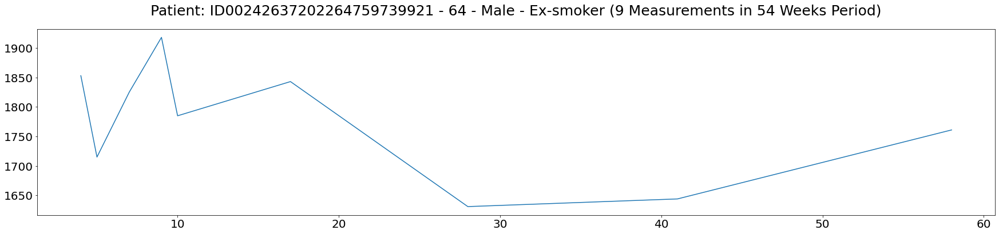

Patient: ID00248637202266698862378 FVC Statistical Summary
----------------------------------------------------------
Mean: 1366.89  -  Median: 1384.0  -  Std: 75.1789
Min: 1266 -  Max: 1481
Skew: 0.0153545  -  Kurtosis: -1.19145
Change Mean: 91.875  - Change Median: 84.0  - Change Std: 80.5152
Change Min: 0.0 -  Change Max: 209.0
Change Skew: 0.230943 -  Change Kurtosis: -1.86584


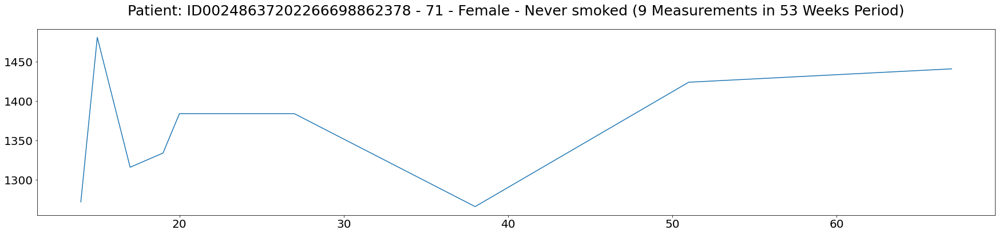

Patient: ID00249637202266730854017 FVC Statistical Summary
----------------------------------------------------------
Mean: 2831.88  -  Median: 3138.5  -  Std: 519.38
Min: 2139 -  Max: 3255
Skew: -0.654763  -  Kurtosis: -2.05557
Change Mean: 162.571  - Change Median: 68.0  - Change Std: 274.885
Change Min: 3.0 -  Change Max: 768.0
Change Skew: 2.35822 -  Change Kurtosis: 5.72361


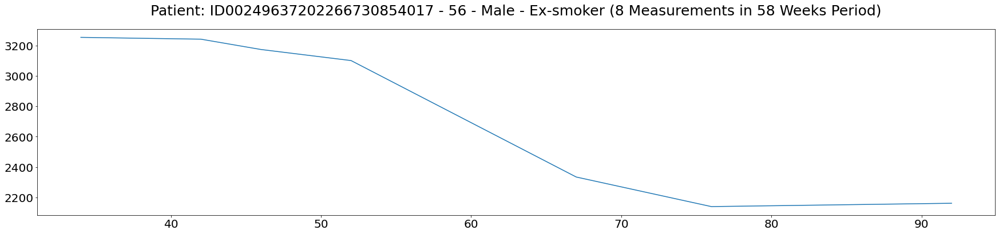

Patient: ID00251637202267455595113 FVC Statistical Summary
----------------------------------------------------------
Mean: 1981.11  -  Median: 2039.0  -  Std: 134.684
Min: 1715 -  Max: 2100
Skew: -1.32517  -  Kurtosis: 0.563777
Change Mean: 88.375  - Change Median: 64.0  - Change Std: 101.204
Change Min: 0.0 -  Change Max: 311.0
Change Skew: 1.75921 -  Change Kurtosis: 3.52045


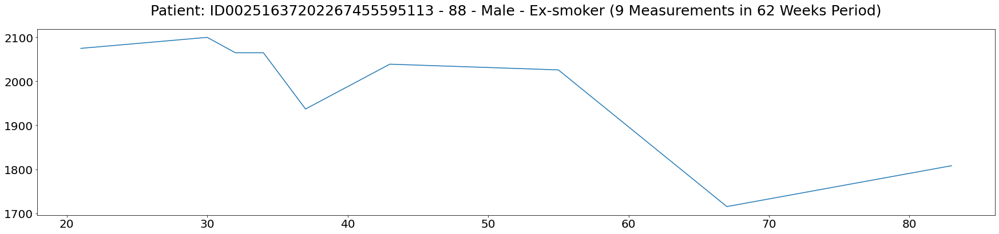

Patient: ID00255637202267923028520 FVC Statistical Summary
----------------------------------------------------------
Mean: 1502.25  -  Median: 1530.5  -  Std: 126.451
Min: 1315 -  Max: 1647
Skew: -0.751149  -  Kurtosis: -0.843792
Change Mean: 101.143  - Change Median: 63.0  - Change Std: 107.464
Change Min: 2.0 -  Change Max: 292.0
Change Skew: 0.960958 -  Change Kurtosis: 0.0607946


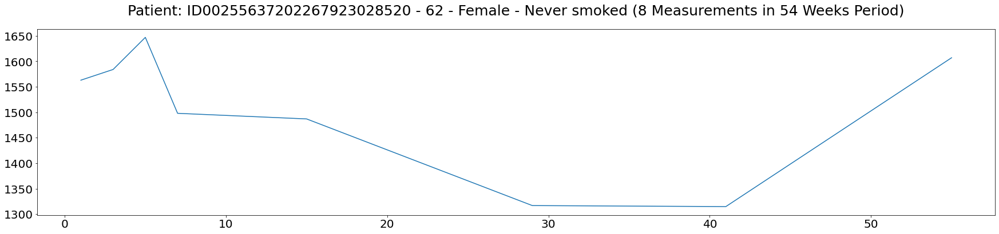

Patient: ID00264637202270643353440 FVC Statistical Summary
----------------------------------------------------------
Mean: 2027.75  -  Median: 2019.5  -  Std: 98.1628
Min: 1931 -  Max: 2239
Skew: 1.53552  -  Kurtosis: 3.07392
Change Mean: 106.429  - Change Median: 113.0  - Change Std: 75.9448
Change Min: 23.0 -  Change Max: 221.0
Change Skew: 0.335718 -  Change Kurtosis: -1.34932


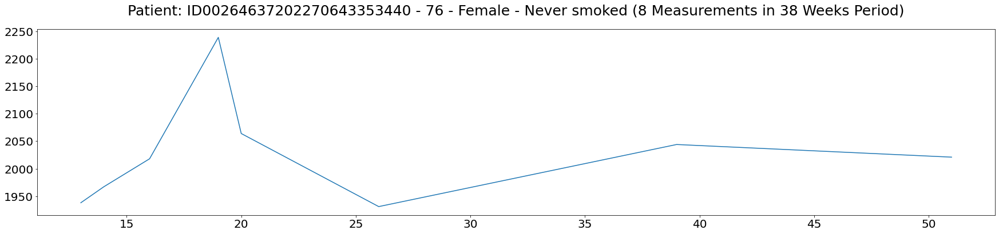

Patient: ID00267637202270790561585 FVC Statistical Summary
----------------------------------------------------------
Mean: 988.333  -  Median: 1017.0  -  Std: 74.0342
Min: 865 -  Max: 1065
Skew: -1.0732  -  Kurtosis: 0.244382
Change Mean: 54.8  - Change Median: 50.0  - Change Std: 31.0677
Change Min: 12.0 -  Change Max: 96.0
Change Skew: -0.0798759 -  Change Kurtosis: 0.448869


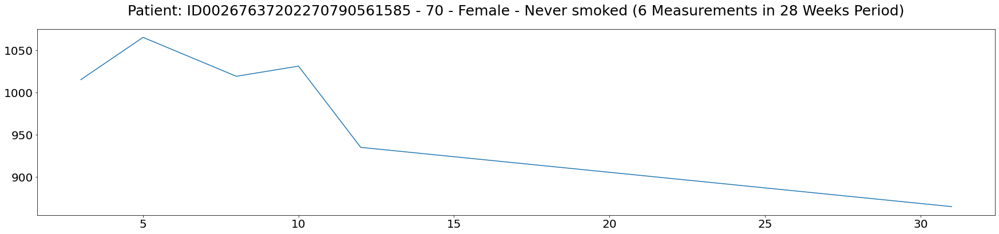

Patient: ID00273637202271319294586 FVC Statistical Summary
----------------------------------------------------------
Mean: 2870.67  -  Median: 2860.0  -  Std: 90.6394
Min: 2708 -  Max: 3020
Skew: -0.123902  -  Kurtosis: 0.587578
Change Mean: 77.0  - Change Median: 71.0  - Change Std: 51.6029
Change Min: 13.0 -  Change Max: 160.0
Change Skew: 0.531419 -  Change Kurtosis: -0.690148


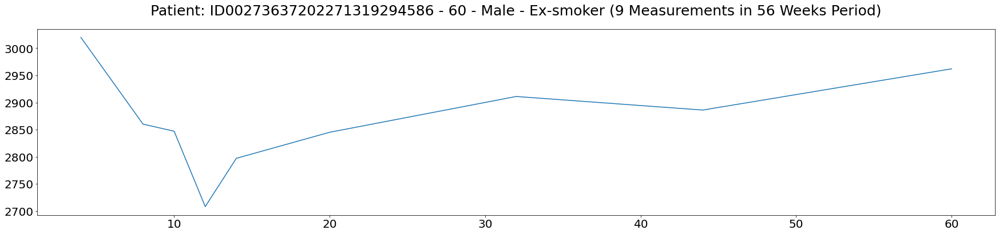

Patient: ID00275637202271440119890 FVC Statistical Summary
----------------------------------------------------------
Mean: 1934.44  -  Median: 1989.0  -  Std: 228.926
Min: 1481 -  Max: 2167
Skew: -1.22938  -  Kurtosis: 0.703924
Change Mean: 161.75  - Change Median: 145.0  - Change Std: 149.74
Change Min: 24.0 -  Change Max: 484.0
Change Skew: 1.57783 -  Change Kurtosis: 2.98618


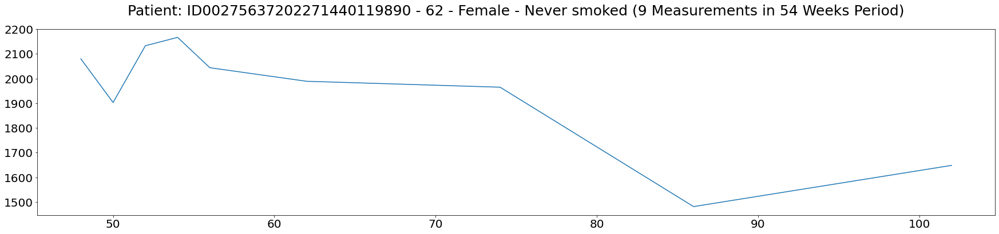

Patient: ID00276637202271694539978 FVC Statistical Summary
----------------------------------------------------------
Mean: 2882.86  -  Median: 2879.0  -  Std: 139.196
Min: 2718 -  Max: 3107
Skew: 0.457052  -  Kurtosis: -0.534599
Change Mean: 126.167  - Change Median: 87.0  - Change Std: 105.232
Change Min: 20.0 -  Change Max: 284.0
Change Skew: 0.832782 -  Change Kurtosis: -1.15423


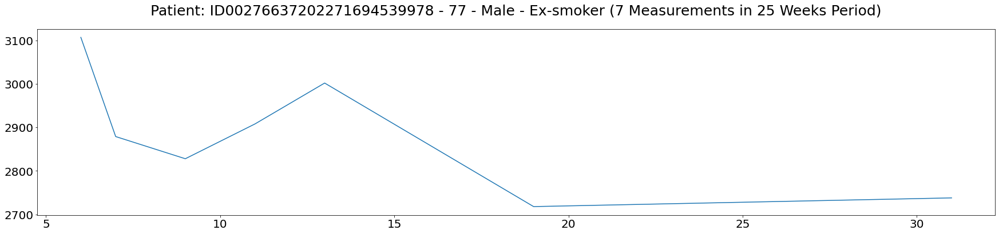

Patient: ID00279637202272164826258 FVC Statistical Summary
----------------------------------------------------------
Mean: 4051.11  -  Median: 4086.0  -  Std: 111.652
Min: 3796 -  Max: 4167
Skew: -1.64846  -  Kurtosis: 3.24916
Change Mean: 87.875  - Change Median: 74.5  - Change Std: 71.3691
Change Min: 26.0 -  Change Max: 250.0
Change Skew: 1.99104 -  Change Kurtosis: 4.58559


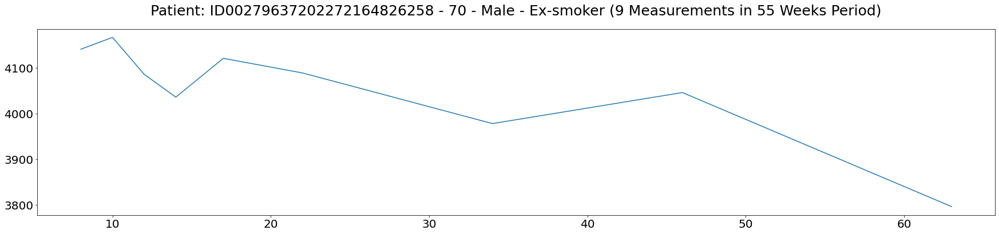

Patient: ID00283637202278714365037 FVC Statistical Summary
----------------------------------------------------------
Mean: 1970.11  -  Median: 1965.0  -  Std: 68.4205
Min: 1854 -  Max: 2109
Skew: 0.556582  -  Kurtosis: 2.29991
Change Mean: 83.875  - Change Median: 96.5  - Change Std: 54.2361
Change Min: 10.0 -  Change Max: 154.0
Change Skew: -0.165923 -  Change Kurtosis: -1.639


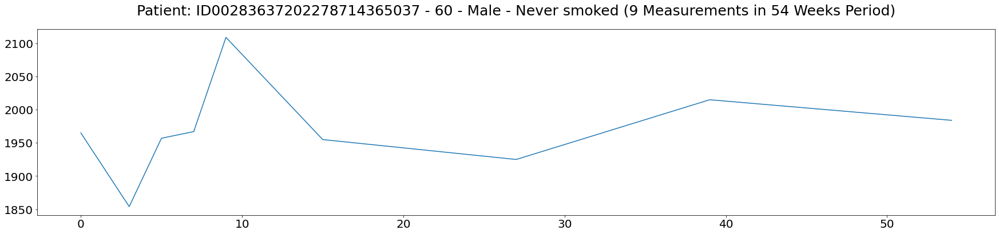

Patient: ID00285637202278913507108 FVC Statistical Summary
----------------------------------------------------------
Mean: 1376.89  -  Median: 1371.0  -  Std: 85.3529
Min: 1276 -  Max: 1528
Skew: 0.45105  -  Kurtosis: -0.697387
Change Mean: 98.125  - Change Median: 85.0  - Change Std: 72.0524
Change Min: 7.0 -  Change Max: 252.0
Change Skew: 1.43215 -  Change Kurtosis: 3.19652


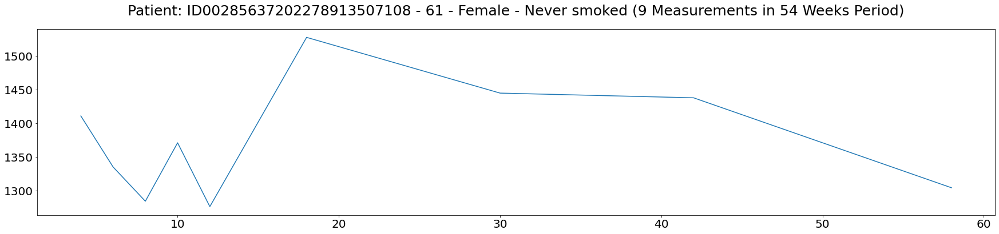

Patient: ID00288637202279148973731 FVC Statistical Summary
----------------------------------------------------------
Mean: 2201.88  -  Median: 2199.0  -  Std: 165.149
Min: 1970 -  Max: 2387
Skew: -0.173618  -  Kurtosis: -1.91226
Change Mean: 104.714  - Change Median: 81.0  - Change Std: 88.2019
Change Min: 5.0 -  Change Max: 257.0
Change Skew: 0.739379 -  Change Kurtosis: -0.0830158


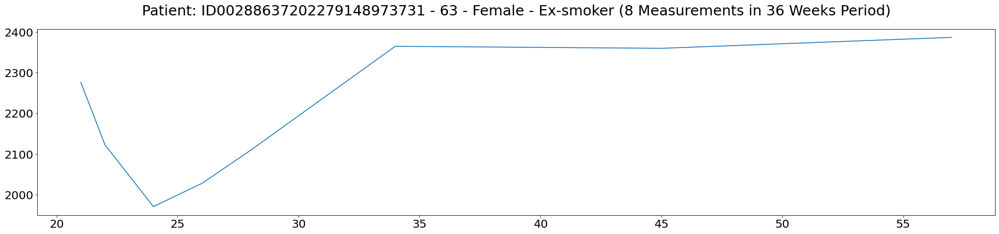

Patient: ID00290637202279304677843 FVC Statistical Summary
----------------------------------------------------------
Mean: 2179.88  -  Median: 2229.0  -  Std: 170.346
Min: 1814 -  Max: 2315
Skew: -1.61119  -  Kurtosis: 2.81072
Change Mean: 167.286  - Change Median: 179.0  - Change Std: 94.8766
Change Min: 15.0 -  Change Max: 321.0
Change Skew: -0.00464131 -  Change Kurtosis: 1.01278


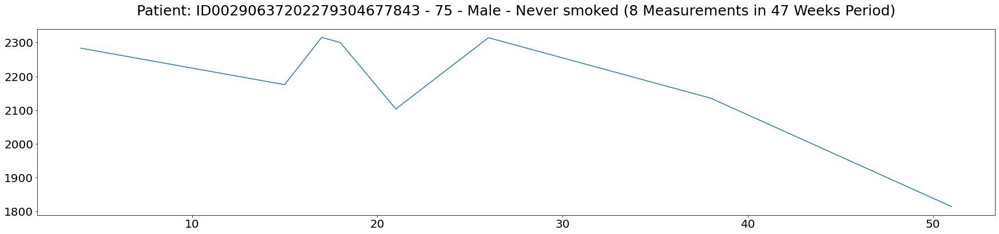

Patient: ID00291637202279398396106 FVC Statistical Summary
----------------------------------------------------------
Mean: 3911.33  -  Median: 4001.0  -  Std: 190.13
Min: 3581 -  Max: 4079
Skew: -1.15817  -  Kurtosis: -0.254964
Change Mean: 132.25  - Change Median: 99.0  - Change Std: 118.802
Change Min: 24.0 -  Change Max: 383.0
Change Skew: 1.51725 -  Change Kurtosis: 2.40992


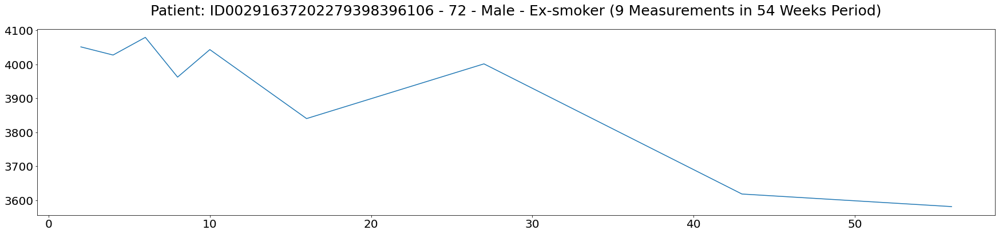

Patient: ID00294637202279614924243 FVC Statistical Summary
----------------------------------------------------------
Mean: 2194.89  -  Median: 2174.0  -  Std: 114.222
Min: 2058 -  Max: 2361
Skew: 0.201675  -  Kurtosis: -1.60835
Change Mean: 73.25  - Change Median: 64.0  - Change Std: 37.2165
Change Min: 34.0 -  Change Max: 117.0
Change Skew: 0.248921 -  Change Kurtosis: -2.28017


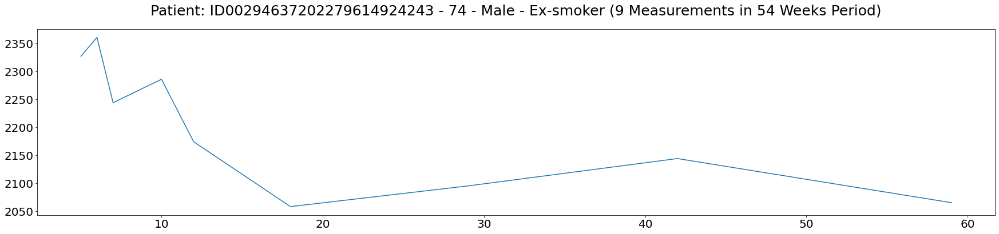

Patient: ID00296637202279895784347 FVC Statistical Summary
----------------------------------------------------------
Mean: 2154.88  -  Median: 2164.5  -  Std: 84.0314
Min: 1990 -  Max: 2258
Skew: -0.991741  -  Kurtosis: 1.24029
Change Mean: 125.857  - Change Median: 128.0  - Change Std: 67.7186
Change Min: 33.0 -  Change Max: 220.0
Change Skew: -0.280703 -  Change Kurtosis: -0.874366


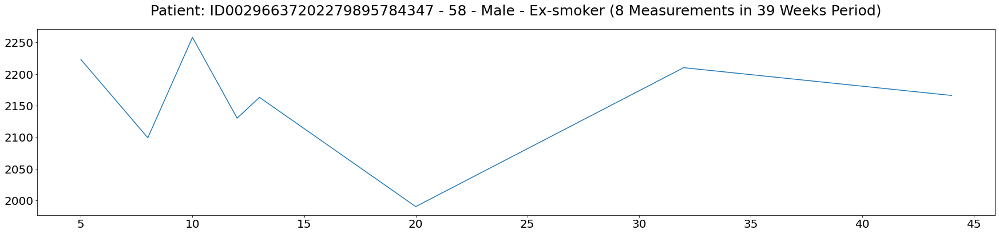

Patient: ID00298637202280361773446 FVC Statistical Summary
----------------------------------------------------------
Mean: 1765.89  -  Median: 1803.0  -  Std: 165.908
Min: 1409 -  Max: 1932
Skew: -1.47424  -  Kurtosis: 1.88367
Change Mean: 115.625  - Change Median: 108.5  - Change Std: 55.5645
Change Min: 49.0 -  Change Max: 187.0
Change Skew: 0.0876297 -  Change Kurtosis: -1.72668


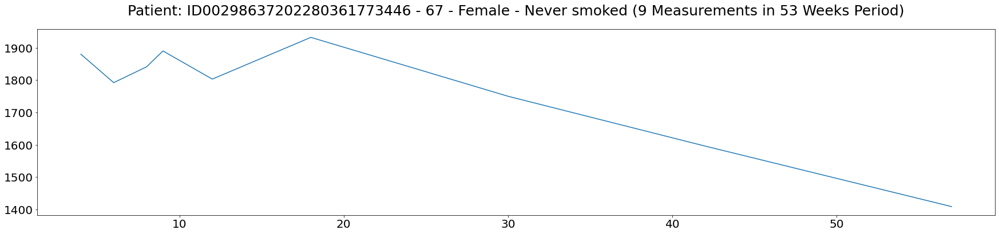

Patient: ID00299637202280383305867 FVC Statistical Summary
----------------------------------------------------------
Mean: 2134.33  -  Median: 2141.0  -  Std: 182.736
Min: 1741 -  Max: 2328
Skew: -1.26639  -  Kurtosis: 1.93661
Change Mean: 153.625  - Change Median: 94.0  - Change Std: 193.09
Change Min: 4.0 -  Change Max: 587.0
Change Skew: 1.9593 -  Change Kurtosis: 4.09692


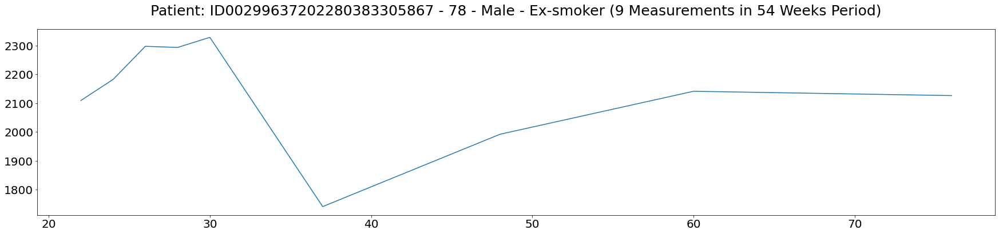

Patient: ID00305637202281772703145 FVC Statistical Summary
----------------------------------------------------------
Mean: 2802.0  -  Median: 2785.0  -  Std: 136.803
Min: 2555 -  Max: 2984
Skew: -0.337136  -  Kurtosis: -0.232704
Change Mean: 111.875  - Change Median: 100.5  - Change Std: 67.6069
Change Min: 32.0 -  Change Max: 227.0
Change Skew: 0.515235 -  Change Kurtosis: -0.770054


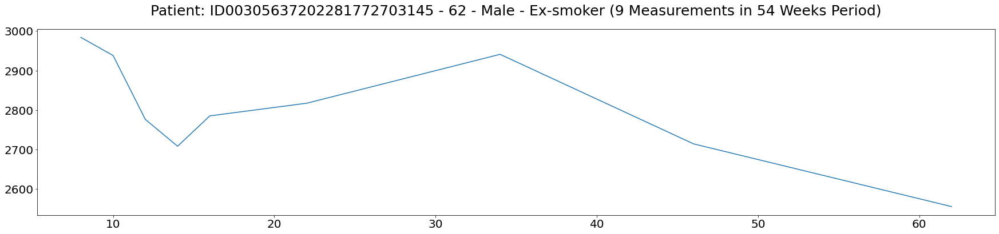

Patient: ID00307637202282126172865 FVC Statistical Summary
----------------------------------------------------------
Mean: 3073.67  -  Median: 3166.0  -  Std: 195.007
Min: 2762 -  Max: 3292
Skew: -0.682202  -  Kurtosis: -1.29828
Change Mean: 96.625  - Change Median: 74.5  - Change Std: 75.5569
Change Min: 37.0 -  Change Max: 272.0
Change Skew: 2.2021 -  Change Kurtosis: 5.28729


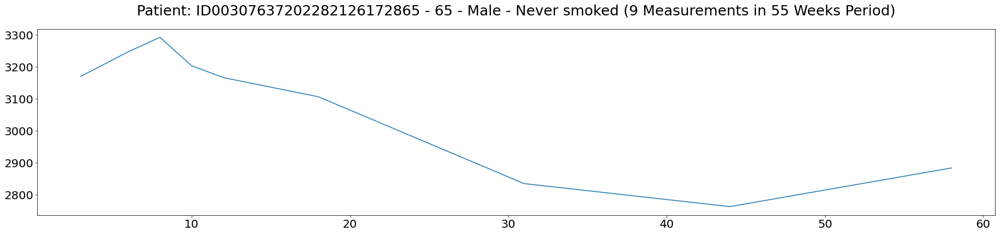

Patient: ID00309637202282195513787 FVC Statistical Summary
----------------------------------------------------------
Mean: 3140.22  -  Median: 3180.0  -  Std: 190.231
Min: 2828 -  Max: 3499
Skew: 0.168412  -  Kurtosis: 1.20725
Change Mean: 196.375  - Change Median: 145.0  - Change Std: 161.038
Change Min: 4.0 -  Change Max: 400.0
Change Skew: 0.305232 -  Change Kurtosis: -2.04229


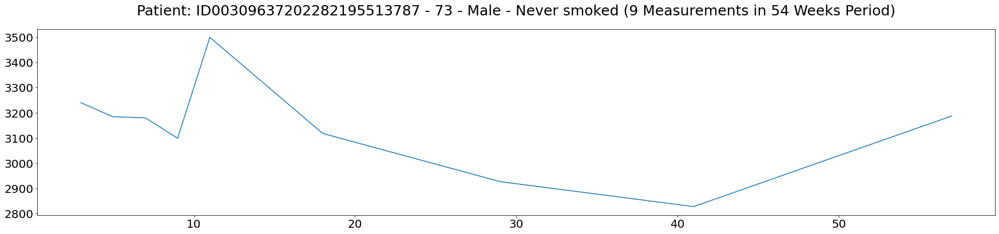

Patient: ID00312637202282607344793 FVC Statistical Summary
----------------------------------------------------------
Mean: 1761.89  -  Median: 1765.0  -  Std: 116.012
Min: 1571 -  Max: 1919
Skew: -0.402292  -  Kurtosis: -0.545097
Change Mean: 82.0  - Change Median: 78.0  - Change Std: 69.6071
Change Min: 0.0 -  Change Max: 178.0
Change Skew: 0.163267 -  Change Kurtosis: -2.03098


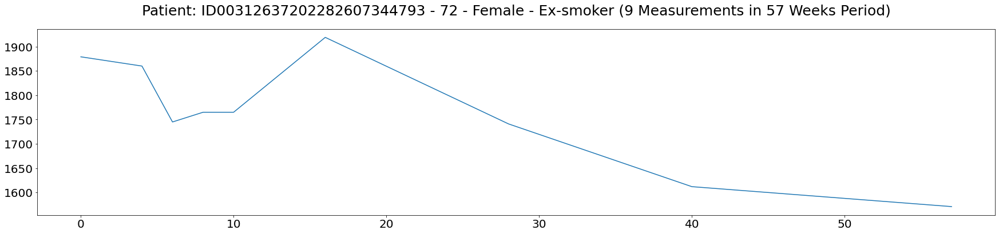

Patient: ID00317637202283194142136 FVC Statistical Summary
----------------------------------------------------------
Mean: 2154.0  -  Median: 2270.0  -  Std: 257.766
Min: 1653 -  Max: 2375
Skew: -1.42917  -  Kurtosis: 0.885989
Change Mean: 150.571  - Change Median: 70.0  - Change Std: 172.525
Change Min: 42.0 -  Change Max: 520.0
Change Skew: 2.13241 -  Change Kurtosis: 4.60543


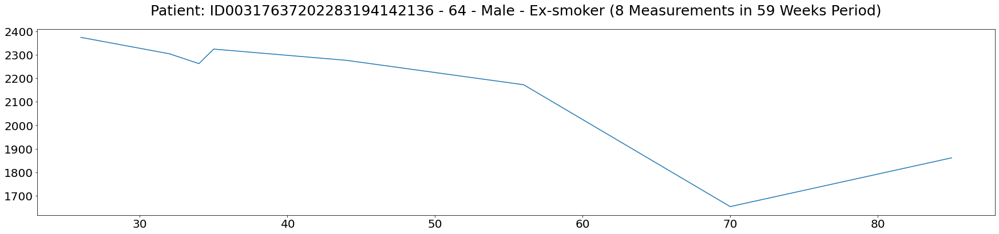

Patient: ID00319637202283897208687 FVC Statistical Summary
----------------------------------------------------------
Mean: 4078.22  -  Median: 4218.0  -  Std: 425.855
Min: 2951 -  Max: 4287
Skew: -2.91589  -  Kurtosis: 8.62329
Change Mean: 360.875  - Change Median: 68.0  - Change Std: 560.209
Change Min: 9.0 -  Change Max: 1336.0
Change Skew: 1.43848 -  Change Kurtosis: 0.100019


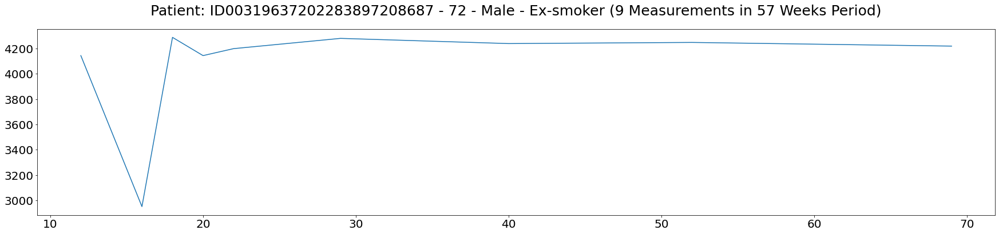

Patient: ID00322637202284842245491 FVC Statistical Summary
----------------------------------------------------------
Mean: 2498.0  -  Median: 2460.0  -  Std: 159.386
Min: 2311 -  Max: 2795
Skew: 0.56112  -  Kurtosis: -0.193021
Change Mean: 108.375  - Change Median: 72.5  - Change Std: 118.016
Change Min: 6.0 -  Change Max: 339.0
Change Skew: 1.19055 -  Change Kurtosis: 0.81093


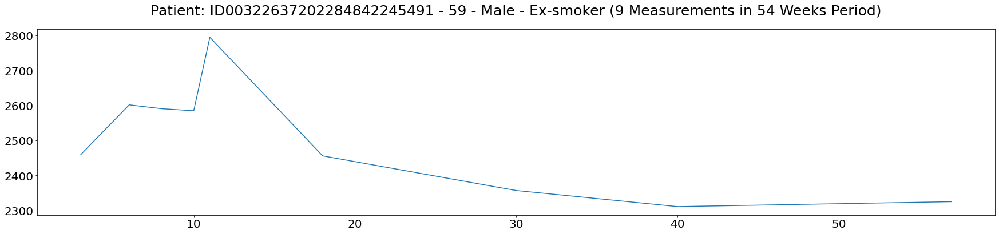

Patient: ID00323637202285211956970 FVC Statistical Summary
----------------------------------------------------------
Mean: 1629.12  -  Median: 1612.5  -  Std: 130.63
Min: 1412 -  Max: 1818
Skew: -0.145598  -  Kurtosis: -0.318031
Change Mean: 144.286  - Change Median: 126.0  - Change Std: 84.9896
Change Min: 11.0 -  Change Max: 257.0
Change Skew: -0.14797 -  Change Kurtosis: -0.521971


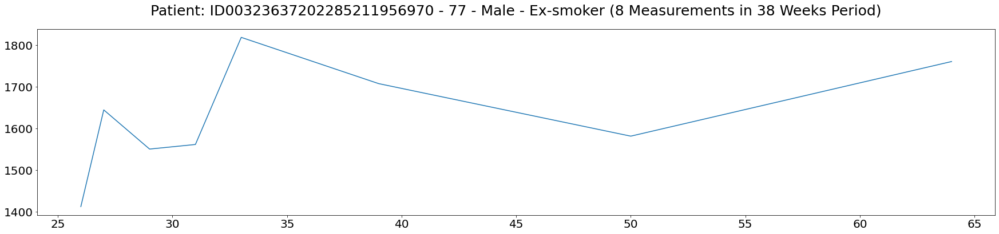

Patient: ID00329637202285906759848 FVC Statistical Summary
----------------------------------------------------------
Mean: 2796.67  -  Median: 2805.0  -  Std: 123.057
Min: 2618 -  Max: 3051
Skew: 0.777149  -  Kurtosis: 1.77763
Change Mean: 152.25  - Change Median: 140.5  - Change Std: 122.332
Change Min: 8.0 -  Change Max: 317.0
Change Skew: 0.156857 -  Change Kurtosis: -2.13694


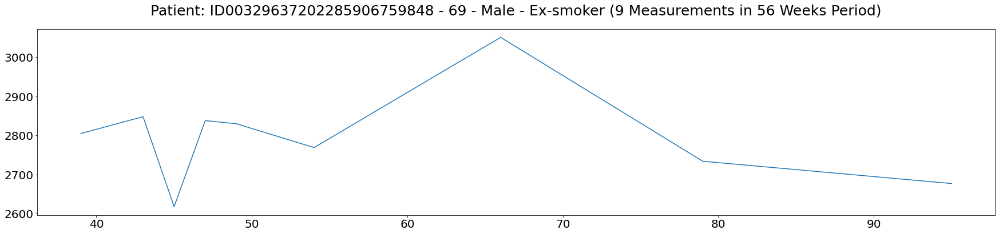

Patient: ID00331637202286306023714 FVC Statistical Summary
----------------------------------------------------------
Mean: 3141.78  -  Median: 3153.0  -  Std: 105.089
Min: 2965 -  Max: 3272
Skew: -0.805972  -  Kurtosis: -0.266329
Change Mean: 107.25  - Change Median: 96.0  - Change Std: 58.1052
Change Min: 21.0 -  Change Max: 212.0
Change Skew: 0.505798 -  Change Kurtosis: 0.592362


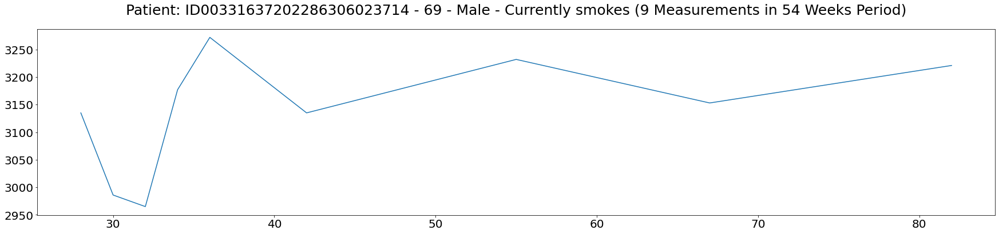

Patient: ID00335637202286784464927 FVC Statistical Summary
----------------------------------------------------------
Mean: 2636.67  -  Median: 2598.0  -  Std: 168.347
Min: 2467 -  Max: 3043
Skew: 1.99925  -  Kurtosis: 4.9183
Change Mean: 110.75  - Change Median: 81.0  - Change Std: 100.058
Change Min: 38.0 -  Change Max: 349.0
Change Skew: 2.4204 -  Change Kurtosis: 6.29261


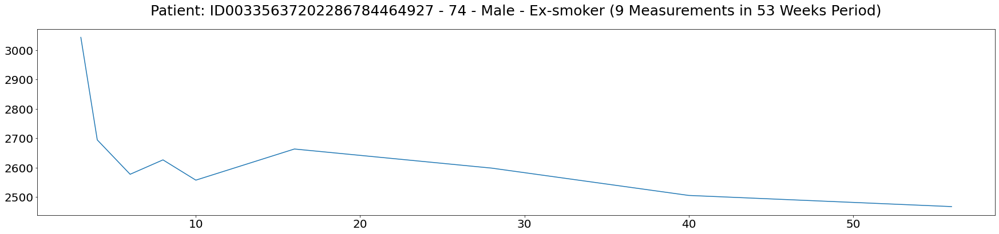

Patient: ID00336637202286801879145 FVC Statistical Summary
----------------------------------------------------------
Mean: 2516.88  -  Median: 2547.0  -  Std: 92.3927
Min: 2294 -  Max: 2570
Skew: -2.56573  -  Kurtosis: 6.80932
Change Mean: 46.1429  - Change Median: 20.0  - Change Std: 73.7505
Change Min: 3.0 -  Change Max: 211.0
Change Skew: 2.49251 -  Change Kurtosis: 6.36658


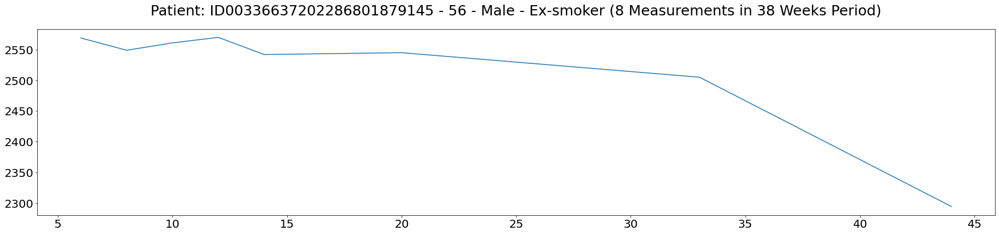

Patient: ID00337637202286839091062 FVC Statistical Summary
----------------------------------------------------------
Mean: 3921.11  -  Median: 3941.0  -  Std: 133.918
Min: 3625 -  Max: 4096
Skew: -1.21266  -  Kurtosis: 2.9106
Change Mean: 137.125  - Change Median: 127.0  - Change Std: 111.603
Change Min: 6.0 -  Change Max: 316.0
Change Skew: 0.620441 -  Change Kurtosis: -0.662649


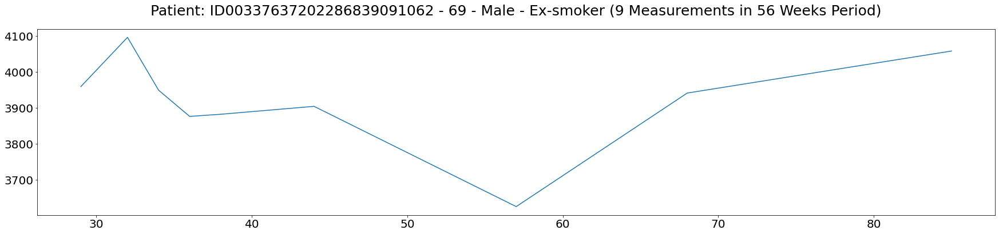

Patient: ID00339637202287377736231 FVC Statistical Summary
----------------------------------------------------------
Mean: 3375.11  -  Median: 3421.0  -  Std: 185.595
Min: 2968 -  Max: 3574
Skew: -1.35817  -  Kurtosis: 2.34833
Change Mean: 90.5  - Change Median: 48.0  - Change Std: 93.2983
Change Min: 9.0 -  Change Max: 286.0
Change Skew: 1.54983 -  Change Kurtosis: 2.14919


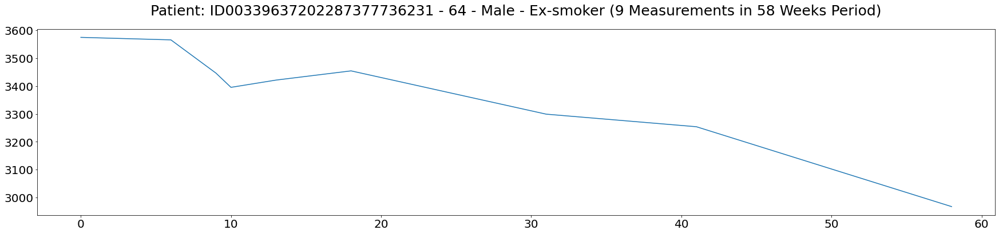

Patient: ID00340637202287399835821 FVC Statistical Summary
----------------------------------------------------------
Mean: 2237.67  -  Median: 2253.0  -  Std: 106.671
Min: 2000 -  Max: 2346
Skew: -1.4751  -  Kurtosis: 2.69108
Change Mean: 86.375  - Change Median: 60.5  - Change Std: 70.8377
Change Min: 11.0 -  Change Max: 222.0
Change Skew: 1.19249 -  Change Kurtosis: 0.695174


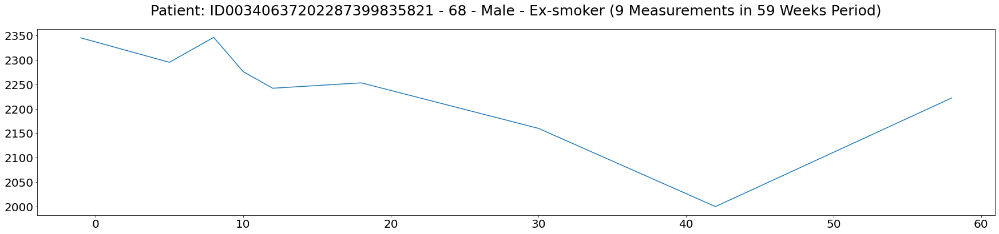

Patient: ID00341637202287410878488 FVC Statistical Summary
----------------------------------------------------------
Mean: 2822.33  -  Median: 2849.0  -  Std: 58.5811
Min: 2701 -  Max: 2891
Skew: -1.12577  -  Kurtosis: 1.18379
Change Mean: 66.75  - Change Median: 57.0  - Change Std: 39.8381
Change Min: 2.0 -  Change Max: 118.0
Change Skew: -0.134152 -  Change Kurtosis: -0.753679


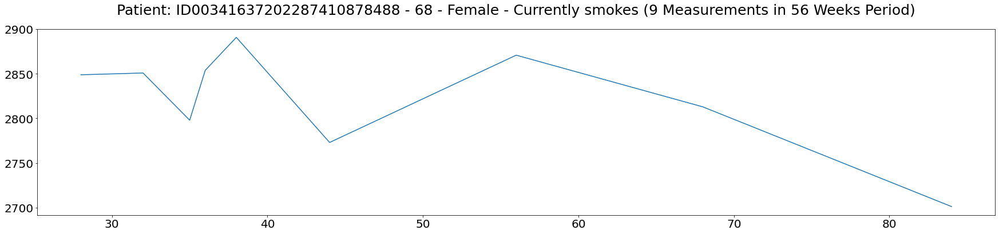

Patient: ID00342637202287526592911 FVC Statistical Summary
----------------------------------------------------------
Mean: 2102.78  -  Median: 2062.0  -  Std: 195.431
Min: 1865 -  Max: 2390
Skew: 0.325965  -  Kurtosis: -1.52369
Change Mean: 83.375  - Change Median: 65.5  - Change Std: 71.3201
Change Min: 17.0 -  Change Max: 197.0
Change Skew: 1.03583 -  Change Kurtosis: -0.504065


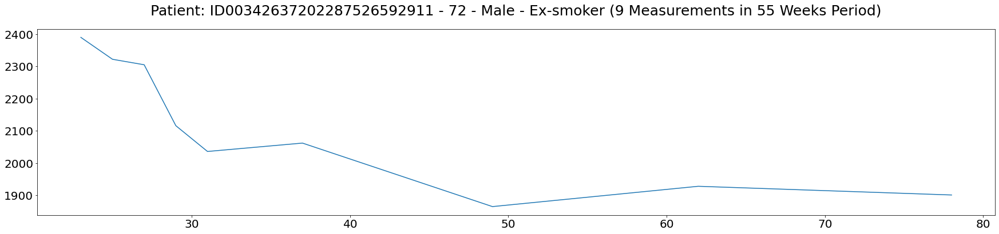

Patient: ID00343637202287577133798 FVC Statistical Summary
----------------------------------------------------------
Mean: 1551.6  -  Median: 1531.0  -  Std: 90.2862
Min: 1383 -  Max: 1699
Skew: -0.165129  -  Kurtosis: 0.21316
Change Mean: 105.333  - Change Median: 95.0  - Change Std: 63.9512
Change Min: 14.0 -  Change Max: 207.0
Change Skew: 0.313107 -  Change Kurtosis: -0.579756


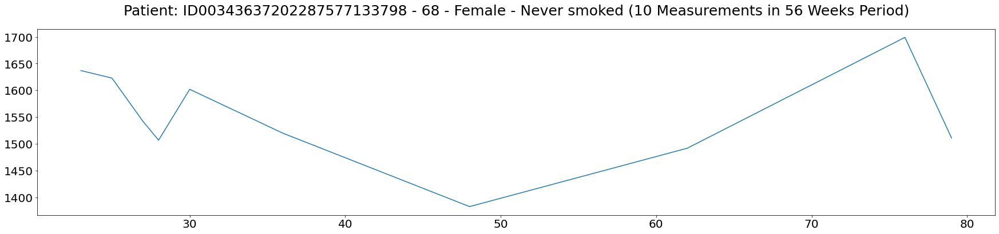

Patient: ID00344637202287684217717 FVC Statistical Summary
----------------------------------------------------------
Mean: 1992.14  -  Median: 2020.0  -  Std: 89.8637
Min: 1812 -  Max: 2074
Skew: -1.56432  -  Kurtosis: 2.7077
Change Mean: 56.0  - Change Median: 43.5  - Change Std: 46.1433
Change Min: 8.0 -  Change Max: 142.0
Change Skew: 1.55796 -  Change Kurtosis: 3.06875


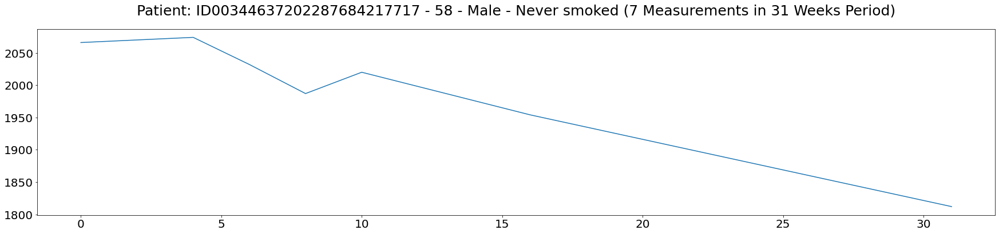

Patient: ID00351637202289476567312 FVC Statistical Summary
----------------------------------------------------------
Mean: 2617.78  -  Median: 2627.0  -  Std: 137.987
Min: 2441 -  Max: 2808
Skew: 0.0515431  -  Kurtosis: -1.55284
Change Mean: 157.5  - Change Median: 139.0  - Change Std: 136.127
Change Min: 4.0 -  Change Max: 367.0
Change Skew: 0.426601 -  Change Kurtosis: -1.13546


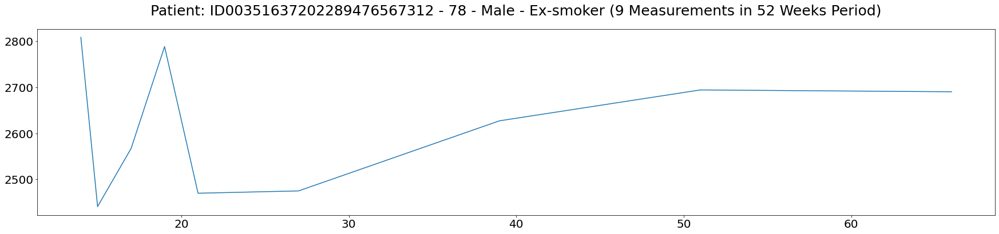

Patient: ID00355637202295106567614 FVC Statistical Summary
----------------------------------------------------------
Mean: 4453.56  -  Median: 4447.0  -  Std: 336.468
Min: 3681 -  Max: 4791
Skew: -1.57922  -  Kurtosis: 3.46188
Change Mean: 305.125  - Change Median: 219.5  - Change Std: 284.931
Change Min: 32.0 -  Change Max: 737.0
Change Skew: 0.937933 -  Change Kurtosis: -0.724997


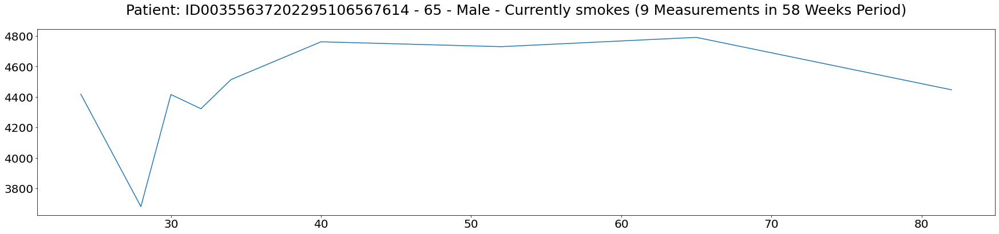

Patient: ID00358637202295388077032 FVC Statistical Summary
----------------------------------------------------------
Mean: 2017.0  -  Median: 2032.0  -  Std: 105.6
Min: 1823 -  Max: 2151
Skew: -0.584747  -  Kurtosis: 0.590487
Change Mean: 134.714  - Change Median: 108.0  - Change Std: 107.865
Change Min: 1.0 -  Change Max: 328.0
Change Skew: 0.819389 -  Change Kurtosis: 0.771015


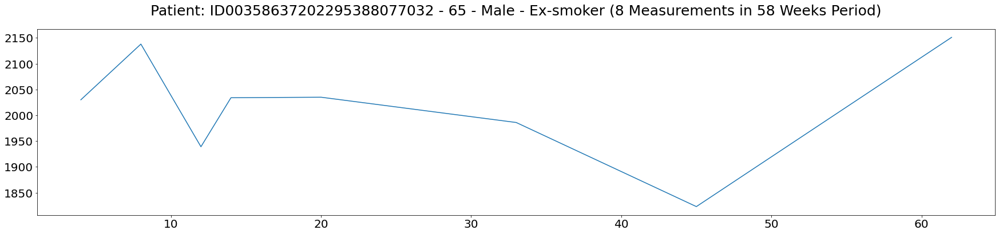

Patient: ID00360637202295712204040 FVC Statistical Summary
----------------------------------------------------------
Mean: 2835.44  -  Median: 2760.0  -  Std: 146.821
Min: 2687 -  Max: 3107
Skew: 0.861197  -  Kurtosis: -0.450226
Change Mean: 125.25  - Change Median: 126.5  - Change Std: 93.8293
Change Min: 15.0 -  Change Max: 284.0
Change Skew: 0.426651 -  Change Kurtosis: -0.717883


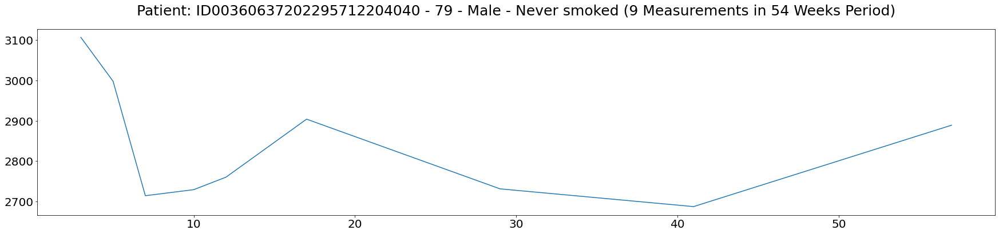

Patient: ID00364637202296074419422 FVC Statistical Summary
----------------------------------------------------------
Mean: 2851.89  -  Median: 3032.0  -  Std: 333.106
Min: 2170 -  Max: 3191
Skew: -1.32276  -  Kurtosis: 1.03973
Change Mean: 189.875  - Change Median: 164.0  - Change Std: 194.214
Change Min: 13.0 -  Change Max: 598.0
Change Skew: 1.44535 -  Change Kurtosis: 2.3527


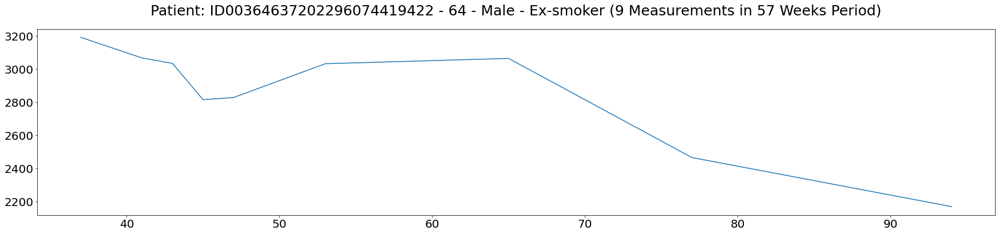

Patient: ID00365637202296085035729 FVC Statistical Summary
----------------------------------------------------------
Mean: 2349.62  -  Median: 2366.5  -  Std: 138.773
Min: 2122 -  Max: 2581
Skew: -0.0374394  -  Kurtosis: 0.476491
Change Mean: 131.286  - Change Median: 165.0  - Change Std: 78.2234
Change Min: 18.0 -  Change Max: 246.0
Change Skew: -0.0909174 -  Change Kurtosis: -0.807853


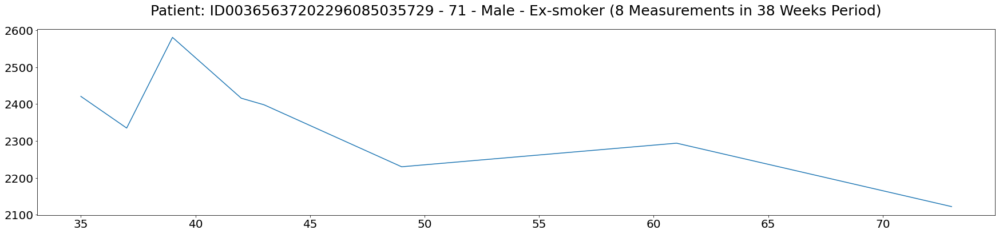

Patient: ID00367637202296290303449 FVC Statistical Summary
----------------------------------------------------------
Mean: 1328.0  -  Median: 1332.0  -  Std: 204.937
Min: 837 -  Max: 1593
Skew: -1.80738  -  Kurtosis: 5.06219
Change Mean: 158.625  - Change Median: 110.5  - Change Std: 165.757
Change Min: 8.0 -  Change Max: 478.0
Change Skew: 1.06042 -  Change Kurtosis: 0.536547


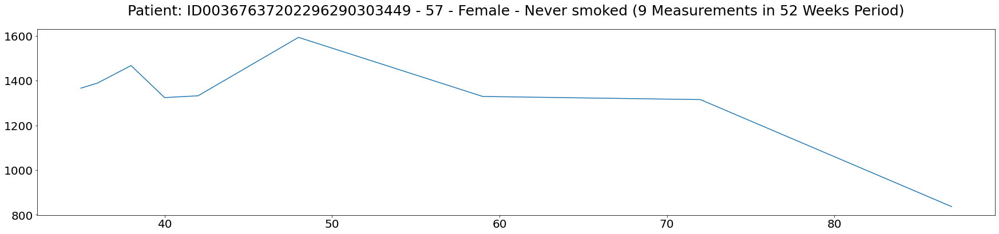

Patient: ID00368637202296470751086 FVC Statistical Summary
----------------------------------------------------------
Mean: 2973.11  -  Median: 2964.0  -  Std: 114.534
Min: 2801 -  Max: 3128
Skew: -0.313911  -  Kurtosis: -0.73072
Change Mean: 132.625  - Change Median: 151.5  - Change Std: 60.2944
Change Min: 32.0 -  Change Max: 218.0
Change Skew: -0.453733 -  Change Kurtosis: -0.419755


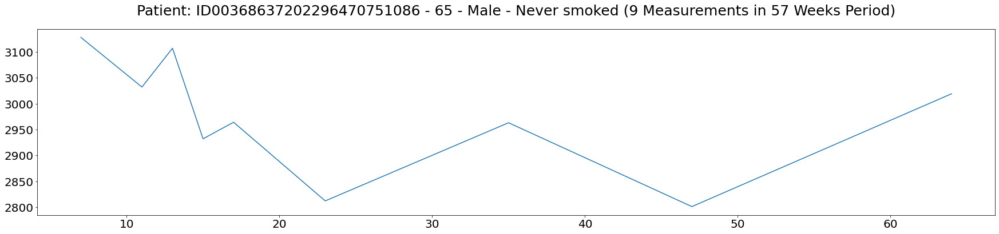

Patient: ID00370637202296737666151 FVC Statistical Summary
----------------------------------------------------------
Mean: 2243.44  -  Median: 2243.0  -  Std: 31.2134
Min: 2209 -  Max: 2308
Skew: 1.04717  -  Kurtosis: 1.28141
Change Mean: 38.25  - Change Median: 28.5  - Change Std: 28.0802
Change Min: 7.0 -  Change Max: 97.0
Change Skew: 1.52276 -  Change Kurtosis: 2.39254


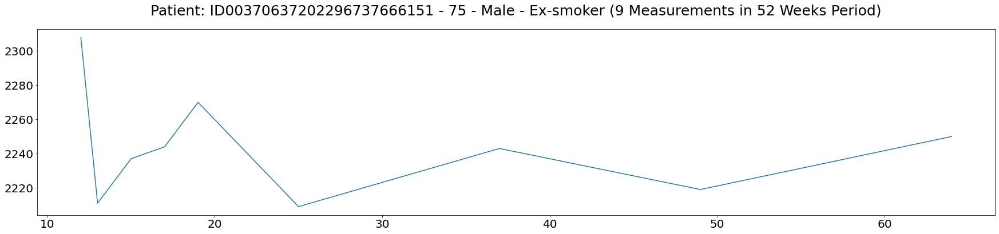

Patient: ID00371637202296828615743 FVC Statistical Summary
----------------------------------------------------------
Mean: 2445.78  -  Median: 2470.0  -  Std: 84.7301
Min: 2232 -  Max: 2510
Skew: -2.43034  -  Kurtosis: 6.46455
Change Mean: 53.75  - Change Median: 37.0  - Change Std: 57.0833
Change Min: 4.0 -  Change Max: 187.0
Change Skew: 2.21933 -  Change Kurtosis: 5.55814


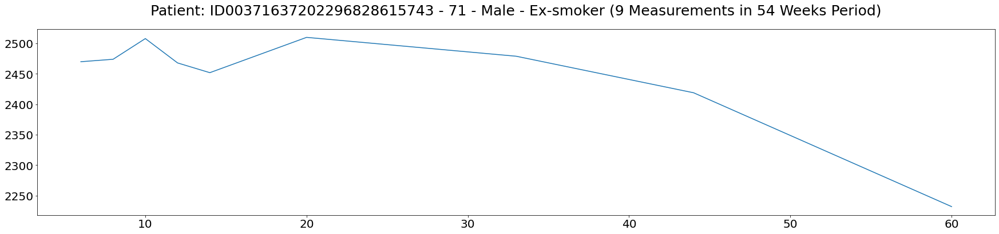

Patient: ID00376637202297677828573 FVC Statistical Summary
----------------------------------------------------------
Mean: 4260.44  -  Median: 4284.0  -  Std: 87.3629
Min: 4125 -  Max: 4386
Skew: -0.344499  -  Kurtosis: -1.05626
Change Mean: 69.125  - Change Median: 66.0  - Change Std: 53.0483
Change Min: 1.0 -  Change Max: 163.0
Change Skew: 0.73906 -  Change Kurtosis: 0.0422225


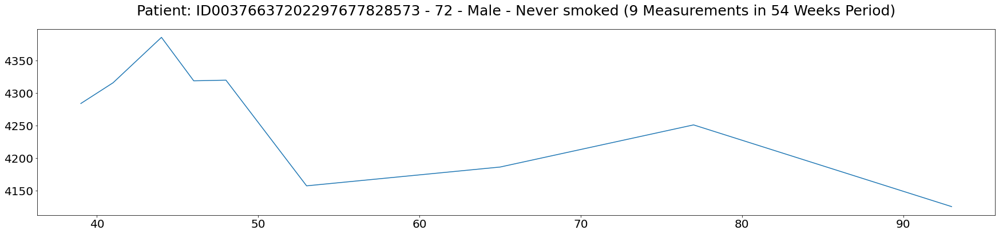

Patient: ID00378637202298597306391 FVC Statistical Summary
----------------------------------------------------------
Mean: 3317.56  -  Median: 3290.0  -  Std: 211.915
Min: 2939 -  Max: 3629
Skew: 0.0311387  -  Kurtosis: 0.602102
Change Mean: 183.125  - Change Median: 95.0  - Change Std: 163.623
Change Min: 6.0 -  Change Max: 439.0
Change Skew: 0.661388 -  Change Kurtosis: -1.55455


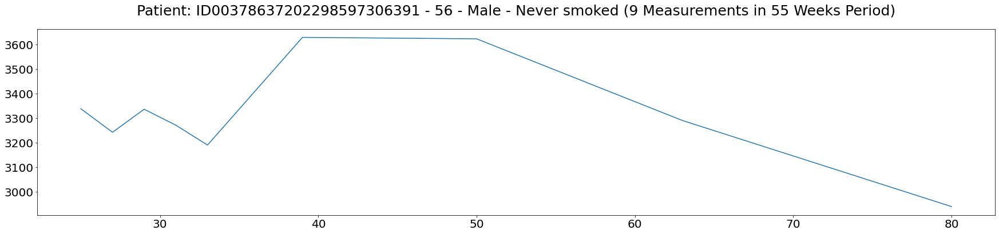

Patient: ID00381637202299644114027 FVC Statistical Summary
----------------------------------------------------------
Mean: 2179.29  -  Median: 2202.0  -  Std: 165.057
Min: 1996 -  Max: 2415
Skew: 0.183587  -  Kurtosis: -1.57935
Change Mean: 100.833  - Change Median: 113.0  - Change Std: 60.4332
Change Min: 1.0 -  Change Max: 173.0
Change Skew: -0.783503 -  Change Kurtosis: 0.548051


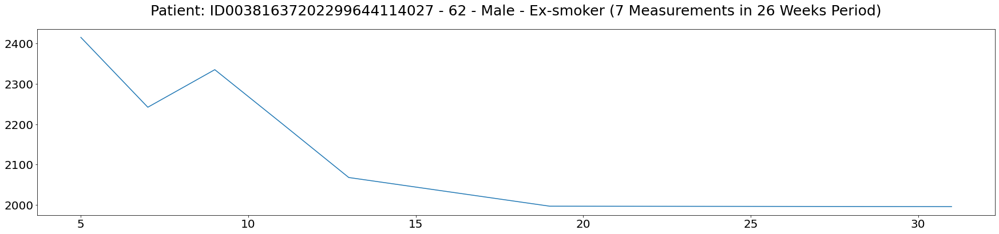

Patient: ID00383637202300493233675 FVC Statistical Summary
----------------------------------------------------------
Mean: 3096.33  -  Median: 3109.0  -  Std: 121.471
Min: 2862 -  Max: 3246
Skew: -0.626208  -  Kurtosis: 0.403061
Change Mean: 114.125  - Change Median: 125.0  - Change Std: 51.6871
Change Min: 45.0 -  Change Max: 174.0
Change Skew: -0.196522 -  Change Kurtosis: -1.86307


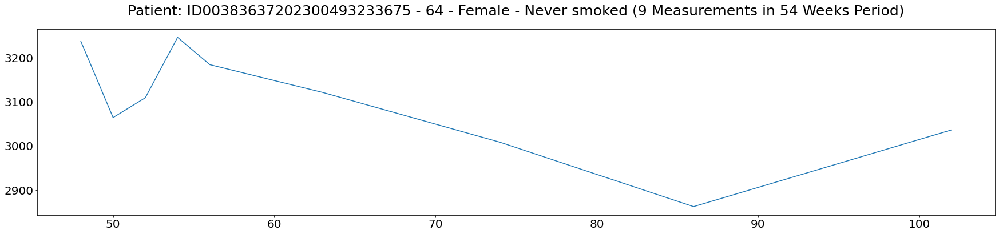

Patient: ID00388637202301028491611 FVC Statistical Summary
----------------------------------------------------------
Mean: 3033.4  -  Median: 3043.5  -  Std: 142.357
Min: 2756 -  Max: 3282
Skew: -0.337297  -  Kurtosis: 1.21863
Change Mean: 111.667  - Change Median: 102.0  - Change Std: 84.9323
Change Min: 16.0 -  Change Max: 240.0
Change Skew: 0.511207 -  Change Kurtosis: -1.09828


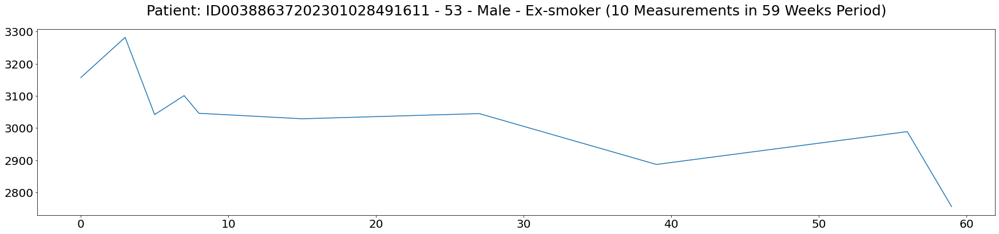

Patient: ID00392637202302319160044 FVC Statistical Summary
----------------------------------------------------------
Mean: 2048.89  -  Median: 2058.0  -  Std: 151.858
Min: 1808 -  Max: 2231
Skew: -0.576882  -  Kurtosis: -0.708264
Change Mean: 84.875  - Change Median: 86.0  - Change Std: 53.4427
Change Min: 18.0 -  Change Max: 166.0
Change Skew: 0.0973081 -  Change Kurtosis: -1.33097


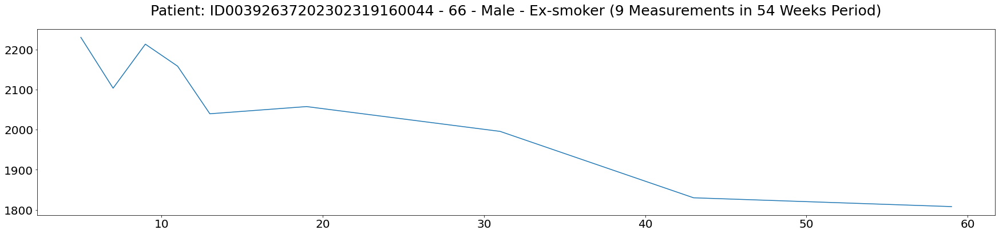

Patient: ID00393637202302431697467 FVC Statistical Summary
----------------------------------------------------------
Mean: 3671.67  -  Median: 3589.0  -  Std: 148.499
Min: 3540 -  Max: 3936
Skew: 1.11078  -  Kurtosis: -0.363154
Change Mean: 170.25  - Change Median: 154.0  - Change Std: 142.499
Change Min: 1.0 -  Change Max: 374.0
Change Skew: 0.347157 -  Change Kurtosis: -1.47051


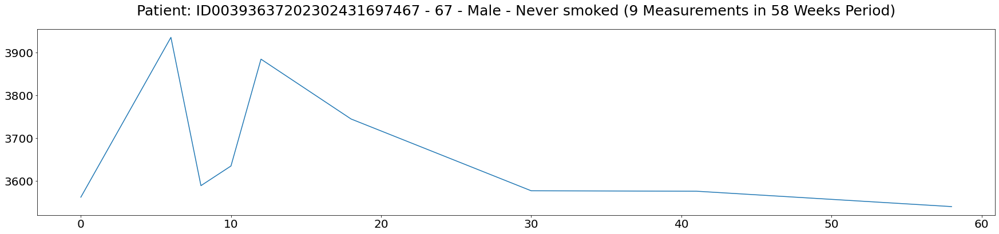

Patient: ID00398637202303897337979 FVC Statistical Summary
----------------------------------------------------------
Mean: 2632.0  -  Median: 2700.0  -  Std: 320.283
Min: 2083 -  Max: 3046
Skew: -0.539352  -  Kurtosis: -0.535678
Change Mean: 137.571  - Change Median: 131.0  - Change Std: 86.9307
Change Min: 31.0 -  Change Max: 266.0
Change Skew: 0.157611 -  Change Kurtosis: -1.03165


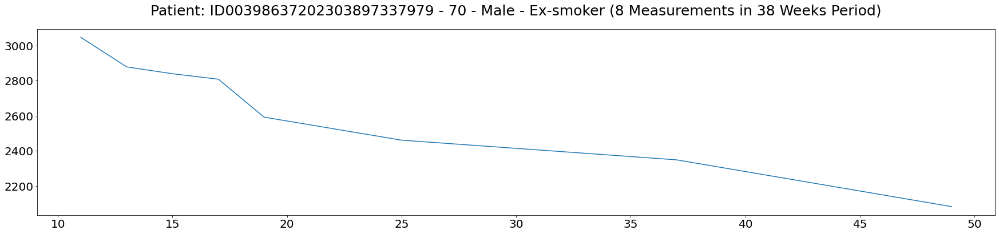

Patient: ID00400637202305055099402 FVC Statistical Summary
----------------------------------------------------------
Mean: 3922.0  -  Median: 3930.0  -  Std: 68.5468
Min: 3797 -  Max: 4014
Skew: -0.32437  -  Kurtosis: -0.263367
Change Mean: 68.4444  - Change Median: 64.0  - Change Std: 62.674
Change Min: 1.0 -  Change Max: 217.0
Change Skew: 1.84649 -  Change Kurtosis: 4.35732


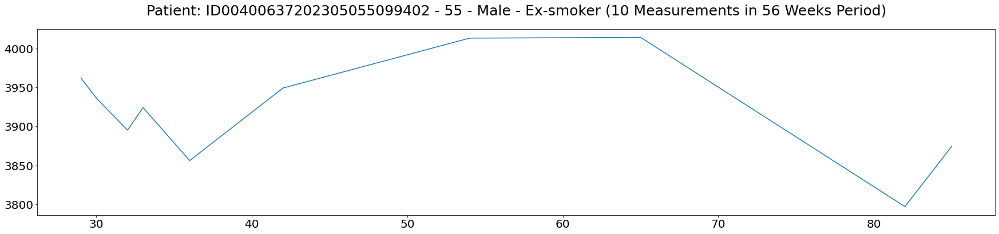

Patient: ID00401637202305320178010 FVC Statistical Summary
----------------------------------------------------------
Mean: 1894.44  -  Median: 1889.0  -  Std: 140.8
Min: 1734 -  Max: 2184
Skew: 0.998668  -  Kurtosis: 1.12914
Change Mean: 114.75  - Change Median: 107.0  - Change Std: 89.5828
Change Min: 3.0 -  Change Max: 242.0
Change Skew: 0.173461 -  Change Kurtosis: -1.50371


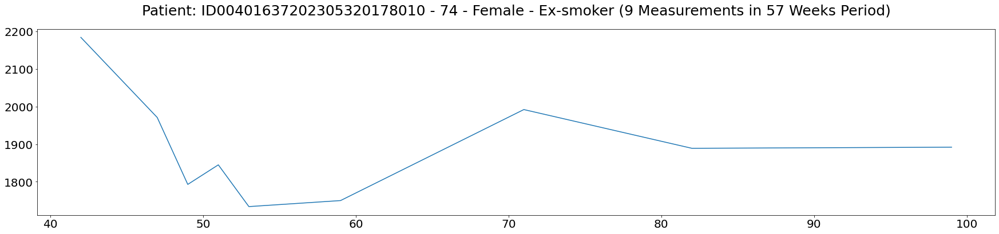

Patient: ID00405637202308359492977 FVC Statistical Summary
----------------------------------------------------------
Mean: 1534.56  -  Median: 1547.0  -  Std: 59.353
Min: 1412 -  Max: 1603
Skew: -1.23706  -  Kurtosis: 1.28156
Change Mean: 73.125  - Change Median: 77.5  - Change Std: 51.6401
Change Min: 14.0 -  Change Max: 135.0
Change Skew: -0.0293167 -  Change Kurtosis: -2.0879


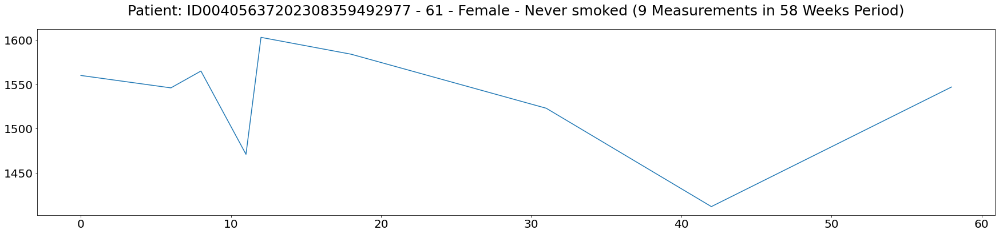

Patient: ID00407637202308788732304 FVC Statistical Summary
----------------------------------------------------------
Mean: 3095.56  -  Median: 3096.0  -  Std: 100.587
Min: 2944 -  Max: 3201
Skew: -0.427064  -  Kurtosis: -1.48911
Change Mean: 76.25  - Change Median: 60.5  - Change Std: 63.457
Change Min: 11.0 -  Change Max: 158.0
Change Skew: 0.319817 -  Change Kurtosis: -2.09906


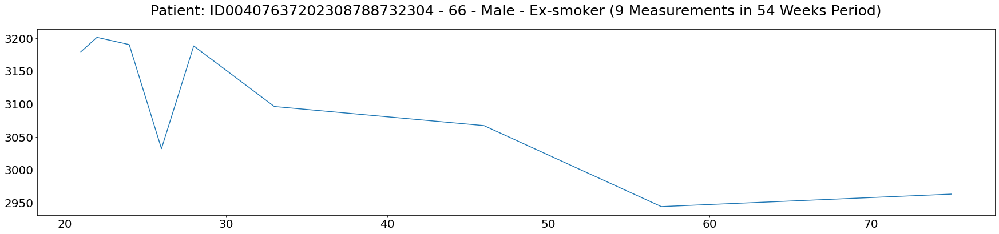

Patient: ID00408637202308839708961 FVC Statistical Summary
----------------------------------------------------------
Mean: 2412.62  -  Median: 2399.0  -  Std: 132.242
Min: 2181 -  Max: 2651
Skew: 0.144551  -  Kurtosis: 2.02977
Change Mean: 136.429  - Change Median: 130.0  - Change Std: 91.431
Change Min: 30.0 -  Change Max: 274.0
Change Skew: 0.237329 -  Change Kurtosis: -1.26236


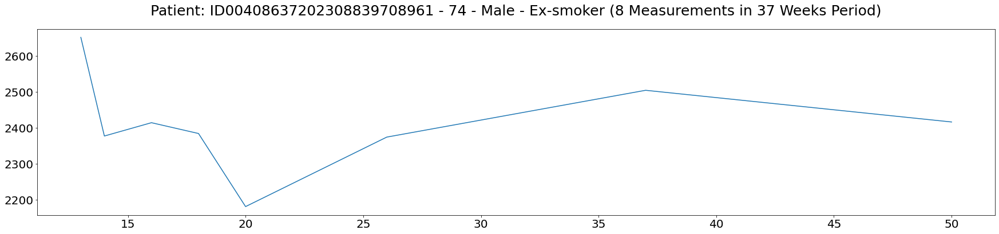

Patient: ID00411637202309374271828 FVC Statistical Summary
----------------------------------------------------------
Mean: 1722.67  -  Median: 1746.0  -  Std: 90.3147
Min: 1556 -  Max: 1843
Skew: -0.577061  -  Kurtosis: -0.226545
Change Mean: 108.75  - Change Median: 100.0  - Change Std: 56.3858
Change Min: 55.0 -  Change Max: 232.0
Change Skew: 1.68188 -  Change Kurtosis: 3.42416


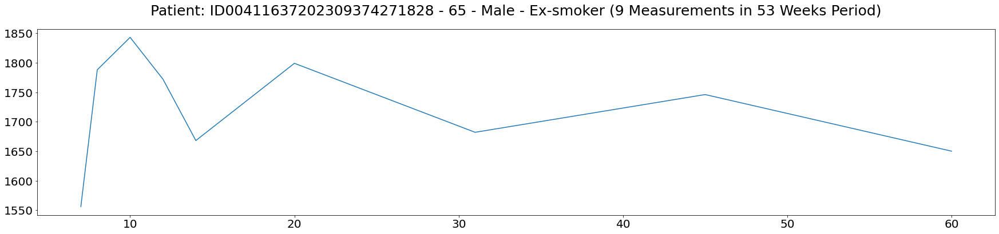

Patient: ID00414637202310318891556 FVC Statistical Summary
----------------------------------------------------------
Mean: 2440.78  -  Median: 2612.0  -  Std: 425.608
Min: 1612 -  Max: 3006
Skew: -0.710963  -  Kurtosis: 0.493014
Change Mean: 282.875  - Change Median: 281.0  - Change Std: 166.168
Change Min: 10.0 -  Change Max: 549.0
Change Skew: -0.123055 -  Change Kurtosis: 0.196574


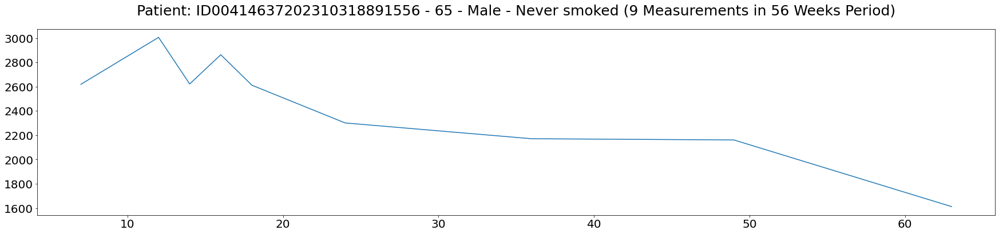

Patient: ID00417637202310901214011 FVC Statistical Summary
----------------------------------------------------------
Mean: 3317.56  -  Median: 3305.0  -  Std: 53.0144
Min: 3240 -  Max: 3397
Skew: 0.00669156  -  Kurtosis: -1.29944
Change Mean: 77.5  - Change Median: 72.0  - Change Std: 35.1202
Change Min: 40.0 -  Change Max: 124.0
Change Skew: 0.34915 -  Change Kurtosis: -1.69453


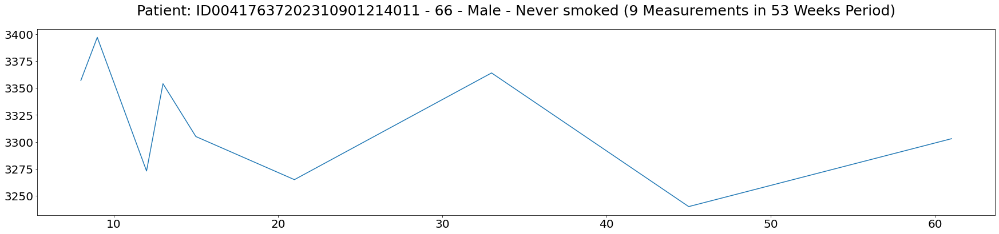

Patient: ID00419637202311204720264 FVC Statistical Summary
----------------------------------------------------------
Mean: 2782.33  -  Median: 2738.0  -  Std: 102.983
Min: 2694 -  Max: 3020
Skew: 1.80493  -  Kurtosis: 3.39667
Change Mean: 66.125  - Change Median: 65.0  - Change Std: 46.1161
Change Min: 14.0 -  Change Max: 161.0
Change Skew: 1.17415 -  Change Kurtosis: 2.20397


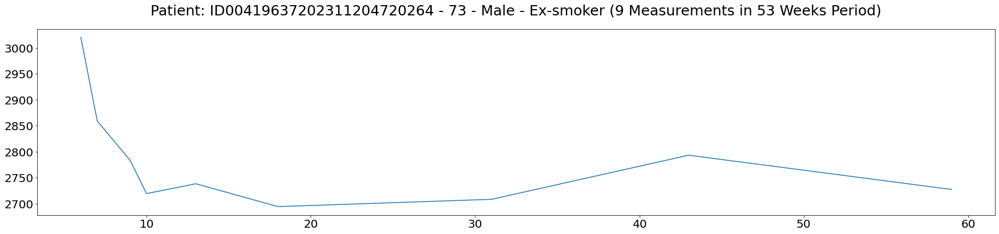

Patient: ID00421637202311550012437 FVC Statistical Summary
----------------------------------------------------------
Mean: 2759.0  -  Median: 2755.5  -  Std: 66.0067
Min: 2628 -  Max: 2853
Skew: -0.451642  -  Kurtosis: 0.519244
Change Mean: 74.0  - Change Median: 65.0  - Change Std: 51.6624
Change Min: 1.0 -  Change Max: 143.0
Change Skew: 0.0202666 -  Change Kurtosis: -1.42306


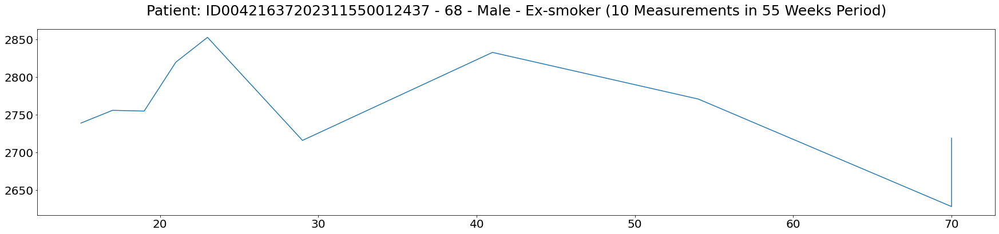

Patient: ID00422637202311677017371 FVC Statistical Summary
----------------------------------------------------------
Mean: 1885.88  -  Median: 1913.5  -  Std: 80.0597
Min: 1713 -  Max: 1955
Skew: -1.66055  -  Kurtosis: 2.95789
Change Mean: 66.1429  - Change Median: 49.0  - Change Std: 50.4659
Change Min: 6.0 -  Change Max: 149.0
Change Skew: 0.563408 -  Change Kurtosis: -0.492009


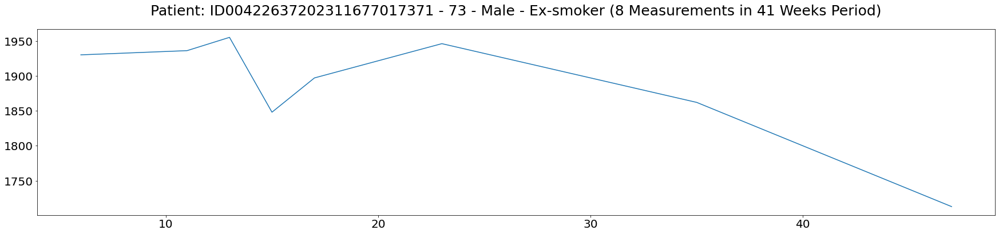

Patient: ID00423637202312137826377 FVC Statistical Summary
----------------------------------------------------------
Mean: 2750.0  -  Median: 2700.0  -  Std: 265.29
Min: 2432 -  Max: 3294
Skew: 1.10646  -  Kurtosis: 1.19357
Change Mean: 233.75  - Change Median: 204.0  - Change Std: 155.846
Change Min: 77.0 -  Change Max: 517.0
Change Skew: 0.779172 -  Change Kurtosis: -0.231173


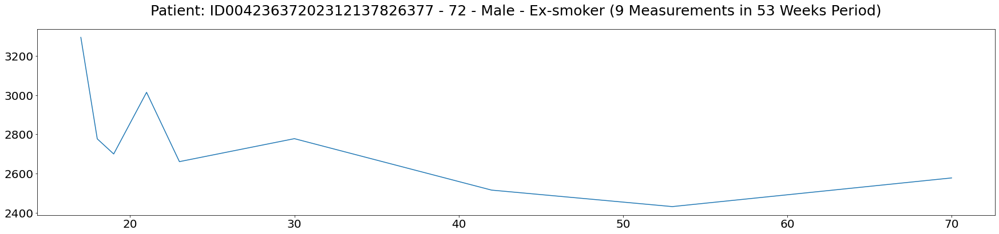

Patient: ID00426637202313170790466 FVC Statistical Summary
----------------------------------------------------------
Mean: 2896.33  -  Median: 2916.0  -  Std: 93.2322
Min: 2712 -  Max: 2978
Skew: -1.29381  -  Kurtosis: 0.754953
Change Mean: 120.375  - Change Median: 68.5  - Change Std: 105.947
Change Min: 13.0 -  Change Max: 266.0
Change Skew: 0.622254 -  Change Kurtosis: -1.71102


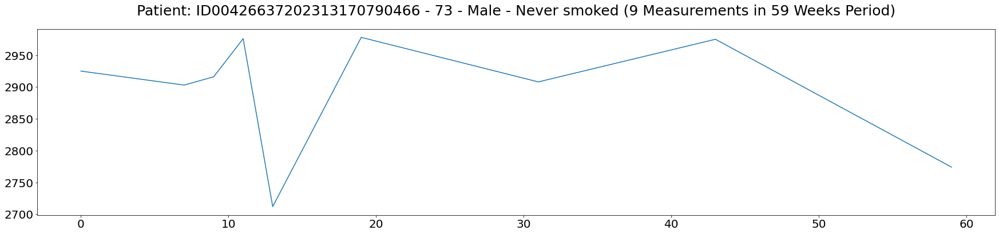

In [9]:
def plot_fvc(df, patient):
        
    df[['Weeks', 'FVC']].set_index('Weeks').plot(figsize=(30, 6), label='_nolegend_')
    
    plt.tick_params(axis='x', labelsize=20)
    plt.tick_params(axis='y', labelsize=20)
    plt.xlabel('')
    plt.ylabel('')
    plt.title(f'Patient: {patient} - {df["Age"].tolist()[0]} - {df["Sex"].tolist()[0]} - {df["SmokingStatus"].tolist()[0]} ({len(df)} Measurements in {(df["Weeks"].max() - df["Weeks"].min())} Weeks Period)', size=25, pad=25)
    plt.legend().set_visible(False)
    plt.show()

for patient, df in list(df_train.groupby('Patient')):
    
    df['FVC_diff-1'] = np.abs(df['FVC'].diff(-1))
    
    print(f'Patient: {patient} FVC Statistical Summary\n{"-" * 58}')
    print(f'Mean: {df["FVC"].mean():.6}  -  Median: {df["FVC"].median():.6}  -  Std: {df["FVC"].std():.6}')
    print(f'Min: {df["FVC"].min()} -  Max: {df["FVC"].max()}')
    print(f'Skew: {df["FVC"].skew():.6}  -  Kurtosis: {df["FVC"].kurtosis():.6}')
    print(f'Change Mean: {df["FVC_diff-1"].mean():.6}  - Change Median: {df["FVC_diff-1"].median():.6}  - Change Std: {df["FVC_diff-1"].std():.6}')
    print(f'Change Min: {df["FVC_diff-1"].min()} -  Change Max: {df["FVC_diff-1"].max()}')
    print(f'Change Skew: {df["FVC_diff-1"].skew():.6} -  Change Kurtosis: {df["FVC_diff-1"].kurtosis():.6}')
    
    plot_fvc(df, patient)

In [10]:
# Tabular Data

# There are four continuous features along with `FVC` in tabular data. Those features are:

# * `Weeks`: The relative number of weeks pre/post the baseline CT (may be negative). It doesn't have any significant relationship with other features because patients got both better or worse over the course of time regardless of their `Age`.
# * `Percent`: A computed field which approximates the patient's `FVC` as a percent of the typical `FVC` for a person of similar characteristics. This feature has a strong relationship with `FVC` because it is derived from it, but it doesn't have any significant relationship with other features.
# * `Age`: Age of the patient. `Age` has a slight relationship with `FVC` and `Percent` since younger patients have higher lung capacity.

# Distributions of `FVC`, `Percent` and `Age` are very similar but `Weeks` is different than those features.

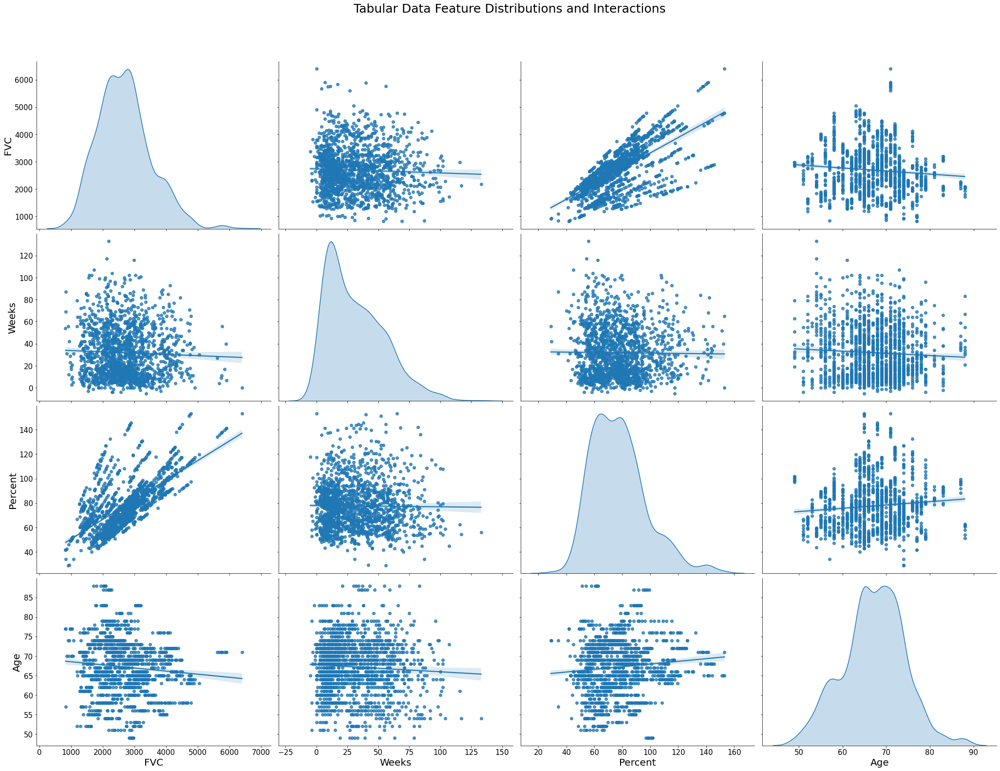

In [11]:
g = sns.pairplot(df_train[['FVC', 'Weeks', 'Percent', 'Age']], aspect=1.4, height=5, diag_kind='kde', kind='reg')

g.axes[3, 0].set_xlabel('FVC', fontsize=20)
g.axes[3, 1].set_xlabel('Weeks', fontsize=20)
g.axes[3, 2].set_xlabel('Percent', fontsize=20)
g.axes[3, 3].set_xlabel('Age', fontsize=20)
g.axes[0, 0].set_ylabel('FVC', fontsize=20)
g.axes[1, 0].set_ylabel('Weeks', fontsize=20)
g.axes[2, 0].set_ylabel('Percent', fontsize=20)
g.axes[3, 0].set_ylabel('Age', fontsize=20)

g.axes[3, 0].tick_params(axis='x', labelsize=15)
g.axes[3, 1].tick_params(axis='x', labelsize=15)
g.axes[3, 2].tick_params(axis='x', labelsize=15)
g.axes[3, 3].tick_params(axis='x', labelsize=15)
g.axes[0, 0].tick_params(axis='y', labelsize=15)
g.axes[1, 0].tick_params(axis='y', labelsize=15)
g.axes[2, 0].tick_params(axis='y', labelsize=15)
g.axes[3, 0].tick_params(axis='y', labelsize=15)

g.fig.suptitle('Tabular Data Feature Distributions and Interactions', fontsize=25, y=1.08)

plt.show()

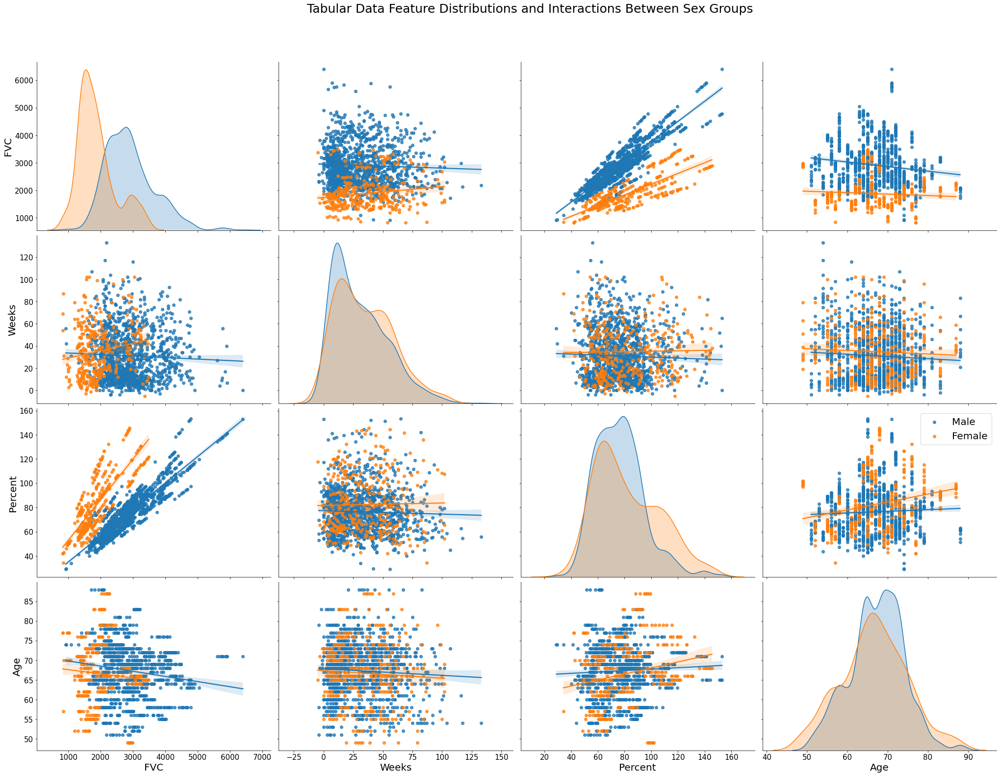

In [12]:
# The first categorical feature in tabular data is `Sex` which is basically gender of the patient.

# * `FVC` distributions of males and females are very different from each other. Females have lower lung capacity compared to males due to genetics. `FVC` relationships with other features are also very different for males and females. `FVC` of males have a stronger relationship with `Percent` and `Age` compared to `FVC` of females.
# * Comparing `Weeks` for different genders is not logical but females have a decent `FVC` improvement over the course weeks compared to males.
# * `Percent` distributions of males and females are very different from each other just like `FVC` distributions because `Percent` is derived from it.
# * `Age` has no differences between males and females in terms of relationships and distributions except female's `Age` distribution have slightly longer tails and a shorter peak.
g = sns.pairplot(df_train[['FVC', 'Weeks', 'Percent', 'Age', 'Sex']], hue='Sex', aspect=1.4, height=5, diag_kind='kde', kind='reg')

g.axes[3, 0].set_xlabel('FVC', fontsize=20)
g.axes[3, 1].set_xlabel('Weeks', fontsize=20)
g.axes[3, 2].set_xlabel('Percent', fontsize=20)
g.axes[3, 3].set_xlabel('Age', fontsize=20)
g.axes[0, 0].set_ylabel('FVC', fontsize=20)
g.axes[1, 0].set_ylabel('Weeks', fontsize=20)
g.axes[2, 0].set_ylabel('Percent', fontsize=20)
g.axes[3, 0].set_ylabel('Age', fontsize=20)

g.axes[3, 0].tick_params(axis='x', labelsize=15)
g.axes[3, 1].tick_params(axis='x', labelsize=15)
g.axes[3, 2].tick_params(axis='x', labelsize=15)
g.axes[3, 3].tick_params(axis='x', labelsize=15)
g.axes[0, 0].tick_params(axis='y', labelsize=15)
g.axes[1, 0].tick_params(axis='y', labelsize=15)
g.axes[2, 0].tick_params(axis='y', labelsize=15)
g.axes[3, 0].tick_params(axis='y', labelsize=15)

plt.legend(prop={'size': 20})
g._legend.remove()
g.fig.suptitle('Tabular Data Feature Distributions and Interactions Between Sex Groups', fontsize=25, y=1.08)

plt.show()

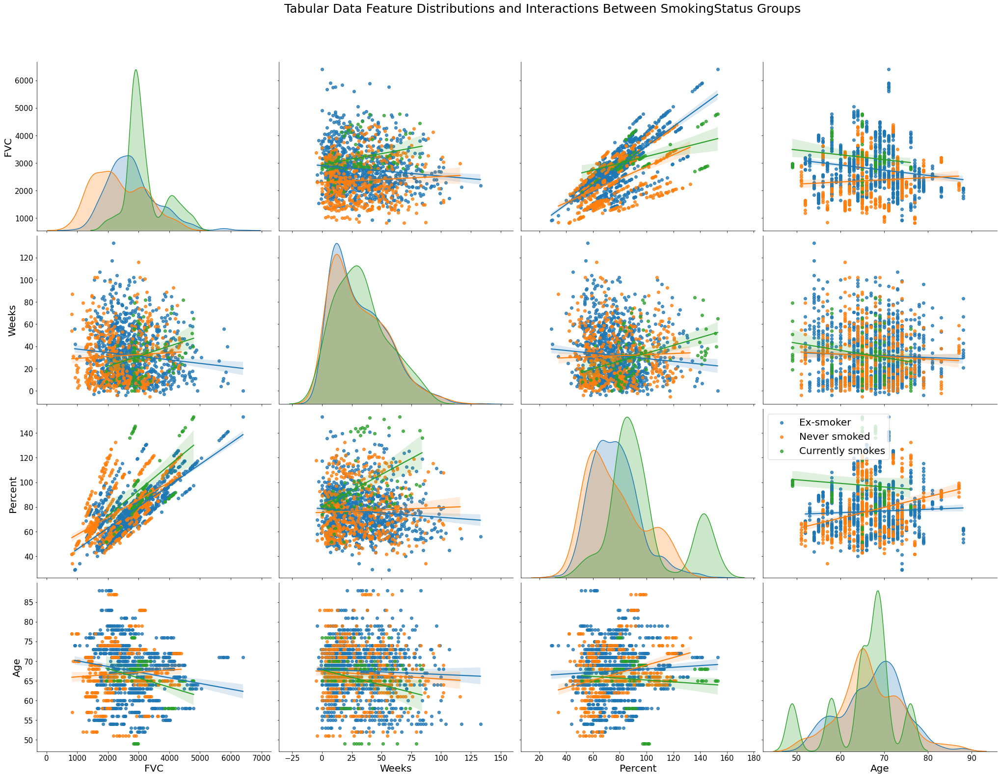

In [13]:
# The second categorical feature in tabular data is `SmokingStatus` which is also self-explanatory.

# * `FVC` distributions of `SmokingStatus` groups are quite unexpected. Mean `FVC` of smokers is  higher than mean `FVC` of ex-smokers and patients who had never smoked.
# * Distribution of `Weeks` is similar for different `SmokingStatus`. Smokers have the strongest positive linear relationship between `FVC` and `Weeks` which is also another unexpected phenomenon.
# * `Percent` distributions of different `SmokingStatus` groups is very similar to `FVC` distributions but peaks are taller. The linear relationship between `Percent` and `Weeks` is also stronger compared to `FVC` and `Weeks`.
# * `Age` has no relationship with `SmokingStatus`.
g = sns.pairplot(df_train[['FVC', 'Weeks', 'Percent', 'Age', 'SmokingStatus']], hue='SmokingStatus', aspect=1.4, height=5, diag_kind='kde', kind='reg')

g.axes[3, 0].set_xlabel('FVC', fontsize=20)
g.axes[3, 1].set_xlabel('Weeks', fontsize=20)
g.axes[3, 2].set_xlabel('Percent', fontsize=20)
g.axes[3, 3].set_xlabel('Age', fontsize=20)
g.axes[0, 0].set_ylabel('FVC', fontsize=20)
g.axes[1, 0].set_ylabel('Weeks', fontsize=20)
g.axes[2, 0].set_ylabel('Percent', fontsize=20)
g.axes[3, 0].set_ylabel('Age', fontsize=20)

g.axes[3, 0].tick_params(axis='x', labelsize=15)
g.axes[3, 1].tick_params(axis='x', labelsize=15)
g.axes[3, 2].tick_params(axis='x', labelsize=15)
g.axes[3, 3].tick_params(axis='x', labelsize=15)
g.axes[0, 0].tick_params(axis='y', labelsize=15)
g.axes[1, 0].tick_params(axis='y', labelsize=15)
g.axes[2, 0].tick_params(axis='y', labelsize=15)
g.axes[3, 0].tick_params(axis='y', labelsize=15)

plt.legend(prop={'size': 20})
g._legend.remove()
g.fig.suptitle('Tabular Data Feature Distributions and Interactions Between SmokingStatus Groups', fontsize=25, y=1.08)

plt.show()

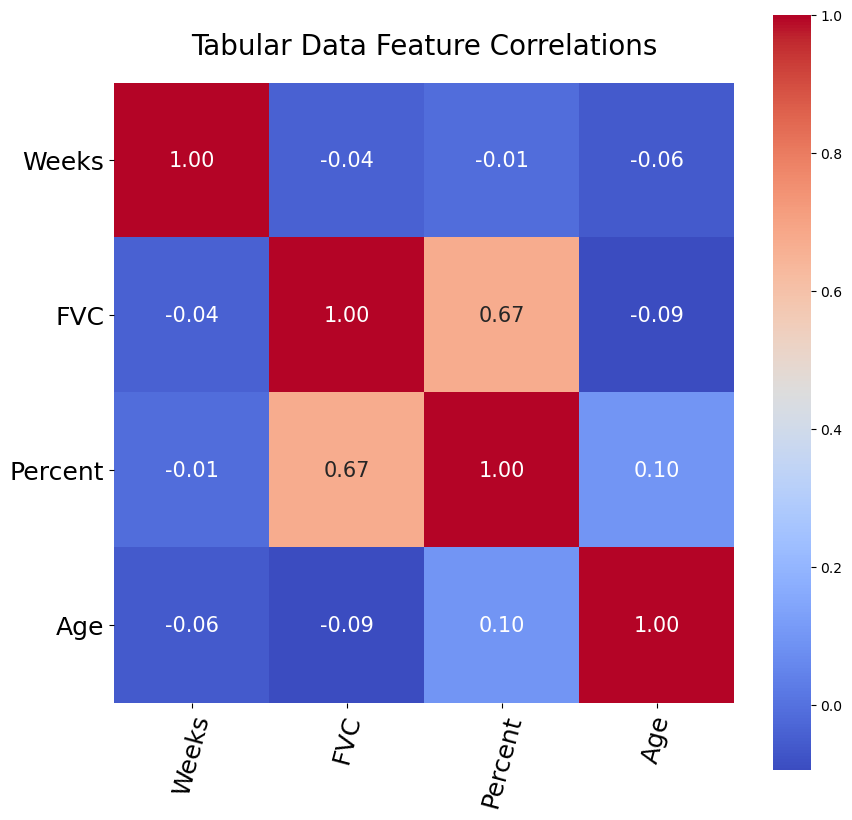

In [14]:
# As seen from the plots above, the only strong correlation is between FVC and Percent. The other features' correlations are between -0.1 and 0.1.
fig = plt.figure(figsize=(10, 10), dpi=100)

sns.heatmap(df_train.corr(), annot=True, square=True, cmap='coolwarm', annot_kws={'size': 15},  fmt='.2f')   

plt.tick_params(axis='x', labelsize=18, rotation=75)
plt.tick_params(axis='y', labelsize=18, rotation=0)
plt.title('Tabular Data Feature Correlations', size=20, pad=20)

plt.show()

### ------------------------END OSIC Pulmonary Fibrosis Progression Analysis-----------------------------------

# FIRST OSIC Pulmonary Fibrosis Progression

## Import Libraries

In [15]:
import os
import numpy as np
import pandas as pd
import random
import math

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GroupKFold, KFold
from sklearn.metrics import mean_squared_error
import category_encoders as ce

from sklearn.linear_model import Ridge, ElasticNet
from functools import partial
import scipy as sp

import warnings
warnings.filterwarnings("ignore")

## Utilities 

In [16]:
def seed_everything(seed=777):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

## Configuration

In [17]:
OUTPUT_DICT = './'

ID = 'Patient_Week'
TARGET = 'FVC'
SEED = 777
seed_everything(seed=SEED)

N_FOLD = 7

## Load Train and Test Data

In [18]:
train = pd.read_csv('../input/osic-pulmonary-fibrosis-progression/train.csv')
otest = pd.read_csv('../input/osic-pulmonary-fibrosis-progression/test.csv')

### construct train input

In [19]:
# construct train input
train = pd.concat([train,otest])
output = pd.DataFrame()
gb = train.groupby('Patient')
tk0 = tqdm(gb, total=len(gb))
for _, usr_df in tk0:
    usr_output = pd.DataFrame()
    for week, tmp in usr_df.groupby('Weeks'):
        rename_cols = {'Weeks': 'base_Week', 'FVC': 'base_FVC', 'Age': 'base_Age'}
        tmp = tmp.rename(columns=rename_cols)
        drop_cols = ['Age', 'Sex', 'SmokingStatus', 'Percent']
        _usr_output = usr_df.drop(columns=drop_cols).rename(columns={'Weeks': 'predict_Week'}).merge(tmp, on='Patient')
        _usr_output['Week_passed'] = _usr_output['predict_Week'] - _usr_output['base_Week']
        usr_output = pd.concat([usr_output, _usr_output])
    output = pd.concat([output, usr_output])
    
train = output[output['Week_passed']!=0].reset_index(drop=True)

### construct test input

In [20]:
# construct test input
test = otest.rename(columns={'Weeks': 'base_Week', 'FVC': 'base_FVC', 'Age': 'base_Age'})
submission = pd.read_csv('../input/osic-pulmonary-fibrosis-progression/sample_submission.csv')
submission['Patient'] = submission['Patient_Week'].apply(lambda x: x.split('_')[0])
submission['predict_Week'] = submission['Patient_Week'].apply(lambda x: x.split('_')[1]).astype(int)
test = submission.drop(columns=['FVC', 'Confidence']).merge(test, on='Patient')
test['Week_passed'] = test['predict_Week'] - test['base_Week']
test.set_index('Patient_Week', inplace=True)

### Divide the dataset in some fold for cross validation

In [21]:
folds = train[['Patient', TARGET]].copy()
Fold = GroupKFold(n_splits=N_FOLD)
groups = folds['Patient'].values
for n, (train_index, val_index) in enumerate(Fold.split(folds, folds[TARGET], groups)):
    folds.loc[val_index, 'fold'] = int(n)
folds['fold'] = folds['fold'].astype(int)

## Data Modeling

In [22]:
#===========================================================
# model
#===========================================================
def run_single_model(clf, train_df, test_df, folds, features, target, fold_num=0):
    
    trn_idx = folds[folds.fold!=fold_num].index
    val_idx = folds[folds.fold==fold_num].index
    
    y_tr = target.iloc[trn_idx].values
    X_tr = train_df.iloc[trn_idx][features].values
    y_val = target.iloc[val_idx].values
    X_val = train_df.iloc[val_idx][features].values
    
    oof = np.zeros(len(train_df))
    predictions = np.zeros(len(test_df))
    clf.fit(X_tr, y_tr)
    
    oof[val_idx] = clf.predict(X_val)
    predictions += clf.predict(test_df[features])
    return oof, predictions


def run_kfold_model(clf, train, test, folds, features, target, n_fold=7):
    
    oof = np.zeros(len(train))
    predictions = np.zeros(len(test))
    feature_importance_df = pd.DataFrame()

    for fold_ in range(n_fold):

        _oof, _predictions = run_single_model(clf,
                                              train, 
                                              test,
                                              folds,  
                                              features,
                                              target, 
                                              fold_num=fold_)
        oof += _oof
        predictions += _predictions/n_fold
    
    return oof, predictions

## Predict Dataset

In [23]:
target = train[TARGET]
test[TARGET] = np.nan

# features
cat_features = ['Sex', 'SmokingStatus']
num_features = [c for c in test.columns if (test.dtypes[c] != 'object') & (c not in cat_features)]
features = num_features + cat_features
drop_features = [TARGET, 'predict_Week', 'Percent', 'base_Week']
features = [c for c in features if c not in drop_features]

if cat_features:
    ce_oe = ce.OrdinalEncoder(cols=cat_features, handle_unknown='impute')
    ce_oe.fit(train)
    train = ce_oe.transform(train)
    test = ce_oe.transform(test)

## Model Training


In [24]:
'''for alpha1 in (1,0.3,0.1,0.03,0.01):
    for l1s in (0.01,0.03,0.1,0.2,0.5,0.8,0.9,0.97,0.99):
        
        print(" For alpha:",alpha1,"& l1_ratio:",l1s)
        clf = ElasticNet(alpha=alpha1, l1_ratio = l1s)
        oof, predictions = run_kfold_model(clf, train, test, folds, features, target, n_fold=N_FOLD)

        train['FVC_pred'] = oof
        test['FVC_pred'] = predictions

        # baseline score
        train['Confidence'] = 100
        train['sigma_clipped'] = train['Confidence'].apply(lambda x: max(x, 70))
        train['diff'] = abs(train['FVC'] - train['FVC_pred'])
        train['delta'] = train['diff'].apply(lambda x: min(x, 1000))
        train['score'] = -math.sqrt(2)*train['delta']/train['sigma_clipped'] - np.log(math.sqrt(2)*train['sigma_clipped'])
        score = train['score'].mean()
        print(score)

        def loss_func(weight, row):
            confidence = weight
            sigma_clipped = max(confidence, 70)
            diff = abs(row['FVC'] - row['FVC_pred'])
            delta = min(diff, 1000)
            score = -math.sqrt(2)*delta/sigma_clipped - np.log(math.sqrt(2)*sigma_clipped)
            return -score

        results = []
        tk0 = tqdm(train.iterrows(), total=len(train))
        for _, row in tk0:
            loss_partial = partial(loss_func, row=row)
            weight = [100]
            result = sp.optimize.minimize(loss_partial, weight, method='SLSQP')
            x = result['x']
            results.append(x[0])

        # optimized score
        train['Confidence'] = results
        train['sigma_clipped'] = train['Confidence'].apply(lambda x: max(x, 70))
        train['diff'] = abs(train['FVC'] - train['FVC_pred'])
        train['delta'] = train['diff'].apply(lambda x: min(x, 1000))
        train['score'] = -math.sqrt(2)*train['delta']/train['sigma_clipped'] - np.log(math.sqrt(2)*train['sigma_clipped'])
        score = train['score'].mean()
        print(score)'''

'for alpha1 in (1,0.3,0.1,0.03,0.01):\n    for l1s in (0.01,0.03,0.1,0.2,0.5,0.8,0.9,0.97,0.99):\n        \n        print(" For alpha:",alpha1,"& l1_ratio:",l1s)\n        clf = ElasticNet(alpha=alpha1, l1_ratio = l1s)\n        oof, predictions = run_kfold_model(clf, train, test, folds, features, target, n_fold=N_FOLD)\n\n        train[\'FVC_pred\'] = oof\n        test[\'FVC_pred\'] = predictions\n\n        # baseline score\n        train[\'Confidence\'] = 100\n        train[\'sigma_clipped\'] = train[\'Confidence\'].apply(lambda x: max(x, 70))\n        train[\'diff\'] = abs(train[\'FVC\'] - train[\'FVC_pred\'])\n        train[\'delta\'] = train[\'diff\'].apply(lambda x: min(x, 1000))\n        train[\'score\'] = -math.sqrt(2)*train[\'delta\']/train[\'sigma_clipped\'] - np.log(math.sqrt(2)*train[\'sigma_clipped\'])\n        score = train[\'score\'].mean()\n        print(score)\n\n        def loss_func(weight, row):\n            confidence = weight\n            sigma_clipped = max(confide

In [25]:
for alpha1 in [0.3]:
    for l1s in [0.8]:
        
        print(" For alpha:",alpha1,"& l1_ratio:",l1s)
        clf = ElasticNet(alpha=alpha1, l1_ratio = l1s)
        oof, predictions = run_kfold_model(clf, train, test, folds, features, target, n_fold=N_FOLD)

        train['FVC_pred'] = oof
        test['FVC_pred'] = predictions

        # baseline score
        train['Confidence'] = 100
        train['sigma_clipped'] = train['Confidence'].apply(lambda x: max(x, 70))
        train['diff'] = abs(train['FVC'] - train['FVC_pred'])
        train['delta'] = train['diff'].apply(lambda x: min(x, 1000))
        train['score'] = -math.sqrt(2)*train['delta']/train['sigma_clipped'] - np.log(math.sqrt(2)*train['sigma_clipped'])
        score = train['score'].mean()
        print(score)

        def loss_func(weight, row):
            confidence = weight
            sigma_clipped = max(confidence, 70)
            diff = abs(row['FVC'] - row['FVC_pred'])
            delta = min(diff, 1000)
            score = -math.sqrt(2)*delta/sigma_clipped - np.log(math.sqrt(2)*sigma_clipped)
            return -score

        results = []
        tk0 = tqdm(train.iterrows(), total=len(train))
        for _, row in tk0:
            loss_partial = partial(loss_func, row=row)
            weight = [100]
            result = sp.optimize.minimize(loss_partial, weight, method='SLSQP')
            x = result['x']
            results.append(x[0])

        # optimized score
        train['Confidence'] = results
        train['sigma_clipped'] = train['Confidence'].apply(lambda x: max(x, 70))
        train['diff'] = abs(train['FVC'] - train['FVC_pred'])
        train['delta'] = train['diff'].apply(lambda x: min(x, 1000))
        train['score'] = -math.sqrt(2)*train['delta']/train['sigma_clipped'] - np.log(math.sqrt(2)*train['sigma_clipped'])
        score = train['score'].mean()
        print(score)

 For alpha: 0.3 & l1_ratio: 0.8
-7.1348753816458785



-6.3371767269142065


## Predict Confidence

In [26]:
TARGET = 'Confidence'

target = train[TARGET]
test[TARGET] = np.nan

# features
cat_features = ['Sex', 'SmokingStatus']
num_features = [c for c in test.columns if (test.dtypes[c] != 'object') & (c not in cat_features)]
features = num_features + cat_features
drop_features = [ID, TARGET, 'predict_Week', 'base_Week', 'FVC', 'FVC_pred']
features = [c for c in features if c not in drop_features]

oof, predictions = run_kfold_model(clf, train, test, folds, features, target, n_fold=N_FOLD)

In [27]:
train['Confidence'] = oof
train['sigma_clipped'] = train['Confidence'].apply(lambda x: max(x, 70))
train['diff'] = abs(train['FVC'] - train['FVC_pred'])
train['delta'] = train['diff'].apply(lambda x: min(x, 1000))
train['score'] = -math.sqrt(2)*train['delta']/train['sigma_clipped'] - np.log(math.sqrt(2)*train['sigma_clipped'])
score = train['score'].mean()
print(score)

-6.731467164319431


In [28]:
test['Confidence'] = predictions
test = test.reset_index()

##  Submission Data Processing

In [29]:
sub = submission[['Patient_Week']].merge(test[['Patient_Week', 'FVC_pred', 'Confidence']], on='Patient_Week')
sub = sub.rename(columns={'FVC_pred': 'FVC'})

for i in range(len(otest)):
    sub.loc[sub['Patient_Week']==otest.Patient[i]+'_'+str(otest.Weeks[i]), 'FVC'] = otest.FVC[i]
    sub.loc[sub['Patient_Week']==otest.Patient[i]+'_'+str(otest.Weeks[i]), 'Confidence'] = 0.1
    
sub[sub.Confidence<1]

sub.to_csv('submission_2.csv', index=False, float_format='%.1f')

### -------------------END FIRST OSIC Pulmonary Fibrosis Progression-----------------------

# Another Way for OSIC Pulmonary Fibrosis Progression

In [30]:
import numpy as np
import pandas as pd
import pydicom
import os
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold

In [31]:
ROOT = "../input/osic-pulmonary-fibrosis-progression"
#DESIRED_SIZE = 256 # Memory issue
DESIRED_SIZE = 128

In [32]:
tr = pd.read_csv(f"{ROOT}/train.csv")
tr.drop_duplicates(keep=False, inplace=True, subset=['Patient','Weeks'])
chunk = pd.read_csv(f"{ROOT}/test.csv")

print("add infos")
sub = pd.read_csv(f"{ROOT}/sample_submission.csv")
sub['Patient'] = sub['Patient_Week'].apply(lambda x:x.split('_')[0])
sub['Weeks'] = sub['Patient_Week'].apply(lambda x: int(x.split('_')[-1]))
sub =  sub[['Patient','Weeks','Confidence','Patient_Week']]
sub = sub.merge(chunk.drop('Weeks', axis=1), on="Patient")

add infos


In [33]:
tr['WHERE'] = 'train'
chunk['WHERE'] = 'val'
sub['WHERE'] = 'test'
data = tr.append([chunk, sub])

In [34]:
print(tr.shape, chunk.shape, sub.shape, data.shape)
print(tr.Patient.nunique(), chunk.Patient.nunique(), sub.Patient.nunique(), 
      data.Patient.nunique())

(1535, 8) (5, 8) (730, 10) (2270, 10)
176 5 5 176


In [35]:
data['min_week'] = data['Weeks']
data.loc[data.WHERE=='test','min_week'] = np.nan
data['min_week'] = data.groupby('Patient')['min_week'].transform('min')

In [36]:
base = data.loc[data.Weeks == data.min_week]
base = base[['Patient','FVC']].copy()
base.columns = ['Patient','min_FVC']
base['nb'] = 1
base['nb'] = base.groupby('Patient')['nb'].transform('cumsum')
base = base[base.nb==1]
base.drop('nb', axis=1, inplace=True)

In [37]:
data = data.merge(base, on='Patient', how='left')
data['base_week'] = data['Weeks'] - data['min_week']
del base

In [38]:
COLS = ['Sex','SmokingStatus']
FE = []
for col in COLS:
    for mod in data[col].unique():
        FE.append(mod)
        data[mod] = (data[col] == mod).astype(int)

In [39]:
data['age'] = (data['Age'] - data['Age'].min() ) / ( data['Age'].max() - data['Age'].min() )
data['BASE'] = (data['min_FVC'] - data['min_FVC'].min() ) / ( data['min_FVC'].max() - data['min_FVC'].min() )
data['week'] = (data['base_week'] - data['base_week'].min() ) / ( data['base_week'].max() - data['base_week'].min() )
data['percent'] = (data['Percent'] - data['Percent'].min() ) / ( data['Percent'].max() - data['Percent'].min() )
FE += ['age','percent','week','BASE']

In [40]:
tr = data.loc[data.WHERE=='train']
chunk = data.loc[data.WHERE=='val']
sub = data.loc[data.WHERE=='test']
del data

In [41]:
tr.shape, chunk.shape, sub.shape

((1535, 22), (5, 22), (730, 22))

## Image Processing

In [42]:
def get_images(df, how="train"):
    xo = []
    p = []
    w  = []
    for i in tqdm(range(df.shape[0])):
        patient = df.iloc[i,0]
        week = df.iloc[i,1]
        try:
            img_path = f"{ROOT}/{how}/{patient}/{week}.dcm"
            ds = pydicom.dcmread(img_path)
            im = Image.fromarray(ds.pixel_array)
            im = im.resize((DESIRED_SIZE,DESIRED_SIZE)) 
            im = np.array(im)
            xo.append(im[np.newaxis,:,:])
            p.append(patient)
            w.append(week)
        except:
            pass
    data = pd.DataFrame({"Patient":p,"Weeks":w})
    return np.concatenate(xo, axis=0), data

## BUILD BASELINE CNN

In [43]:
import tensorflow as tf
import tensorflow.keras.backend as K
import tensorflow.keras.layers as L
import tensorflow.keras.models as M

In [44]:
C1, C2 = tf.constant(70, dtype='float32'), tf.constant(1000, dtype="float32")
#=============================#
def score(y_true, y_pred):
    tf.dtypes.cast(y_true, tf.float32)
    tf.dtypes.cast(y_pred, tf.float32)
    sigma = y_pred[:, 2] - y_pred[:, 0]
    fvc_pred = y_pred[:, 1]
    
    #sigma_clip = sigma + C1
    sigma_clip = tf.maximum(sigma, C1)
    delta = tf.abs(y_true[:, 0] - fvc_pred)
    delta = tf.minimum(delta, C2)
    sq2 = tf.sqrt( tf.dtypes.cast(2, dtype=tf.float32) )
    metric = (delta / sigma_clip)*sq2 + tf.math.log(sigma_clip* sq2)
    return K.mean(metric)
#============================#
def qloss(y_true, y_pred):
    # Pinball loss for multiple quantiles
    qs = [0.2, 0.50, 0.8]
    q = tf.constant(np.array([qs]), dtype=tf.float32)
    e = y_true - y_pred
    v = tf.maximum(q*e, (q-1)*e)
    return K.mean(v)
#=============================#
def mloss(_lambda):
    def loss(y_true, y_pred):
        return _lambda * qloss(y_true, y_pred) + (1 - _lambda)*score(y_true, y_pred)
    return loss
#=================
def make_model():
    z = L.Input((9,), name="Patient")
    x = L.Dense(100, activation="relu", name="d1")(z)
    x = L.Dense(100, activation="relu", name="d2")(x)
    #x = L.Dense(100, activation="relu", name="d3")(x)
    p1 = L.Dense(3, activation="linear", name="p1")(x)
    p2 = L.Dense(3, activation="relu", name="p2")(x)
    preds = L.Lambda(lambda x: x[0] + tf.cumsum(x[1], axis=1), 
                     name="preds")([p1, p2])
    
    model = M.Model(z, preds, name="CNN")
    #model.compile(loss=qloss, optimizer="adam", metrics=[score])
    model.compile(loss=mloss(0.8), optimizer="adam", metrics=[score])
    return model

In [45]:
net = make_model()
print(net.summary())
print(net.count_params())

Model: "CNN"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
Patient (InputLayer)            [(None, 9)]          0                                            
__________________________________________________________________________________________________
d1 (Dense)                      (None, 100)          1000        Patient[0][0]                    
__________________________________________________________________________________________________
d2 (Dense)                      (None, 100)          10100       d1[0][0]                         
__________________________________________________________________________________________________
p1 (Dense)                      (None, 3)            303         d2[0][0]                         
________________________________________________________________________________________________

In [46]:
y = tr['FVC'].values
z = tr[FE].values
ze = sub[FE].values
pe = np.zeros((ze.shape[0], 3))
pred = np.zeros((z.shape[0], 3))

In [47]:
NFOLD = 7
kf = KFold(n_splits=NFOLD)

In [48]:
%%time
cnt = 0
for tr_idx, val_idx in kf.split(z):
    cnt += 1
    print(f"FOLD {cnt}")
    net = make_model()
    net.fit(z[tr_idx], y[tr_idx], batch_size=200, epochs=1000, 
            validation_data=(z[val_idx], y[val_idx]), verbose=0) #
    print("train", net.evaluate(z[tr_idx], y[tr_idx], verbose=0, batch_size=500))
    print("val", net.evaluate(z[val_idx], y[val_idx], verbose=0, batch_size=500))
    print("predict val...")
    pred[val_idx] = net.predict(z[val_idx], batch_size=500, verbose=0)
    print("predict test...")
    pe += net.predict(ze, batch_size=500, verbose=0) / NFOLD

FOLD 1
train [42.03571319580078, 6.542195796966553]
val [46.4308967590332, 6.624298572540283]
predict val...
predict test...
FOLD 2
train [41.56827926635742, 6.5312018394470215]
val [53.69628143310547, 6.756362438201904]
predict val...
predict test...
FOLD 3
train [43.36965560913086, 6.5778117179870605]
val [41.070709228515625, 6.556644439697266]
predict val...
predict test...
FOLD 4
train [40.962791442871094, 6.516639709472656]
val [57.45888900756836, 6.86264181137085]
predict val...
predict test...
FOLD 5
train [44.83163070678711, 6.616901874542236]
val [44.227352142333984, 6.592482566833496]
predict val...
predict test...
FOLD 6
train [42.52091598510742, 6.551517963409424]
val [46.05078887939453, 6.586946964263916]
predict val...
predict test...
FOLD 7
train [42.500022888183594, 6.545248508453369]
val [44.43593978881836, 6.616133689880371]
predict val...
predict test...
CPU times: user 5min 50s, sys: 19.8 s, total: 6min 10s
Wall time: 5min 30s


In [49]:
sigma_opt = mean_absolute_error(y, pred[:, 1])
unc = pred[:,2] - pred[:, 0]
sigma_mean = np.mean(unc)
print(sigma_opt, sigma_mean)

139.86755685216053 239.10112650619655


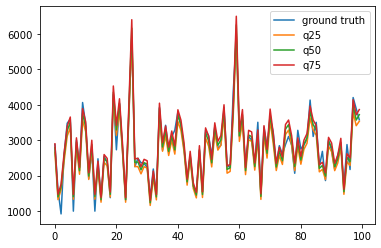

In [50]:
idxs = np.random.randint(0, y.shape[0], 100)
plt.plot(y[idxs], label="ground truth")
plt.plot(pred[idxs, 0], label="q25")
plt.plot(pred[idxs, 1], label="q50")
plt.plot(pred[idxs, 2], label="q75")
plt.legend(loc="best")
plt.show()

In [51]:
print(unc.min(), unc.mean(), unc.max(), (unc>=0).mean())

86.80340576171875 239.10112650619655 509.439453125 1.0


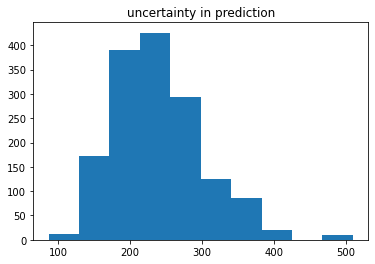

In [52]:
plt.hist(unc)
plt.title("uncertainty in prediction")
plt.show()

In [53]:
sub.head()

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus,WHERE,Confidence,Patient_Week,min_week,min_FVC,base_week,Male,Female,Ex-smoker,Never smoked,Currently smokes,age,BASE,week,percent
1540,ID00419637202311204720264,-12,3020,70.186855,73,Male,Ex-smoker,test,100.0,ID00419637202311204720264_-12,6.0,3020,-18.0,1,0,1,0,0,0.615385,0.3724,0.067901,0.332421
1541,ID00419637202311204720264,-11,3020,70.186855,73,Male,Ex-smoker,test,100.0,ID00419637202311204720264_-11,6.0,3020,-17.0,1,0,1,0,0,0.615385,0.3724,0.074074,0.332421
1542,ID00419637202311204720264,-10,3020,70.186855,73,Male,Ex-smoker,test,100.0,ID00419637202311204720264_-10,6.0,3020,-16.0,1,0,1,0,0,0.615385,0.3724,0.080247,0.332421
1543,ID00419637202311204720264,-9,3020,70.186855,73,Male,Ex-smoker,test,100.0,ID00419637202311204720264_-9,6.0,3020,-15.0,1,0,1,0,0,0.615385,0.3724,0.086420,0.332421
1544,ID00419637202311204720264,-8,3020,70.186855,73,Male,Ex-smoker,test,100.0,ID00419637202311204720264_-8,6.0,3020,-14.0,1,0,1,0,0,0.615385,0.3724,0.092593,0.332421


In [54]:
sub['FVC1'] = pe[:, 1]
sub['Confidence1'] = pe[:, 2] - pe[:, 0]

In [55]:
subm = sub[['Patient_Week','FVC','Confidence','FVC1','Confidence1']].copy()

In [56]:
subm.loc[~subm.FVC1.isnull()].head(10)

,Patient_Week,FVC,Confidence,FVC1,Confidence1
1540,ID00419637202311204720264_-12,3020,100.0,2885.341827,253.318054
1541,ID00419637202311204720264_-11,3020,100.0,2883.066376,253.175598
1542,ID00419637202311204720264_-10,3020,100.0,2880.790985,253.033478
1543,ID00419637202311204720264_-9,3020,100.0,2878.515442,252.891083
1544,ID00419637202311204720264_-8,3020,100.0,2876.239990,252.748840
1545,ID00419637202311204720264_-7,3020,100.0,2873.964600,252.606506
1546,ID00419637202311204720264_-6,3020,100.0,2871.689148,252.464233
1547,ID00419637202311204720264_-5,3020,100.0,2869.413635,252.321991
1548,ID00419637202311204720264_-4,3020,100.0,2867.138153,252.179718
1549,ID00419637202311204720264_-3,3020,100.0,2864.862732,252.037445


In [57]:
subm.loc[~subm.FVC1.isnull(),'FVC'] = subm.loc[~subm.FVC1.isnull(),'FVC1']
if sigma_mean<70:
    subm['Confidence'] = sigma_opt
else:
    subm.loc[~subm.FVC1.isnull(),'Confidence'] = subm.loc[~subm.FVC1.isnull(),'Confidence1']

In [58]:
subm.head()

,Patient_Week,FVC,Confidence,FVC1,Confidence1
1540,ID00419637202311204720264_-12,2885.341827,253.318054,2885.341827,253.318054
1541,ID00419637202311204720264_-11,2883.066376,253.175598,2883.066376,253.175598
1542,ID00419637202311204720264_-10,2880.790985,253.033478,2880.790985,253.033478
1543,ID00419637202311204720264_-9,2878.515442,252.891083,2878.515442,252.891083
1544,ID00419637202311204720264_-8,2876.239990,252.748840,2876.239990,252.748840


In [59]:
subm.describe().T

,count,mean,std,min,25%,50%,75%,max
FVC,730.0,2637.571524,348.695154,1881.760040,2568.668709,2701.389008,2836.07399,3219.970886
Confidence,730.0,234.803792,27.204787,177.006439,230.614418,239.932983,248.83036,278.050690
FVC1,730.0,2637.571524,348.695154,1881.760040,2568.668709,2701.389008,2836.07399,3219.970886
Confidence1,730.0,234.803792,27.204787,177.006439,230.614418,239.932983,248.83036,278.050690


In [60]:
subm[["Patient_Week","FVC","Confidence"]].to_csv("submission.csv", index=False)

### -------------------------END SECOND OSIC Pulmonary Fibrosis Progression------------------------------------